# An AI-Based Approach of Customer Data Segmentation Based on K-Means Clustering Algorithms
**Samuel Lim Wei Howe · Master of Data Science dissertation, HELP University (2023)**
Industry partner: a Malaysian health-products retailer (name withheld under NDA)

---
### About this notebook
I lost the original Jupyter notebook from my dissertation, so I rebuilt it from what survived: the code screenshots, outputs and text in my final report. I kept the report's section and figure numbers, so any cell can be checked against the page it came from.

Most of the code is copied straight from the screenshots: the language and state cleaning functions, the partial-duplicate detection, the RFM build, the scaling, the CHI/DBI search and the per-cluster Q-score functions. A few parts had to be worked out again:

* The quantile scoring rules used in §5.3 were not printed in the report. I rebuilt them from the scored rows that were, and they reproduce all 23 examples.
* The SKU rules in §5.4 were made of the partner's brand names. In this public version I use the product-line code instead (more on that in §5.4).
* `distributeBundleData()` (155 if-else rules) appears in neither the screenshots nor the outputs, so I could not rebuild it.
* The plot styling is approximated from the figures.

The original ran on Python 3.9.7 in 2022, and a few library changes since then needed small edits that keep the logic the same. `Series.append()` became `pd.concat`. Chained assignment such as `df.State[i] = x` became `df.loc[i, 'State'] = x`. `sns.distplot` became `sns.histplot`. I also set `n_init=10` in KMeans, which was the default back then.

Looking back, there are a few things in my original code I would do differently today. I kept them as they were so the notebook matches the dissertation, and I point them out where they come up:
1. Frequency counts invoice line rows per customer, not distinct invoices.
2. `Frequency_QScore` only gives a score of 2 when Frequency is exactly the 25th percentile.
3. KMeans had no `random_state`, so cluster sizes and numbering change from run to run. I mentioned this in §6.2 of the report.
4. The partial-duplicate check tests each column on its own within an invoice, rather than as one combined key.

### Data
The real dataset (62,766 transaction lines, 17 columns, 2017–2022) belonged to the partner. I no longer hold it, so this notebook runs on a synthetic look-alike. When no real file is present, the notebook generates a synthetic look-alike with the same structure, the same missing values, the same messy labels and the same 435 partial duplicates, so every cell still runs. Numbers from the synthetic data are not my dissertation results. Where it helps, I've added the published figures from my report for comparison.

### Keeping the data private
Because this notebook is public, the data is camouflaged straight after loading (§0.1), before anything is printed or plotted:

| Field | What I do to it | Why the analysis still works |
|---|---|---|
| `idMember` | replaced with an integer pseudonym (100001, 100002 … in a secret order) | joins, counts and RFM are unchanged |
| `Name`, `Contact`, `Email` | replaced with keyed tokens; missing values stay missing | the missing-value counts in §4.3.1 are unchanged |
| `Invoice` | replaced with a pseudonym such as `INV-P000123` | invoice grouping and duplicate detection are unchanged |
| `Joined_Date`, `Invoice_Date` | all of a customer's dates move by the same secret number of days (± 30) | gaps between purchases and tenure are unchanged |
| `DOB` | reduced to the first year of a 5-year band | not used in the analysis |
| `City` | tokenised, except a few country names the state-cleaning rules need | the state cleaning still works |
| `Profile_Type` | coded as `P01` … `P16` | product segmentation runs on the codes |
| `Item_Name` | coded as `ITEM-0001` / `BUNDLE-0001` | duplicate detection and bundle ranking are unchanged |
| `Amount` | each product's price multiplied by its own secret factor (0.6 – 1.6) | real prices can't be looked up; Monetary shifts consistently |
| `State` | cleaned first, then shown as Region A, Region B … | regional ranking and shares are kept |

With `MASK_BUSINESS_FIGURES = True`, the company's sales by region, unit volumes and bundle counts are shown as percentages rather than RM or units.

Two further rules apply to every output:
* **One-way pseudonyms.** The camouflage key is random and held only in memory, so nobody (including me) can turn a pseudonym back into a real customer.
* **No small groups.** Any group of fewer than `MIN_GROUP_SIZE` (5) customers is reported as a count only. Its customer rows and summary figures are suppressed, so no individual's behaviour can be read off.

One honest caveat: camouflage protects the customers, but the business still owns its data. Summary statistics like the RFM `describe()` would still reflect real volumes, so on real data I would publish aggregate figures only, never anything about a group of fewer than 5 customers.

> **About the outputs in this public copy:** every chart and table below comes from a run on the notebook's built-in **synthetic** dataset (same 62,766 × 17 structure, no real customers). They show that the code runs end to end; the numbers will not match the dissertation. The real, masked results are in [the dissertation summary PDF](Dissertation_Summary_Customer_Segmentation_CLTV.pdf) and the [README](README.md).

In [1]:
# ---------------- CONFIG ----------------
import os
DATA_PATH = os.path.expanduser("~/private_data/transactions.xlsx")   # raw export lives OUTSIDE the repo folder
USE_SYNTHETIC_IF_MISSING = True      # generate a synthetic stand-in if DATA_PATH does not exist
SYNTHETIC_PATH = "transactions_SYNTHETIC.csv"

RANDOM_STATE = None                  # thesis used none (results change per run). Set e.g. 42 for repeatable runs
N_INIT = 10                          # KMeans default in scikit-learn 1.0 (2022)
USE_THESIS_K = True                  # True: use k=13/6 and k=10/2 as in the thesis; False: use the k found by the search
RUN_ORIGINAL_SLOW_LOOPS = False      # True: run the original row-by-row Frequency loop (identical result, minutes slower)

# ---------------- DATA CAMOUFLAGE (public / portfolio edition) ----------------
CAMOUFLAGE = True                    # pseudonymise customers right after loading (keep True for anything you share)
PERSIST_KEY = False                  # False (default): random key held in memory only -> pseudonyms are one-way
                                     # True: save the key to KEY_FILE so pseudonyms repeat across runs
KEY_FILE = os.path.expanduser("~/.anon_keys/mds506.key")   # only used when PERSIST_KEY = True; never commit
DATE_SHIFT_DAYS = 30                 # each member's dates move together by a secret offset in [-30, +30] days
DATE_SHIFT_MODE = "per_member"       # "per_member" (safer: a known purchase time can't be matched)
                                     # "global" (one secret offset for everyone: Recency/RFM reproduce EXACTLY)
DOB_BAND_YEARS = 5                   # DOB -> first year of a 5-year band
MASK_BUSINESS_FIGURES = True         # show state sales / unit volumes / bundle counts as % shares, not RM or units
MIN_GROUP_SIZE = 5                   # groups smaller than this are shown as a count only (small-group suppression)

In [2]:
import os, re, json, hmac, hashlib, base64, secrets, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from sklearn import metrics
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 30)
print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.0.5 | seaborn 0.13.2


In [3]:
# Pie-chart helper reproducing the style used throughout the report
# (shadow, black edges, bold % labels, legend with counts, y-label 'Density of ...')
PIE_COLORS = ["orchid", "moccasin", "lightyellow", "lavender", "lightcoral", "sandybrown",
              "gold", "darkseagreen", "rosybrown", "mediumpurple", "powderblue", "mediumaquamarine",
              "khaki", "lightsteelblue", "peachpuff", "thistle"]

def plot_pie(counts, ylabel, legend_title, title=None, colors=None, explode=None,
             labels=None, legend_labels=None, figsize=(10, 7), ax=None, pctdistance=0.6):
    counts = pd.Series(counts)
    if colors is None:
        colors = PIE_COLORS[: len(counts)]
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    wedges, _, autotexts = ax.pie(counts.values, labels=labels if labels is not None else counts.index,
                                  colors=colors, explode=explode, autopct="%1.2f%%", shadow=True,
                                  startangle=90, counterclock=False, pctdistance=pctdistance,
                                  wedgeprops={"edgecolor": "black", "linewidth": 0.6},
                                  textprops={"fontsize": 9, "fontweight": "bold"})
    ax.legend(wedges, legend_labels if legend_labels is not None else counts.values,
              title=legend_title, loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, title_fontsize=8)
    ax.set_ylabel(ylabel, fontsize=11)
    if title:
        ax.set_title(title, loc="left", fontsize=12)
    ax.axis("equal")
    return ax


def show_group(df):
    # Small-group suppression: groups under MIN_GROUP_SIZE are reported as a count only.
    if len(df) < MIN_GROUP_SIZE:
        print(f"Group of {len(df)} customer(s): fewer than {MIN_GROUP_SIZE}, so its figures are suppressed.")
        return None
    return df.describe()

## 0. Data source
If the real export is in the folder, I load it. If not, the synthetic stand-in is generated instead, which takes about 15 seconds.

In [4]:
def make_synthetic_transactions(path="transactions_SYNTHETIC.csv", seed=42):
    """
    Generate a SYNTHETIC stand-in for the confidential transaction export.
    Same 17 columns / dtypes / date format as Figure 4.1, sized and shaped to
    match the statistics reported in the dissertation (62,766 raw rows,
    435 partial duplicates, ~9,227 members, Amount quantiles, null counts,
    messy State/Language labels). NO real customer data is used or produced:
    names, phones and e-mails are placeholders.
    Results from this file will NOT match the dissertation's numbers.
    """
    import numpy as np
    import pandas as pd

    rng = np.random.default_rng(seed)
    N_MEMBERS, N_CLEAN, N_DUP = 9227, 62331, 435
    REF = pd.Timestamp("2022-10-03 18:00")
    START = pd.Timestamp("2017-08-12 09:00")

    # ---------------- product catalogue: INVENTED names, codes and prices ----------------
    # (Item_Name, Profile_Type, Order_Type, price, popularity weight). Nothing here refers to a real brand.
    products = [
        ("Alpha Powder 500g", "ALP", "Product", 120.00, 30),
        ("Alpha Powder 250g", "ALP", "Product", 100.00, 12),
        ("Bravo Capsules 60s", "BRV", "Product", 130.00, 10),
        ("Charlie Blend 400g", "CHR", "Product", 110.00, 8),
        ("Delta Tablets 300s", "DLT", "Product", 120.00, 6),
        ("Echo Mix 350g", "ECH", "Product", 125.00, 5),
        ("Echo Mix Refill 350g", "ECH", "Product", 115.00, 2),
        ("Foxtrot Sachets 30s", "FXT", "Product", 80.00, 4),
        ("Golf Plus Powder 500g", "GLF", "Product", 180.00, 3),
        ("Hotel Shake 600g", "HTL", "Product", 160.00, 1.0),
        ("India Plus Powder 500g", "IND", "Product", 180.00, 1.0),
        ("Juliet Drops 15x5ml", "JLT", "Product", 60.00, 0.6),
        ("Kilo Softgels 60s", "KLO", "Product", 70.00, 0.8),
        ("Lima Portable Device", "LMA", "Product", 2000.00, 0.6),
        ("Mike Home Device", "MKE", "Product", 5000.00, 0.03),
        ("November Sprayer", "NOV", "Product", 300.00, 0.1),
        ("Oscar Filter Unit", "OSC", "Product", 2500.00, 0.05),
        ("Accessory Kit", "OTH", "Product", 50.00, 0.6),
    ]
    bundles = [
        ("Alpha Powder 500g - Starter Pack", "ALP", 120.00, 6),
        ("Kilo Softgels Triple Pack", "KLO", 190.00, 5),
        ("Juliet Drops - Promo Pack", "JLT", 50.00, 2),
        ("Juliet Drops Twin Pack", "JLT", 110.00, 2),
        ("Charlie Blend - Starter Pack", "CHR", 105.00, 2),
        ("Delta Tablets - Starter Pack", "DLT", 115.00, 1.5),
        ("Kilo Softgels Single - Promo", "KLO", 60.00, 1.2),
        ("Alpha Powder Twin Pack", "ALP", 230.00, 1.2),
        ("Combo Set A (Golf + Echo)", "GLF", 290.00, 0.8),
        ("Combo Set B (Golf + Hotel)", "GLF", 320.00, 0.8),
        ("Combo Set C (Golf + Charlie)", "GLF", 280.00, 0.8),
        ("Festive Set B (Alpha + Foxtrot)", "ALP", 190.00, 0.6),
        ("Festive Set C (Alpha + 2 Kilo)", "ALP", 250.00, 0.4),
        ("Starter Programme Set (Alpha + Charlie + Echo)", "ALP", 340.00, 0.4),
        ("Lima Family Bundle (2 devices)", "LMA", 3800.00, 0.05),
    ]
    # extra rare bundles so the bundle list is long
    for i in range(1, 60):
        base = bundles[i % len(bundles)]
        bundles.append((f"{base[0]} [Campaign {i:02d}]", base[1], base[2], 0.05))
    # partial-duplicate tagging errors: an item wrongly tagged with a second product line (Fig 4.10 pattern)
    alt_tag = {"GLF": ["ECH", "HTL", "CHR"], "ALP": ["FXT", "KLO", "CHR"], "KLO": ["ALP"], "JLT": ["ALP"],
               "CHR": ["ALP"], "DLT": ["ALP"], "LMA": ["OTH"]}

    p_names = np.array([p[0] for p in products]); p_w = np.array([p[4] for p in products], float)
    b_names = np.array([b[0] for b in bundles]);  b_w = np.array([b[3] for b in bundles], float)
    lookup = {p[0]: (p[1], "Product", p[3]) for p in products}
    lookup.update({b[0]: (b[1], "Bundle", b[2]) for b in bundles})

    # ---------------- members ----------------
    pool = np.arange(1, 40001)                      # invented ID range
    w = np.where(pool > 24000, 6.0, 1.0)            # more recent members have higher IDs
    ids = np.sort(rng.choice(pool, N_MEMBERS, replace=False, p=w / w.sum()))   # IDs are re-pseudonymised later

    # lines per member: heavy tailed (median ~3, mean ~6.8, max 248)
    lines = np.clip(np.round(np.exp(rng.normal(1.05, 1.15, N_MEMBERS))).astype(int), 1, 248)
    whales = rng.choice(N_MEMBERS, 12, replace=False)
    lines[whales] = rng.integers(60, 249, 12)
    diff = N_CLEAN - lines.sum()                    # force exact total
    while diff != 0:
        i = rng.integers(N_MEMBERS)
        step = 1 if diff > 0 else -1
        if lines[i] + step >= 1 and lines[i] + step <= 248:
            lines[i] += step; diff -= step

    # join date increases with ID (invented range)
    j0, j1 = pd.Timestamp("2003-01-01").value, pd.Timestamp("2022-09-01").value
    frac = (ids - ids.min()) / (ids.max() - ids.min())
    joined = pd.to_datetime(j0 + (frac ** 2.2) * (j1 - j0)).floor("min")

    # activity window: last purchase bimodal (recent vs. lapsed)
    first_ok = np.maximum(joined.values.astype("int64"), START.value)
    span_end = np.where(rng.random(N_MEMBERS) < 0.55,
                        REF.value - rng.exponential(120, N_MEMBERS) * 86400e9,
                        rng.uniform(START.value, REF.value, N_MEMBERS))
    span_end = np.clip(span_end, first_ok + 86400e9, REF.value)

    states = ["Selangor & KL", "Johor", "Penang", "Perak", "Sabah", "Sarawak", "Kedah", "Pahang", "Negeri Sembilan",
              "Kelantan", "Melaka", "Terengganu", "Perlis", "Singapore", "Brunei", "Indonesia", "Germany", "Australia"]
    s_w = np.array([30, 14, 11, 8, 7, 7, 6, 5, 4, 3, 2.5, 2, 0.6, 0.4, 0.3, 0.15, 0.03, 0.02], float)   # invented
    cities = {"Selangor & KL": ["Petaling Jaya", "Klang", "Shah Alam", "Kuala Lumpur", "Subang Jaya", "Puchong", "Ampang", "Cheras"],
              "Penang": ["Bayan Lepas", "Jelutong", "Georgetown", "Tanjung Bungah", "Butterworth", "Bukit Mertajam"],
              "Perak": ["Ipoh", "Taiping", "Teluk Intan"], "Sarawak": ["Kuching", "Miri", "Sibu"],
              "Johor": ["Johor Bahru", "Kulai", "Batu Pahat"], "Melaka": ["Melaka", "Ayer Keroh"],
              "Pahang": ["Kuantan", "Bentong"], "Kedah": ["Alor Setar", "Sungai Petani"], "Sabah": ["Kota Kinabalu", "Sandakan"],
              "Negeri Sembilan": ["Seremban", "Nilai"], "Kelantan": ["Kota Bharu"], "Terengganu": ["Kuala Terengganu"],
              "Perlis": ["Kangar", "Arau"], "Singapore": ["Singapore", "Woodlands"], "Brunei": ["Brunei", "Bandar Seri Begawan"],
              "Indonesia": ["Jakarta", "Medan"], "Germany": ["Berlin"], "Australia": ["Perth"]}
    m_state = rng.choice(states, N_MEMBERS, p=s_w / s_w.sum()).astype(object)
    m_state[rng.choice(N_MEMBERS, 2, replace=False)] = ["Germany", "Australia"]
    m_city = np.array([rng.choice(cities[s]) for s in m_state], dtype=object)
    m_lang = rng.choice(["English", "Chinese", "Malay", "Bahasa"], N_MEMBERS, p=[.75, .15, .05, .05])   # invented mix
    m_gender = rng.choice(["Female", "Male", "Company"], N_MEMBERS, p=[.55, .43, .02])   # invented mix
    dob = pd.to_datetime(rng.uniform(pd.Timestamp("1940-01-01").value, pd.Timestamp("2000-12-31").value, N_MEMBERS)).floor("D")

    # messy labels (Fig 4.8 "before") -> applied at member level
    messy = {"Melaka": "MELAKA", "Pahang": "Pahang ", "Penang": "Penang ", "Brunei": "Brunei "}
    for clean, dirty in messy.items():
        idx = np.where(m_state == clean)[0]
        m_state[rng.choice(idx, max(1, len(idx) // 6), replace=False)] = dirty
    pen = np.where(m_state == "Penang")[0];         m_state[rng.choice(pen, len(pen) // 10, replace=False)] = "Pulau Pinang"
    sel = np.where(m_state == "Selangor & KL")[0];  m_state[rng.choice(sel, len(sel) // 12, replace=False)] = "Wilayah Persekutuan"
    sg = np.where(m_state == "Singapore")[0];       m_state[sg[: len(sg) // 2]] = "SG & Others"
    m_state = m_state.astype(object)

    # ---------------- line items ----------------
    rows = []
    inv_no = 100000                               # invented
    for k in range(N_MEMBERS):
        n = lines[k]
        t = np.sort(rng.uniform(first_ok[k], span_end[k], n)); t[-1] = span_end[k]
        i = 0
        while i < n:
            per_inv = min(n - i, rng.choice([1, 1, 1, 2, 2, 3, 4, 5, 6], p=[.3, .2, .15, .12, .08, .06, .04, .03, .02]))
            inv_no += 1
            when = pd.Timestamp(int(t[i])).floor("min")
            is_bundle = rng.random(per_inv) < 0.135
            items = []
            for b in is_bundle:
                cand = rng.choice(b_names, p=b_w / b_w.sum()) if b else rng.choice(p_names, p=p_w / p_w.sum())
                while cand in items:                 # unique Item_Name per invoice in the clean data
                    cand = rng.choice(p_names, p=p_w / p_w.sum())
                items.append(cand)
            for name in items:
                ptype, otype, price = lookup[name]
                q = int(rng.choice([1, 1, 1, 2, 2, 3, 3, 4, 6, 10, 12, 24], p=[.3, .1, .1, .12, .08, .1, .05, .05, .04, .03, .02, .01]))
                if k in whales and rng.random() < 0.08:
                    q = int(rng.integers(10, 141))
                amt = max(60.0, round(price * rng.choice([1, 1, 1, 0.95, 0.9, 1.05]), 2)) if price < 1000 else price
                rows.append((ids[k], k, f"INV{inv_no}", when, name, ptype, q, amt, otype))
            i += per_inv

    df = pd.DataFrame(rows, columns=["idMember", "_k", "Invoice", "Invoice_Date", "Item_Name",
                                     "Profile_Type", "Quantity", "Amount", "Order_Type"])

    # ---------------- inject the 435 partial duplicates (Fig 4.10) ----------------
    cand = df.index[df["Profile_Type"].isin(alt_tag.keys())].to_numpy()
    pick = rng.choice(cand, N_DUP, replace=False)
    dups = df.loc[pick].copy()
    dups["Profile_Type"] = [rng.choice(alt_tag[p]) for p in dups["Profile_Type"]]
    df = pd.concat([df, dups]).sort_values(["Invoice", "Item_Name"], kind="stable").reset_index(drop=True)

    # ---------------- member attributes ----------------
    k = df["_k"].to_numpy()
    df.insert(1, "Name", [f"Member {i}" for i in df["idMember"]])
    df.insert(2, "Joined_Date", joined[k].strftime("%m/%d/%Y %H:%M"))
    df.insert(3, "Gender", m_gender[k])
    df.insert(4, "Language", m_lang[k])
    df.insert(5, "DOB", dob[k].strftime("%m/%d/%Y %H:%M"))
    df.insert(6, "Contact", [f"600-{i:07d}" for i in df["idMember"]])   # placeholder numbers
    df.insert(7, "Email", [f"member{i}@example.com" for i in df["idMember"]])
    df.insert(8, "State", m_state[k])
    df.insert(9, "City", m_city[k])
    df["Invoice_Date"] = df["Invoice_Date"].dt.strftime("%m/%d/%Y %H:%M")
    df = df.drop(columns="_k")

    # nulls at the reported row counts (Fig 4.4)
    def null_rows(col, n_target, by_member=True):
        order = rng.permutation(df["idMember"].unique())
        cnt = df.groupby("idMember").size()
        chosen, tot = [], 0
        for m in order:
            if tot + cnt[m] <= n_target:
                chosen.append(m); tot += cnt[m]
            if tot >= n_target * 0.995:
                break
        df.loc[df["idMember"].isin(chosen), col] = np.nan
    null_rows("Email", 18464); null_rows("City", 2886); null_rows("Contact", 283)
    # State: 53 rows NaN; a few blank ' ' and 'Others'
    single = df.groupby("idMember").filter(lambda g: len(g) <= 3)["idMember"].unique()
    sm = rng.permutation(single); tot = 0; chosen = []
    for m in sm:
        c = (df["idMember"] == m).sum()
        if tot + c <= 53: chosen.append(m); tot += c
        if tot == 53: break
    df.loc[df["idMember"].isin(chosen), "State"] = np.nan
    for m in chosen:   # some of these can be recovered from City (Fig 4.7a)
        df.loc[df["idMember"] == m, "City"] = rng.choice(["Singapore", "Melaka", "Brunei", "Medan", "Klang", None])
    for lab in [" ", "Others"]:
        m = rng.choice(df.loc[df["State"].notna(), "idMember"].unique(), 3, replace=False)
        df.loc[df["idMember"].isin(m), "State"] = lab

    df = df.sort_values(["Amount", "Profile_Type", "Invoice"], kind="stable").reset_index(drop=True)
    df.to_csv(path, index=False)
    return path

In [5]:
if os.path.exists(DATA_PATH):
    SOURCE = DATA_PATH
    IS_SYNTHETIC = False
elif USE_SYNTHETIC_IF_MISSING:
    SOURCE = SYNTHETIC_PATH if os.path.exists(SYNTHETIC_PATH) else make_synthetic_transactions(SYNTHETIC_PATH)
    IS_SYNTHETIC = True
else:
    raise FileNotFoundError(DATA_PATH)

# Thesis: data was exported from the company website as CSV and saved as Excel; loaded with pandas
TxnRaw = pd.read_csv(SOURCE) if SOURCE.lower().endswith(".csv") else pd.read_excel(SOURCE)
print("Loaded:", SOURCE, "| SYNTHETIC" if IS_SYNTHETIC else "| ORIGINAL", TxnRaw.shape)

Loaded: transactions_SYNTHETIC.csv | SYNTHETIC (62766, 17)


## 0.1 Data camouflage
This runs before anything is displayed, and the raw table is deleted afterwards, so no cell below can print a real customer.

How it works:
* A random 256-bit key is generated in memory for each run and never saved. Every pseudonym is an HMAC-SHA256 of the real value under that key, so once the run ends nobody, including me, can reverse it. (`PERSIST_KEY = True` saves the key outside the repo, only if repeatable pseudonyms are ever needed.) Plain hashing wouldn't be enough, since something like a phone number is easy to brute-force.
* Within a run, the same input always gives the same pseudonym, so joins and counts still line up.
* `idMember` and `Invoice` keep their shape (an integer and an `INV…` string), so all of my original functions run unchanged.
* Each customer's dates move by one offset, so their own purchase gaps and tenure stay exact. The reference date moves too, which shifts Recency by about 30 days on average. I tested this on the synthetic data with a fixed seed. The k = 6 clusters agreed closely with an uncamouflaged run (adjusted Rand index 0.965), which is within the variation K-Means shows anyway from one seed to another (0.57 to 0.99). Setting `DATE_SHIFT_MODE = "global"` moves every date by the same amount, so RFM matches exactly, but that is easier to undo if someone knows one real purchase date.
* The company is masked as well: product codes, product names and prices. States are masked right after the state-cleaning step in §4.3.2, because those rules need the real labels.
* At the end, a set of self-checks confirms that no real ID, invoice, name, phone, e-mail, product name, product code or price is left, and that row and customer counts are the same.

The plots against `idMember` (Fig 4.2, 4.24 and 4.25) no longer show the "newer members have higher IDs" pattern, because the pseudonyms are in random order.

In [6]:
def load_or_create_key(path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    if os.path.exists(path):
        return base64.urlsafe_b64decode(open(path, "rb").read())
    key = secrets.token_bytes(32)
    with open(path, "wb") as f:
        f.write(base64.urlsafe_b64encode(key))
    try:
        os.chmod(path, 0o600)
    except Exception:
        pass
    print("NEW secret key created at", path, "-> back it up; never commit or share it")
    return key

def _h(key, *parts):
    return hmac.new(key, "|".join(map(str, parts)).encode(), hashlib.sha256).digest()

def _norm(v):
    s = str(v).strip()
    return s[:-2] if s.endswith(".0") else s          # 12345.0 (Excel float) == 12345

def keyed_rank_map(values, key, namespace, start):
    # Unique values -> consecutive integers in a secret, key-determined order (one-to-one).
    uniq = pd.Series(pd.unique(values.dropna()))
    order = sorted(uniq, key=lambda v: _h(key, namespace, _norm(v)))
    return {v: start + i for i, v in enumerate(order)}

def keyed_token(v, key, prefix):
    if pd.isna(v) or str(v).strip() == "":
        return v
    return f"{prefix}_{base64.b32encode(_h(key, prefix, _norm(v).lower())).decode()[:12]}"

def _parse_dt(col):
    if pd.api.types.is_datetime64_any_dtype(col):
        return col
    d = pd.to_datetime(col, format="%m/%d/%Y %H:%M", errors="coerce")
    if d.isna().mean() > 0.5:                          # other export formats
        d = pd.to_datetime(col, errors="coerce", format="mixed")
    return d

# City labels that transformCITYInfo (Fig 4.7a) needs to repair State: countries / large cities only
CITY_KEEP = {'Singapore', 'Singapura', 'Melaka', 'Woodlands', 'Jakarta', 'Medan', 'Surabaya',
             'Brunei', 'Bandar Seri Begawan', 'Unlabelled'}

def camouflage_transactions(raw, key):
    df = raw.copy()
    real_id = df['idMember']

    # 1) one secret date offset per member (computed from the REAL id, before it is replaced)
    def _off(u):
        return int.from_bytes(_h(key, "dateshift", _norm(u))[:4], "big") % (2 * DATE_SHIFT_DAYS + 1) - DATE_SHIFT_DAYS
    if DATE_SHIFT_MODE == "global":
        offset = pd.Series(_off("__global__") or DATE_SHIFT_DAYS, index=df.index)
    else:
        offset = real_id.map({u: _off(u) for u in real_id.unique()})
    for col in ['Joined_Date', 'Invoice_Date']:
        shifted = _parse_dt(df[col]) + pd.to_timedelta(offset, unit="D")
        df[col] = shifted.dt.strftime("%m/%d/%Y %H:%M")          # same text format the notebook expects

    # 2) DOB -> first year of its band
    year = _parse_dt(df['DOB']).dt.year
    banded = (year // DOB_BAND_YEARS * DOB_BAND_YEARS).map(lambda y: f"01/01/{int(y)} 00:00" if pd.notna(y) else None)
    # unreadable DOBs (e.g. junk typed by customers) become a neutral placeholder; missing stays missing
    df['DOB'] = banded.where(year.notna(), raw['DOB'].where(raw['DOB'].isna(), "01/01/1900 00:00"))

    # 3) integer pseudonym for idMember, pseudonym invoice numbers
    id_map = keyed_rank_map(real_id, key, "idMember", start=100001)
    df['idMember'] = real_id.map(id_map).astype("int64")
    inv_map = keyed_rank_map(df['Invoice'], key, "invoice", start=1)
    df['Invoice'] = df['Invoice'].map(lambda v: f"INV-P{inv_map[v]:06d}" if v in inv_map else v)

    # 4) direct identifiers -> keyed tokens (missing stays missing)
    for col, prefix in [('Name', 'NAME'), ('Contact', 'PHONE'), ('Email', 'EMAIL')]:
        df[col] = df[col].map(lambda v: keyed_token(v, key, prefix))
    df['City'] = df['City'].map(lambda c: c if (pd.isna(c) or c in CITY_KEEP) else keyed_token(c, key, "CITY"))

    # 5) the company's catalogue: product-line codes, product names and prices
    pt_map = keyed_rank_map(df['Profile_Type'], key, "profile", start=1)
    df['Profile_Type'] = df['Profile_Type'].map(lambda v: f"P{pt_map[v]:02d}" if v in pt_map else v)
    item_map = keyed_rank_map(df['Item_Name'], key, "item", start=1)
    kind = df.groupby('Item_Name')['Order_Type'].agg(lambda x: x.mode().iat[0])        # Product / Bundle per name
    df['Item_Name'] = df['Item_Name'].map(lambda v: f"{'BUNDLE' if kind.get(v) == 'Bundle' else 'ITEM'}-{item_map[v]:04d}"
                                          if v in item_map else v)
    # one secret price factor per product name in [0.6, 1.6): equal prices stay equal within a product,
    # but real price points and the ratios between products are destroyed
    # if a masked price happens to land on a real price point (about 1 key in 40), draw new factors and retry
    _real = np.unique(raw['Amount'].dropna().round(2))
    for salt in range(50):
        factor = {v: 0.6 + int.from_bytes(_h(key, "price", salt, _norm(v))[:4], "big") / 2**32 for v in item_map}
        df['Amount'] = (raw['Amount'] * raw['Item_Name'].map(factor)).round(2)
        if np.isin(df['Amount'].round(2), _real).mean() < 0.05:
            break

    # 5) self-checks (counts only, nothing is printed from the raw data)
    originals = set(raw['Name'].dropna().astype(str)) | set(raw['Email'].dropna().astype(str)) \
        | set(raw['Contact'].dropna().astype(str))
    catalogue = set(raw['Item_Name'].dropna().astype(str)) | set(raw['Profile_Type'].dropna().astype(str))
    same_prices = (raw.groupby('Item_Name')['Amount'].nunique().sort_index().to_numpy()
                   == df.groupby(raw['Item_Name'])['Amount'].nunique().sort_index().to_numpy()).all()
    real_prices = np.unique(raw['Amount'].dropna().round(2))
    share_real_price = np.isin(df['Amount'].round(2), real_prices).mean()   # coincidental matches only
    checks = {
        "rows preserved": len(df) == len(raw),
        "distinct members preserved": df['idMember'].nunique() == raw['idMember'].nunique(),
        "distinct invoices preserved": df['Invoice'].nunique() == raw['Invoice'].nunique(),
        "no real idMember left": not (set(df['idMember']) & set(raw['idMember'])),
        "no real Invoice left": not (set(df['Invoice'].astype(str)) & set(raw['Invoice'].astype(str))),
        "no real name/phone/e-mail left": int(df.astype(str).isin(originals).to_numpy().sum()) == 0,
        "null counts unchanged": (df.isnull().sum() == raw.isnull().sum()).all(),
        "no real product name / product code left": int(df.astype(str).isin(catalogue).to_numpy().sum()) == 0,
        "price structure within each product kept": bool(same_prices),
        "real price points gone (<5% coincidental)": bool(share_real_price < 0.05),
    }
    return df, id_map, checks

if CAMOUFLAGE:
    SECRET_KEY = load_or_create_key(KEY_FILE) if PERSIST_KEY else secrets.token_bytes(32)   # default: in-memory, never saved
    _RAW = TxnRaw
    TxnRaw, _ID_MAP, CAMO_CHECKS = camouflage_transactions(_RAW, SECRET_KEY)
    del _RAW                                            # raw data no longer reachable from the notebook
    display(pd.Series(CAMO_CHECKS, name="passed").to_frame())
    assert all(CAMO_CHECKS.values()), "Camouflage self-check failed: do not publish"

    del _ID_MAP
    print("Camouflage applied: everything below uses pseudonymised data.")
else:
    print("CAMOUFLAGE is OFF: outputs below show real data. Do not publish this run.")

,passed
rows preserved,True
distinct members preserved,True
distinct invoices preserved,True
no real idMember left,True
no real Invoice left,True
no real name/phone/e-mail left,True
null counts unchanged,True
no real product name / product code left,True
price structure within each product kept,True
real price points gone (<5% coincidental),True


Camouflage applied: everything below uses pseudonymised data.


# CHAPTER 4: DATA ANALYSIS AND RESULTS
## 4.2 Exploratory Data Analysis (EDA) & Visualization
I started by looking at what the 17 features are, their data types and how complete they are.

In [7]:
TxnRaw.info()       # Figure 4.1: the 17 features in the dataset

<class 'pandas.DataFrame'>
RangeIndex: 62766 entries, 0 to 62765
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   idMember      62766 non-null  int64  
 1   Name          62766 non-null  str    
 2   Joined_Date   62766 non-null  str    
 3   Gender        62766 non-null  str    
 4   Language      62766 non-null  str    
 5   DOB           62766 non-null  str    
 6   Contact       62483 non-null  str    
 7   Email         44394 non-null  str    
 8   State         62713 non-null  str    
 9   City          59887 non-null  str    
 10  Invoice       62766 non-null  str    
 11  Invoice_Date  62766 non-null  str    
 12  Item_Name     62766 non-null  str    
 13  Profile_Type  62766 non-null  str    
 14  Quantity      62766 non-null  int64  
 15  Amount        62766 non-null  float64
 16  Order_Type    62766 non-null  str    
dtypes: float64(1), int64(2), str(14)
memory usage: 8.1 MB


In my dissertation run, the dataset had 62,766 entries. Contact had 62,483 non-null values, Email 44,302, State 62,713 and City 59,880; the other columns were complete.

I grouped the features into three types:
* **Nominal:** idMember, Name, Contact, Email, City, Invoice, Item_Name
* **Categorical:** Gender, Language, State, Profile_Type, Order_Type
* **Numerical:** Joined_Date, DOB, Invoice_Date, Quantity, Amount

The three date fields come in as `MM/DD/YYYY HH:MM` text, so I convert them to proper datetimes. Later in the analysis I refer to them as `JoinedDate` and `InvoiceDate`, so I rename them here as well.

In [8]:
for col in ["Joined_Date", "DOB", "Invoice_Date"]:
    TxnRaw[col] = pd.to_datetime(TxnRaw[col], format="%m/%d/%Y %H:%M", errors="coerce")
TxnRaw = TxnRaw.rename(columns={"Joined_Date": "JoinedDate", "Invoice_Date": "InvoiceDate"})
TxnRaw[["JoinedDate", "DOB", "InvoiceDate"]].head()

,JoinedDate,DOB,InvoiceDate
0,2002-12-19 04:20:00,1975-01-01,2020-11-27 08:01:00
1,2003-01-27 15:25:00,1955-01-01,2019-11-17 19:20:00
2,2003-07-20 22:05:00,1965-01-01,2018-12-05 06:44:00
3,2004-08-01 12:07:00,1980-01-01,2017-10-06 22:44:00
4,2009-10-12 13:03:00,1965-01-01,2020-10-07 05:58:00


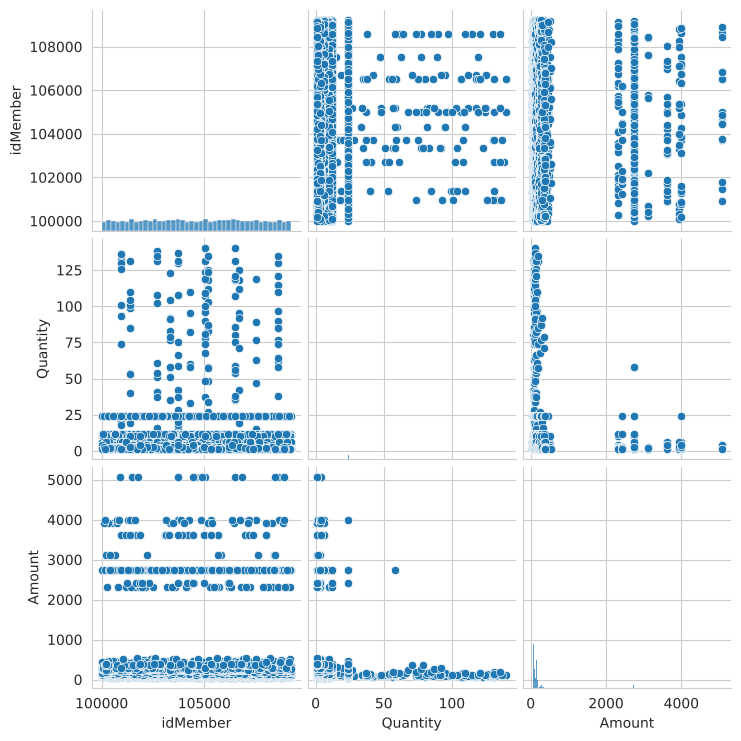

In [9]:
sns.pairplot(TxnRaw)     # Figure 4.2: pairwise plots of the numeric variables (idMember, Quantity, Amount)
plt.show()

In [10]:
TxnRaw.describe()        # Figure 4.3

,idMember,JoinedDate,DOB,InvoiceDate,Quantity,Amount
count,62766.000000,62766,62766,62766,62766.000000,62766.000000
mean,104593.109805,2013-01-09 09:38:00.919606,1967-07-28 22:58:51.517064,2019-10-11 15:20:46.084504,2.745005,148.760864
min,100001.000000,2002-12-02 00:18:00,1940-01-01 00:00:00,2017-07-14 02:38:00,1.000000,40.650000
25%,102320.000000,2009-08-24 16:32:00,1950-01-01 00:00:00,2018-05-13 05:20:00,1.000000,83.740000
50%,104597.500000,2013-03-17 22:58:00,1965-01-01 00:00:00,2019-07-23 03:32:00,1.000000,112.760000
75%,106804.000000,2017-08-03 01:29:00,1985-01-01 00:00:00,2021-02-02 03:50:30,3.000000,144.820000
max,109227.000000,2022-09-30 00:00:00,2000-01-01 00:00:00,2022-11-02 06:48:00,140.000000,5070.020000
std,2635.264420,NaN,NaN,NaN,5.234231,275.177381


For comparison, my dissertation data had a mean Quantity of 2.60 (std 4.10, max 140). The idMember statistics mean nothing now that the IDs are pseudonyms, and I've left the Amount figures out of the public version.

## 4.3 Data Cleaning and Data Handling
### 4.3.1 Data with Null/Missing Values

In [11]:
TxnRaw.isnull().sum()    # Figure 4.4

idMember            0
Name                0
JoinedDate          0
Gender              0
Language            0
DOB                 0
Contact           283
Email           18372
State              53
City             2879
Invoice             0
InvoiceDate         0
Item_Name           0
Profile_Type        0
Quantity            0
Amount              0
Order_Type          0
dtype: int64

In my run, Contact had 283 missing values, Email 18,464 (about 29%), State 53 and City 2,886. I left the missing e-mails alone, because the marketing team reaches customers by phone anyway. State mattered more, because the company wanted it for planning new branches.

In my original code, `TxnData`, `TxnRaw` and `RawDataALL` all pointed to the same DataFrame. I've kept that, so the later cells behave as they did. (Those variables originally carried the company's name, so I renamed them.)

In [12]:
TxnData = TxnRaw            # same object (see note above)

# Figure 4.5: before / after fillna on State
print('The number of null/missing value in State: {}'.format(TxnData['State'].isnull().sum()))  # Before

# Inferred ordering: transformCITYInfo (Fig 4.7a) looks for State == 'Unlabelled' and City == 'Unlabelled',
# so missing State/City are first tagged 'Unlabelled', resolved from City where possible,
# and anything still unresolved becomes 'Unknown' (as in Fig 4.5).
TxnData['State'] = TxnData['State'].fillna("Unlabelled")
TxnData['City'] = TxnData['City'].fillna("Unlabelled")

The number of null/missing value in State: 53


### 4.3.2 Data with Noise or Inaccurate Values
Customers could pick 'English', 'Chinese', 'Malay' or 'Bahasa'. 'Malay' and 'Bahasa' mean the same thing, so I merged them into 'BahasaMelayu', and relabelled 'Chinese' as 'Mandarin'.

In [13]:
TxnData.Language.unique()  # Before

<StringArray>
['English', 'Malay', 'Chinese', 'Bahasa']
Length: 4, dtype: str

In [14]:
# function to convert input under 'Language' variable  (Figure 4.6, verbatim)
def convertMajorLanguage(RawData6):
    for i in range(len(RawData6)):
        Lang = RawData6.iloc[i, 4]
        if Lang == 'Malay':
            RawData6.iloc[i, 4] = 'BahasaMelayu'
        if Lang == 'Bahasa':
            RawData6.iloc[i, 4] = 'BahasaMelayu'
        if Lang == 'Chinese':
            RawData6.iloc[i, 4] = 'Mandarin'
    return RawData6

TxnData = convertMajorLanguage(TxnData)  # Call function
TxnRaw.Language.unique()  # After

<StringArray>
['English', 'BahasaMelayu', 'Mandarin']
Length: 3, dtype: str

State was messier. There were trailing spaces ('Penang '), two names for the same place ('Pulau Pinang' and 'Penang', 'Wilayah Persekutuan' and 'Selangor & KL'), and odd values like 'Others', 'SG & Others' or just a blank. I wrote two functions that check each State against its City and merge everything into one clean label.

Two changes from my original code: `DataStateInfo.State[i] = x` is now written as `DataStateInfo.loc[i, 'State'] = x`, because newer pandas versions no longer save the first form, and the place names in `transformCITYInfo` are representative examples. The originals were raw values typed by individual customers, so I don't publish them.

In [15]:
if CAMOUFLAGE:      # public edition: raw labels are not displayed
    print(f"{TxnData['State'].nunique()} distinct raw State labels before cleaning (names hidden in the public edition)")
else:
    display(TxnData['State'].unique())  # Before (Figure 4.8)

28 distinct raw State labels before cleaning (names hidden in the public edition)


In [16]:
def transformCITYInfo(DataStateInfo):                       # Figure 4.7(a) (place names are examples)
    for sn1 in DataStateInfo.index:
        if DataStateInfo.State[sn1] == 'Unlabelled':
            if DataStateInfo.City[sn1] == 'Singapore':
                newSN1 = 'Singapore'
                DataStateInfo.loc[sn1, 'State'] = newSN1
            if DataStateInfo.City[sn1] == 'Singapura':
                newSN2 = 'Singapore'
                DataStateInfo.loc[sn1, 'State'] = newSN2
            if DataStateInfo.City[sn1] == 'Melaka':
                newSN3 = 'Melaka'
                DataStateInfo.loc[sn1, 'State'] = newSN3
            if DataStateInfo.City[sn1] == 'Woodlands':
                newSN4 = 'Singapore'
                DataStateInfo.loc[sn1, 'State'] = newSN4
            if DataStateInfo.City[sn1] == 'Jakarta':
                newSN5 = 'Indonesia'
                DataStateInfo.loc[sn1, 'State'] = newSN5
            if DataStateInfo.City[sn1] == 'Medan':
                newSN6 = 'Indonesia'
                DataStateInfo.loc[sn1, 'State'] = newSN6
            if DataStateInfo.City[sn1] == 'Surabaya':
                newSN7 = 'Indonesia'
                DataStateInfo.loc[sn1, 'State'] = newSN7
            if DataStateInfo.City[sn1] == 'Brunei':
                newSN8 = 'Brunei'
                DataStateInfo.loc[sn1, 'State'] = newSN8
            if DataStateInfo.City[sn1] == 'Bandar Seri Begawan':
                newSN9 = 'Brunei'
                DataStateInfo.loc[sn1, 'State'] = newSN9
            if DataStateInfo.City[sn1] == 'Unlabelled':
                newSN10 = 'Unknown'
                DataStateInfo.loc[sn1, 'State'] = newSN10
    return DataStateInfo


def transformSTATEInfo(DataStateInfo):                      # Figure 4.7(b)
    for s2 in DataStateInfo.index:
        if DataStateInfo.State[s2] == 'Others':
            newS1 = 'Singapore'
            DataStateInfo.loc[s2, 'State'] = newS1
        if DataStateInfo.State[s2] == ' ':
            newS2 = 'Unknown'
            DataStateInfo.loc[s2, 'State'] = newS2
        if DataStateInfo.State[s2] == 'Brunei ':
            newS3 = 'Brunei'
            DataStateInfo.loc[s2, 'State'] = newS3
        if DataStateInfo.State[s2] == 'MELAKA':
            newS4 = 'Melaka'
            DataStateInfo.loc[s2, 'State'] = newS4
        if DataStateInfo.State[s2] == 'Pahang ':
            newS5 = 'Pahang'
            DataStateInfo.loc[s2, 'State'] = newS5
        if DataStateInfo.State[s2] == 'Penang ':
            newS6 = 'Penang'
            DataStateInfo.loc[s2, 'State'] = newS6
        if DataStateInfo.State[s2] == 'Pulau Pinang':
            newS7 = 'Penang'
            DataStateInfo.loc[s2, 'State'] = newS7
        if DataStateInfo.State[s2] == 'SG & Others':
            newS8 = 'Singapore'
            DataStateInfo.loc[s2, 'State'] = newS8
        if DataStateInfo.State[s2] == 'Wilayah Persekutuan':
            newS9 = 'Selangor & KL'
            DataStateInfo.loc[s2, 'State'] = newS9
    return DataStateInfo

In [17]:
TxnData = transformCITYInfo(TxnData)   # Data handling function
TxnData = transformSTATEInfo(TxnData)  # Data handling function

# anything still unresolved -> 'Unknown' (Figure 4.5 'after'); City placeholder restored to NaN
TxnData['State'] = TxnData['State'].replace("Unlabelled", "Unknown")
TxnData['City'] = TxnData['City'].replace("Unlabelled", np.nan)
print('The number of null/missing value in State: {}'.format(TxnData['State'].isnull().sum()))  # After

if CAMOUFLAGE:
    # States are masked only now: the cleaning rules above needed the real labels.
    # Region letters follow a secret, key-determined order (not size or alphabet). The mapping is not kept.
    _labels = sorted(set(TxnData['State'].dropna()) - {'Unknown'}, key=lambda v: _h(SECRET_KEY, "region", v))
    _rmap = {lab: f"Region {chr(65 + i)}" for i, lab in enumerate(_labels)}
    TxnData['State'] = TxnData['State'].map(lambda v: _rmap.get(v, v))
    TxnData['City'] = TxnData['City'].map(lambda c: c if pd.isna(c) or str(c).startswith("CITY_")
                                          else keyed_token(c, SECRET_KEY, "CITY"))
    del _labels, _rmap
    if not PERSIST_KEY:
        del SECRET_KEY           # last use of the key: from here the pseudonyms are one-way
TxnData['State'].unique()  # After (Figure 4.8)

The number of null/missing value in State: 0


<StringArray>
['Region G', 'Region Q', 'Region D', 'Region A', 'Region R', 'Region M',
 'Region H', 'Region P', 'Region B', 'Region L', 'Region K', 'Region I',
 'Region J', 'Region E', 'Region F', 'Region O',  'Unknown', 'Region N',
 'Region C']
Length: 19, dtype: str

After cleaning, my dissertation data had 19 State labels: the Malaysian states, a few foreign countries and 'Unknown'. Here they appear as Region A, Region B and so on.

### 4.3.3 Duplicate Data Handling
A plain `duplicated()` check found no duplicates at all. The company told me there were some, though. The same item inside one invoice was sometimes tagged under more than one `Profile_Type`, which created extra rows that didn't look identical.

In [18]:
print('Duplicate entries: {}'.format(TxnRaw.duplicated().sum()))   # Figure 4.9

Duplicate entries: 0


In [19]:
def getDuplicatesWithInfo(listOfElems):                     # Figure 4.11 (verbatim)
#build a dictionary of indexes under a unique InvoiceNo
    dictOfElems = dict()
    LE = listOfElems.iloc[:, 10]          # column 10 = Invoice
    rIdx = LE.reset_index()
    ixx = 0

    for elem in LE:
        if elem in dictOfElems:
            coor = rIdx.iloc[ixx, 0]
            dictOfElems[elem][0] += 1
            dictOfElems[elem][1].append(coor)
        else:
            coor1 = rIdx.iloc[ixx, 0]
            dictOfElems[elem] = [1, [coor1]]
        ixx += 1

    dictOfElems = {key: value for key, value in dictOfElems.items() if value[0] > 1}
    return dictOfElems

listOfElems = TxnData
dictOfElems = getDuplicatesWithInfo(listOfElems)  # Find all indexes that linked to a unique InvoiceNo
for n, (key, value) in enumerate(dictOfElems.items()):
    print('Element = ', key, ' :: Repeated Count = ', value[0], ' :: Index Positions =  ', [int(x) for x in value[1]])
    if n == 7: break
print('...\nInvoices with >1 line:', len(dictOfElems), '| highest repeated count:', max(v[0] for v in dictOfElems.values()))

Element =  INV-P010846  :: Repeated Count =  2  :: Index Positions =   [0, 1047]
Element =  INV-P035458  :: Repeated Count =  7  :: Index Positions =   [1, 49, 2204, 14344, 16032, 50071, 56968]
Element =  INV-P001853  :: Repeated Count =  2  :: Index Positions =   [2, 94]
Element =  INV-P012198  :: Repeated Count =  2  :: Index Positions =   [3, 150]
Element =  INV-P034637  :: Repeated Count =  3  :: Index Positions =   [4, 300, 20925]
Element =  INV-P037777  :: Repeated Count =  4  :: Index Positions =   [5, 330, 23589, 29653]
Element =  INV-P035101  :: Repeated Count =  2  :: Index Positions =   [6, 485]
Element =  INV-P007601  :: Repeated Count =  4  :: Index Positions =   [7, 1208, 3287, 36401]
...
Invoices with >1 line: 12611 | highest repeated count: 8


The highest number of lines on a single invoice was 7.

To find the hidden duplicates, `detectPartialDuplicate` builds a `duplicated()` mask within each invoice for Item_Name, Order_Type, Amount and Quantity, and combines them. A row that repeats on all four gets flagged and is removed later. If I wrote this today I would use one combined key instead of four separate masks, but I've kept my original logic. The only changes are for newer pandas: the rows are now collected in a list and joined once at the end, and `.where()` replaces the old string-times-boolean trick.

In [20]:
InvoiceNoDict = dictOfElems
RawDataALL = TxnData

def detectPartialDuplicate(DupItemList):                    # Figure 4.12
    NONdup = []                                    # was: pd.Series() + NONdup.append(...)
    for e in DupItemList:
        dupI = RawDataALL.Item_Name[DupItemList[e][1]]
        MaskI = dupI.duplicated()
        dupT = RawDataALL.Order_Type[DupItemList[e][1]]
        MaskT = dupT.duplicated()
        dupA = RawDataALL.Amount[DupItemList[e][1]]
        MaskA = dupA.duplicated()
        dupQ = RawDataALL.Quantity[DupItemList[e][1]]
        MaskQ = dupQ.duplicated()

        MaskALL = MaskI & MaskT & MaskA & MaskQ
        #Multiple duplicated() masks added together to improve detection

        for m in MaskALL:
            if m == True:
                newL = dupI.where(~MaskALL, '')    # was: dupI*~MaskALL  -> Invert it to get unique ItemName
                NONdup.append(newL)
            else:
                pass                               # was: NONdup.append(None)  (concat ignores None)

    UniqueItemName = pd.DataFrame(pd.concat(NONdup) if NONdup else pd.Series(dtype=object))  # turn it into a Dataframe
    UniqueItemName.columns = ["Info"]
    UniqueItemName = UniqueItemName.reset_index()
    return UniqueItemName

UniqueItemList = detectPartialDuplicate(InvoiceNoDict)

In [21]:
def extractDuplicateIndex(UniqueItemdataframe):             # Figure 4.13
    DuplicateEntry = []
    for i in range(len(UniqueItemdataframe)):
        if UniqueItemdataframe.Info[i] == '':
            DIndex = (UniqueItemdataframe['index'][i])
            DuplicateEntry.append(DIndex)
    return DuplicateEntry

DupIndex = extractDuplicateIndex(UniqueItemList)

def getCleanData(RawData, DuplicateIndex):
    CleaningData = pd.DataFrame(RawData)
    CleaningData = CleaningData.drop(index=DuplicateIndex)     # was: .drop(..., inplace=True)
    return CleaningData

CleanedData = getCleanData(TxnRaw, DupIndex)

DuplicateEntry = len(TxnRaw) - len(CleanedData)
print('The duplicate data entries found after performing data cleaning is:', DuplicateEntry)

The duplicate data entries found after performing data cleaning is: 435


This step removed 435 hidden duplicate rows from my dissertation data, which left 62,331 clean rows.

## 4.4 Feature Selections of RFM
### 4.4.1 Creation of RFM features model
For segmentation I used the classic RFM view of each customer: how recently they bought (Recency), how often (Frequency) and how much they spent (Monetary).

In [22]:
DATASelection = CleanedData[['idMember', 'JoinedDate', 'Invoice', 'InvoiceDate', 'Quantity', 'Amount']]
DATASelection = pd.DataFrame(DATASelection).copy()
DATASelection          # Figure 4.14

,idMember,JoinedDate,Invoice,InvoiceDate,Quantity,Amount
0,102122,2002-12-19 04:20:00,INV-P010846,2020-11-27 08:01:00,1,67.93
1,105459,2003-01-27 15:25:00,INV-P035458,2019-11-17 19:20:00,3,69.55
2,101034,2003-07-20 22:05:00,INV-P001853,2018-12-05 06:44:00,1,69.55
3,106476,2004-08-01 12:07:00,INV-P012198,2017-10-06 22:44:00,1,69.55
4,103555,2009-10-12 13:03:00,INV-P034637,2020-10-07 05:58:00,1,69.55
...,...,...,...,...,...,...
62761,101374,2020-08-02 03:54:00,INV-P015020,2020-12-02 13:19:00,3,3607.35
62762,103896,2021-10-01 00:14:00,INV-P021080,2021-10-26 14:00:00,3,3607.35
62763,103737,2021-12-17 22:15:00,INV-P007733,2021-12-17 23:14:00,4,3607.35
62764,103274,2021-12-11 12:41:00,INV-P038495,2022-07-15 05:24:00,1,3607.35


In [23]:
DATASelection['LastPurchased'] = pd.DatetimeIndex(DATASelection['InvoiceDate']).date
DATASelection          # Figure 4.15

,idMember,JoinedDate,Invoice,InvoiceDate,Quantity,Amount,LastPurchased
0,102122,2002-12-19 04:20:00,INV-P010846,2020-11-27 08:01:00,1,67.93,2020-11-27
1,105459,2003-01-27 15:25:00,INV-P035458,2019-11-17 19:20:00,3,69.55,2019-11-17
2,101034,2003-07-20 22:05:00,INV-P001853,2018-12-05 06:44:00,1,69.55,2018-12-05
3,106476,2004-08-01 12:07:00,INV-P012198,2017-10-06 22:44:00,1,69.55,2017-10-06
4,103555,2009-10-12 13:03:00,INV-P034637,2020-10-07 05:58:00,1,69.55,2020-10-07
...,...,...,...,...,...,...,...
62761,101374,2020-08-02 03:54:00,INV-P015020,2020-12-02 13:19:00,3,3607.35,2020-12-02
62762,103896,2021-10-01 00:14:00,INV-P021080,2021-10-26 14:00:00,3,3607.35,2021-10-26
62763,103737,2021-12-17 22:15:00,INV-P007733,2021-12-17 23:14:00,4,3607.35,2021-12-17
62764,103274,2021-12-11 12:41:00,INV-P038495,2022-07-15 05:24:00,1,3607.35,2022-07-15


In [24]:
now = DATASelection['LastPurchased'].max()
print('The date of reference chosen is:', now)     # Figure 4.16 (thesis: early October 2022)

The date of reference chosen is: 2022-11-02


In [25]:
DATASelection['Recency'] = DATASelection['LastPurchased'].apply(lambda x: (now - x).days)
DATASelection          # Figure 4.17

,idMember,JoinedDate,Invoice,InvoiceDate,Quantity,Amount,LastPurchased,Recency
0,102122,2002-12-19 04:20:00,INV-P010846,2020-11-27 08:01:00,1,67.93,2020-11-27,705
1,105459,2003-01-27 15:25:00,INV-P035458,2019-11-17 19:20:00,3,69.55,2019-11-17,1081
2,101034,2003-07-20 22:05:00,INV-P001853,2018-12-05 06:44:00,1,69.55,2018-12-05,1428
3,106476,2004-08-01 12:07:00,INV-P012198,2017-10-06 22:44:00,1,69.55,2017-10-06,1853
4,103555,2009-10-12 13:03:00,INV-P034637,2020-10-07 05:58:00,1,69.55,2020-10-07,756
...,...,...,...,...,...,...,...,...
62761,101374,2020-08-02 03:54:00,INV-P015020,2020-12-02 13:19:00,3,3607.35,2020-12-02,700
62762,103896,2021-10-01 00:14:00,INV-P021080,2021-10-26 14:00:00,3,3607.35,2021-10-26,372
62763,103737,2021-12-17 22:15:00,INV-P007733,2021-12-17 23:14:00,4,3607.35,2021-12-17,320
62764,103274,2021-12-11 12:41:00,INV-P038495,2022-07-15 05:24:00,1,3607.35,2022-07-15,110


In [26]:
CustomerR = DATASelection.groupby('idMember', as_index=False)['Recency'].min()
CustomerR              # Figure 4.18

,idMember,Recency
0,100001,558
1,100002,936
2,100003,136
3,100004,118
4,100005,1643
...,...,...
9222,109223,717
9223,109224,225
9224,109225,697
9225,109226,189


One thing I'd do differently now: my original Frequency loop counts how many invoice *lines* each customer has, not how many separate invoices. An order with three different products counts as three. I've kept it this way so the results match my dissertation. To count distinct invoices instead, use `DATASelection.groupby('idMember')['Invoice'].nunique()`.

In [27]:
if RUN_ORIGINAL_SLOW_LOOPS:
    # Figure 4.19, verbatim (about 9k groupbys over 62k rows; slow)
    DATASelection['Frequency'] = 0
    customerID = list(DATASelection['idMember'].unique())
    for id in customerID:
        DATASelection.loc[DATASelection['idMember'] == id, 'Frequency'] += DATASelection.groupby(by='idMember').Invoice.size()[id]
else:
    # identical result, vectorised
    DATASelection['Frequency'] = DATASelection.groupby('idMember')['Invoice'].transform('size')
DATASelection          # Figure 4.19

,idMember,JoinedDate,Invoice,InvoiceDate,Quantity,Amount,LastPurchased,Recency,Frequency
0,102122,2002-12-19 04:20:00,INV-P010846,2020-11-27 08:01:00,1,67.93,2020-11-27,705,14
1,105459,2003-01-27 15:25:00,INV-P035458,2019-11-17 19:20:00,3,69.55,2019-11-17,1081,35
2,101034,2003-07-20 22:05:00,INV-P001853,2018-12-05 06:44:00,1,69.55,2018-12-05,1428,7
3,106476,2004-08-01 12:07:00,INV-P012198,2017-10-06 22:44:00,1,69.55,2017-10-06,1853,3
4,103555,2009-10-12 13:03:00,INV-P034637,2020-10-07 05:58:00,1,69.55,2020-10-07,756,22
...,...,...,...,...,...,...,...,...,...
62761,101374,2020-08-02 03:54:00,INV-P015020,2020-12-02 13:19:00,3,3607.35,2020-12-02,700,7
62762,103896,2021-10-01 00:14:00,INV-P021080,2021-10-26 14:00:00,3,3607.35,2021-10-26,372,18
62763,103737,2021-12-17 22:15:00,INV-P007733,2021-12-17 23:14:00,4,3607.35,2021-12-17,320,6
62764,103274,2021-12-11 12:41:00,INV-P038495,2022-07-15 05:24:00,1,3607.35,2022-07-15,110,13


In [28]:
CustomerF = DATASelection.groupby('idMember', as_index=False)['Frequency'].count()
CustomerF              # Figure 4.20

,idMember,Frequency
0,100001,6
1,100002,7
2,100003,10
3,100004,7
4,100005,3
...,...,...
9222,109223,13
9223,109224,1
9224,109225,13
9225,109226,2


In [29]:
DATASelection['Monetary'] = DATASelection['Amount'] * DATASelection['Quantity']
DATASelection          # Figure 4.21

,idMember,JoinedDate,Invoice,InvoiceDate,Quantity,Amount,LastPurchased,Recency,Frequency,Monetary
0,102122,2002-12-19 04:20:00,INV-P010846,2020-11-27 08:01:00,1,67.93,2020-11-27,705,14,67.93
1,105459,2003-01-27 15:25:00,INV-P035458,2019-11-17 19:20:00,3,69.55,2019-11-17,1081,35,208.65
2,101034,2003-07-20 22:05:00,INV-P001853,2018-12-05 06:44:00,1,69.55,2018-12-05,1428,7,69.55
3,106476,2004-08-01 12:07:00,INV-P012198,2017-10-06 22:44:00,1,69.55,2017-10-06,1853,3,69.55
4,103555,2009-10-12 13:03:00,INV-P034637,2020-10-07 05:58:00,1,69.55,2020-10-07,756,22,69.55
...,...,...,...,...,...,...,...,...,...,...
62761,101374,2020-08-02 03:54:00,INV-P015020,2020-12-02 13:19:00,3,3607.35,2020-12-02,700,7,10822.05
62762,103896,2021-10-01 00:14:00,INV-P021080,2021-10-26 14:00:00,3,3607.35,2021-10-26,372,18,10822.05
62763,103737,2021-12-17 22:15:00,INV-P007733,2021-12-17 23:14:00,4,3607.35,2021-12-17,320,6,14429.40
62764,103274,2021-12-11 12:41:00,INV-P038495,2022-07-15 05:24:00,1,3607.35,2022-07-15,110,13,3607.35


In [30]:
CustomerM = DATASelection.groupby('idMember', as_index=False)['Monetary'].sum()
CustomerM              # Figure 4.22

,idMember,Monetary
0,100001,2024.88
1,100002,1306.48
2,100003,5311.35
3,100004,2852.42
4,100005,862.84
...,...,...
9222,109223,4424.78
9223,109224,334.96
9224,109225,2690.57
9225,109226,209.70


In [31]:
tempRFdf = CustomerR.merge(CustomerF, on='idMember')
RFMdata = tempRFdf.merge(CustomerM, on='idMember')
RFMdata                # Figure 4.23

,idMember,Recency,Frequency,Monetary
0,100001,558,6,2024.88
1,100002,936,7,1306.48
2,100003,136,10,5311.35
3,100004,118,7,2852.42
4,100005,1643,3,862.84
...,...,...,...,...
9222,109223,717,13,4424.78
9223,109224,225,1,334.96
9224,109225,697,13,2690.57
9225,109226,189,2,209.70


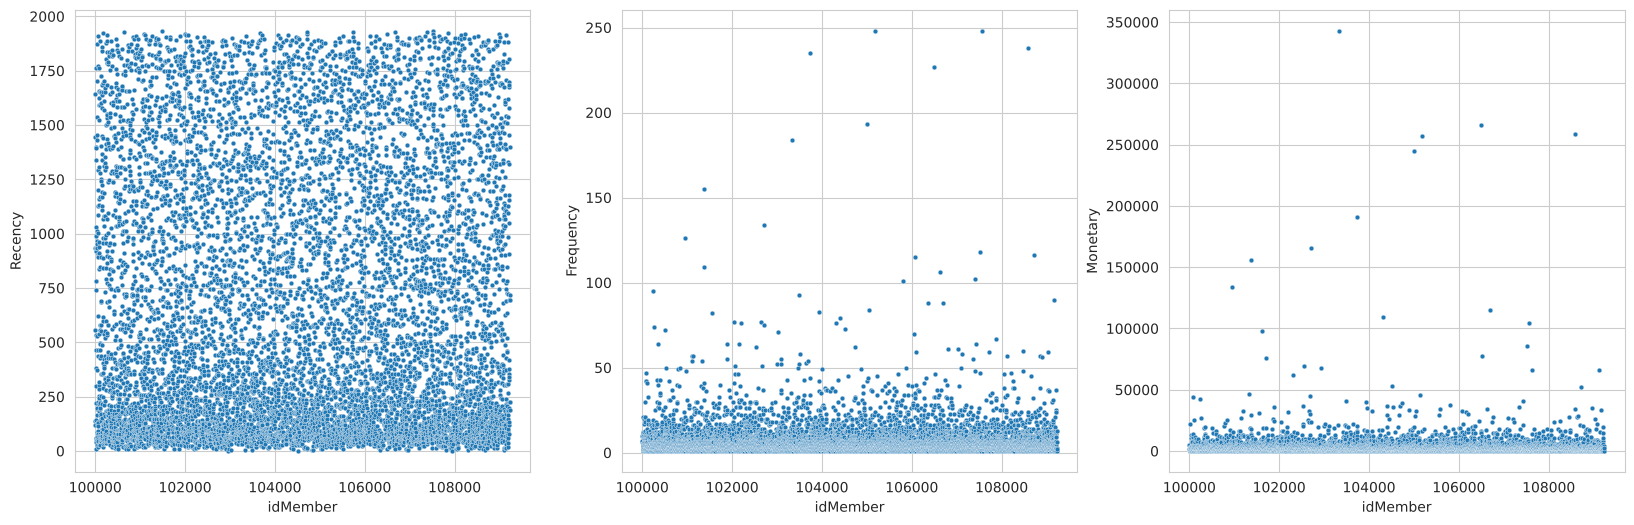

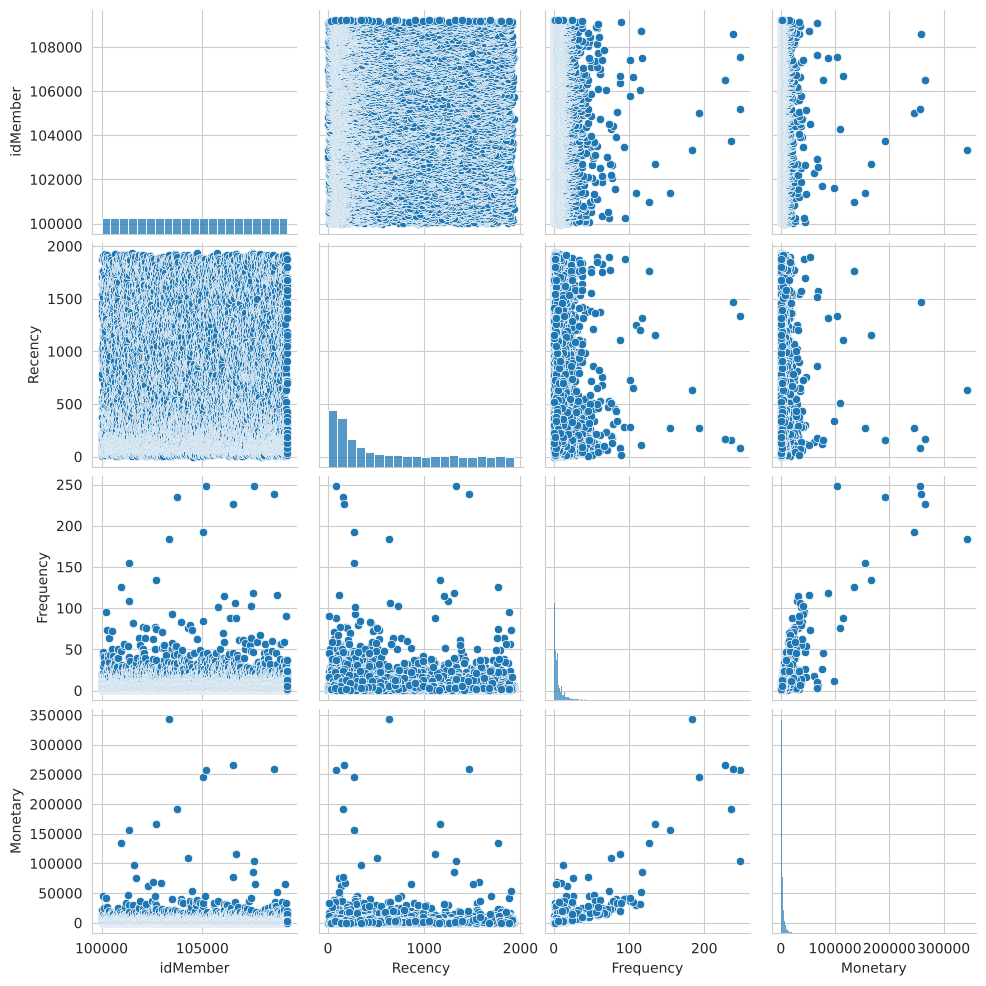

In [32]:
# Figure 4.24: R, F, M plotted against idMember
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, f in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    sns.scatterplot(data=RFMdata, x='idMember', y=f, ax=ax, s=12)
plt.show()

sns.pairplot(RFMdata)  # Figure 4.25
plt.show()

In [33]:
RFMdata.describe()     # Figure 4.26

,idMember,Recency,Frequency,Monetary
count,9227.000000,9227.000000,9227.000000,9227.000000
mean,104614.000000,670.512518,6.755283,2741.179601
std,2663.749801,590.554465,10.703923,8718.788498
min,100001.000000,0.000000,1.000000,57.580000
25%,102307.500000,141.000000,2.000000,498.350000
50%,104614.000000,457.000000,4.000000,1122.150000
75%,106920.500000,1164.000000,7.000000,2695.345000
max,109227.000000,1933.000000,248.000000,342793.270000


My dissertation data had 9,227 customers. Recency ranged from 0 to 1,858 days (median 492), and Frequency from 1 to 248 (median 3). I've left the Monetary figures out of the public version.

## 4.5 Model Development (K-Means Clustering)
I trained K-Means on the three RFM features only, leaving out the member ID.

In [34]:
TrainRFMdata = pd.DataFrame(RFMdata[['Recency', 'Frequency', 'Monetary']])
TrainRFMdata           # Figure 4.27

,Recency,Frequency,Monetary
0,558,6,2024.88
1,936,7,1306.48
2,136,10,5311.35
3,118,7,2852.42
4,1643,3,862.84
...,...,...,...
9222,717,13,4424.78
9223,225,1,334.96
9224,697,13,2690.57
9225,189,2,209.70


### 4.5.1 Feature Scaling
The three features are on very different scales (days, counts and money), so I standardised them first: *y = (x − mean) / standard deviation*.

In [35]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
nfeatures = ['Recency', 'Frequency', 'Monetary']
TransformedRFMdata = ss.fit_transform(TrainRFMdata[nfeatures])
TransformedRFMdata = pd.DataFrame(TransformedRFMdata, columns=nfeatures)
TransformedRFMdata     # Figure 4.28

,Recency,Frequency,Monetary
0,-0.190530,-0.070565,-0.082160
1,0.449581,0.022864,-0.164562
2,-0.905152,0.303150,0.294801
3,-0.935633,0.022864,0.012759
4,1.646826,-0.350851,-0.215448
...,...,...,...
9222,0.078723,0.583436,0.193111
9223,-0.754438,-0.537709,-0.275996
9224,0.044854,0.583436,-0.005805
9225,-0.815401,-0.444280,-0.290363


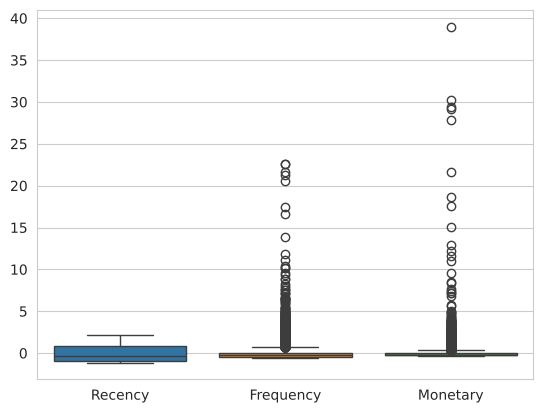

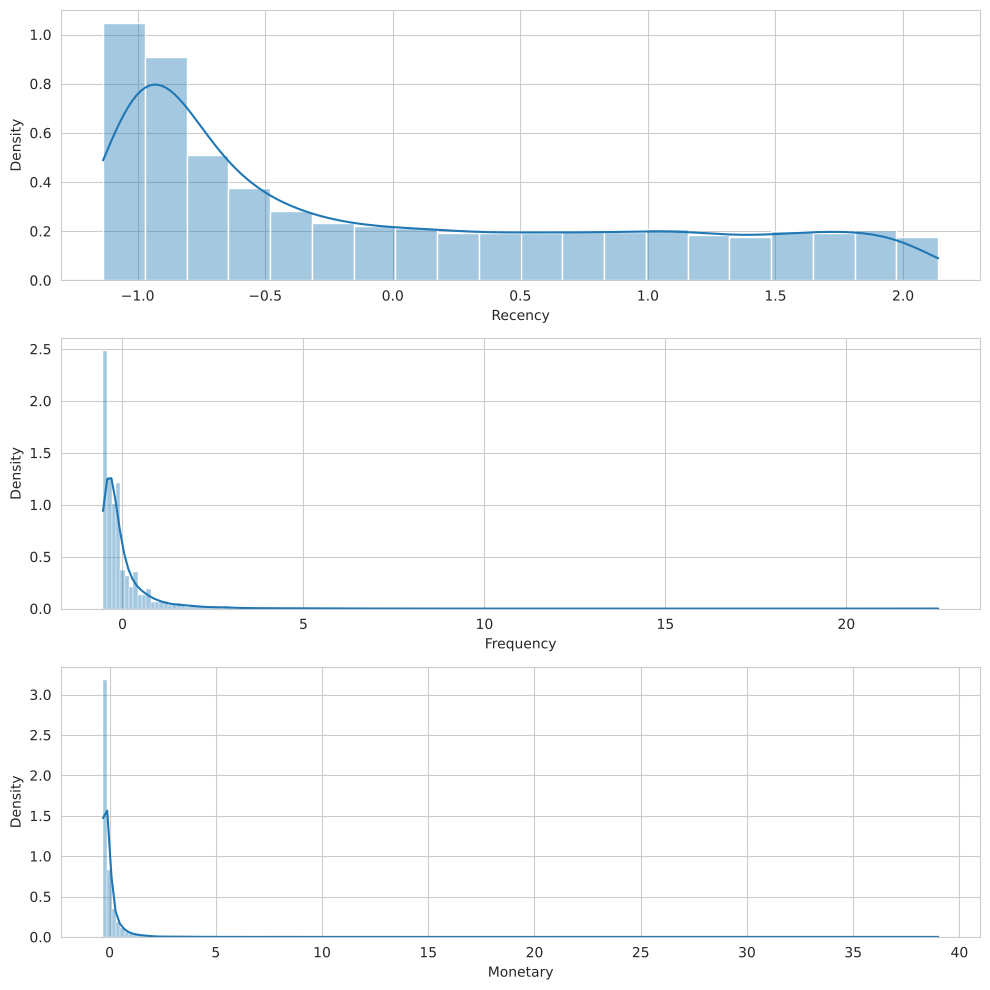

In [36]:
sns.boxplot(data=TransformedRFMdata)     # Figure 4.29
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(10, 10))     # Figure 4.30 (was sns.distplot)
for ax, f in zip(axes, nfeatures):
    sns.histplot(TransformedRFMdata[f], kde=True, stat='density', ax=ax, alpha=0.4)
plt.tight_layout(); plt.show()

### 4.5.3 Finding Optimum Value for Clusters, k
I ran K-Means for k = 2 to 14 and scored each result two ways: the Calinski-Harabasz Index (higher is better) and the Davies-Bouldin Index (lower is better). I also timed each loop.

In [37]:
start_time = time.time()
calinski_avgs = []
min_k = 2
Xdata1 = TransformedRFMdata

for k in range(min_k, 15):
    kmeanCHI = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(Xdata1)
    score = metrics.calinski_harabasz_score(Xdata1, kmeanCHI.labels_)
    print("Calinski Harabasz Index for k =", k, "is", score)
    calinski_avgs.append(score)

Optimal_K1 = calinski_avgs.index(max(calinski_avgs)) + min_k
print("Optimal K is", Optimal_K1)

t1 = time.time() - start_time
print("--- %s seconds ---" % t1)       # Figure 4.31

Calinski Harabasz Index for k = 2 is 4441.649525054439
Calinski Harabasz Index for k = 3 is 6792.345073355008
Calinski Harabasz Index for k = 4 is 8868.174096786533
Calinski Harabasz Index for k = 5 is 8606.322314239038
Calinski Harabasz Index for k = 6 is 8587.630239849126
Calinski Harabasz Index for k = 7 is 8524.490169444267


Calinski Harabasz Index for k = 8 is 8537.664656822139
Calinski Harabasz Index for k = 9 is 8633.558997672524
Calinski Harabasz Index for k = 10 is 8621.000825752235
Calinski Harabasz Index for k = 11 is 8452.443018873722


Calinski Harabasz Index for k = 12 is 8614.431504305814
Calinski Harabasz Index for k = 13 is 8477.055117232609
Calinski Harabasz Index for k = 14 is 8330.604237821719
Optimal K is 4
--- 0.7269384860992432 seconds ---


In [38]:
start_time = time.time()
davies_avgs = []
min_k = 2
Xdata2 = TransformedRFMdata

for k in range(min_k, 15):
    kmeanDBI = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(Xdata2)
    score2 = metrics.davies_bouldin_score(Xdata2, kmeanDBI.labels_)
    print("Davies Bouldin Index for k =", k, "is", score2)
    davies_avgs.append(score2)

Optimal_K2 = davies_avgs.index(min(davies_avgs)) + min_k
print("Optimal K is", Optimal_K2)

t2 = time.time() - start_time
print("--- %s seconds ---" % t2)       # Figure 4.32

Davies Bouldin Index for k = 2 is 0.41388102517718817
Davies Bouldin Index for k = 3 is 0.6491287202996529
Davies Bouldin Index for k = 4 is 0.6477924110928109
Davies Bouldin Index for k = 5 is 0.7533940857212084
Davies Bouldin Index for k = 6 is 0.7619337154508633
Davies Bouldin Index for k = 7 is 0.7370209749519739


Davies Bouldin Index for k = 8 is 0.816821355813957
Davies Bouldin Index for k = 9 is 0.7712232153107544
Davies Bouldin Index for k = 10 is 0.746663526169095
Davies Bouldin Index for k = 11 is 0.7385887415875712


Davies Bouldin Index for k = 12 is 0.7743587456344154
Davies Bouldin Index for k = 13 is 0.7492605265092244


Davies Bouldin Index for k = 14 is 0.775237156773138
Optimal K is 2
--- 0.7349028587341309 seconds ---


In my dissertation run, CHI was highest at k = 13 (10,376.97) and DBI was lowest at k = 6 (0.5431). The next cell uses those two values unless `USE_THESIS_K` is switched off.

In [39]:
K_CHI, K_DBI = (13, 6) if USE_THESIS_K else (Optimal_K1, Optimal_K2)
COL_CHI, COL_DBI = f'ClusterK{K_CHI}', f'ClusterK{K_DBI}'
print(f"Using k={K_CHI} (CHI) and k={K_DBI} (DBI); this run's search found {Optimal_K1} and {Optimal_K2}")

XData13 = TransformedRFMdata[nfeatures]
XData6 = TransformedRFMdata[nfeatures]
kMeanXK13 = KMeans(n_clusters=K_CHI, n_init=N_INIT, random_state=RANDOM_STATE).fit(XData13)
kMeanXK6 = KMeans(n_clusters=K_DBI, n_init=N_INIT, random_state=RANDOM_STATE).fit(XData6)

KMeanLabelK13 = kMeanXK13.fit_predict(XData13)
KMeanLabelK6 = kMeanXK6.fit_predict(XData6)

ClusterIDK13 = KMeanLabelK13 + 1
ClusterIDK6 = KMeanLabelK6 + 1

TransformedRFMdata[COL_CHI] = ClusterIDK13
TransformedRFMdata[COL_DBI] = ClusterIDK6
TransformedRFMdata          # Figure 4.33

Using k=13 (CHI) and k=6 (DBI); this run's search found 4 and 2


,Recency,Frequency,Monetary,ClusterK13,ClusterK6
0,-0.190530,-0.070565,-0.082160,7,2
1,0.449581,0.022864,-0.164562,3,2
2,-0.905152,0.303150,0.294801,9,6
3,-0.935633,0.022864,0.012759,4,6
4,1.646826,-0.350851,-0.215448,6,1
...,...,...,...,...,...
9222,0.078723,0.583436,0.193111,1,2
9223,-0.754438,-0.537709,-0.275996,4,6
9224,0.044854,0.583436,-0.005805,1,2
9225,-0.815401,-0.444280,-0.290363,4,6


I attach both sets of cluster labels to the RFM table, which keeps the original units, so each customer's segment can be read alongside their real Recency, Frequency and Monetary values.

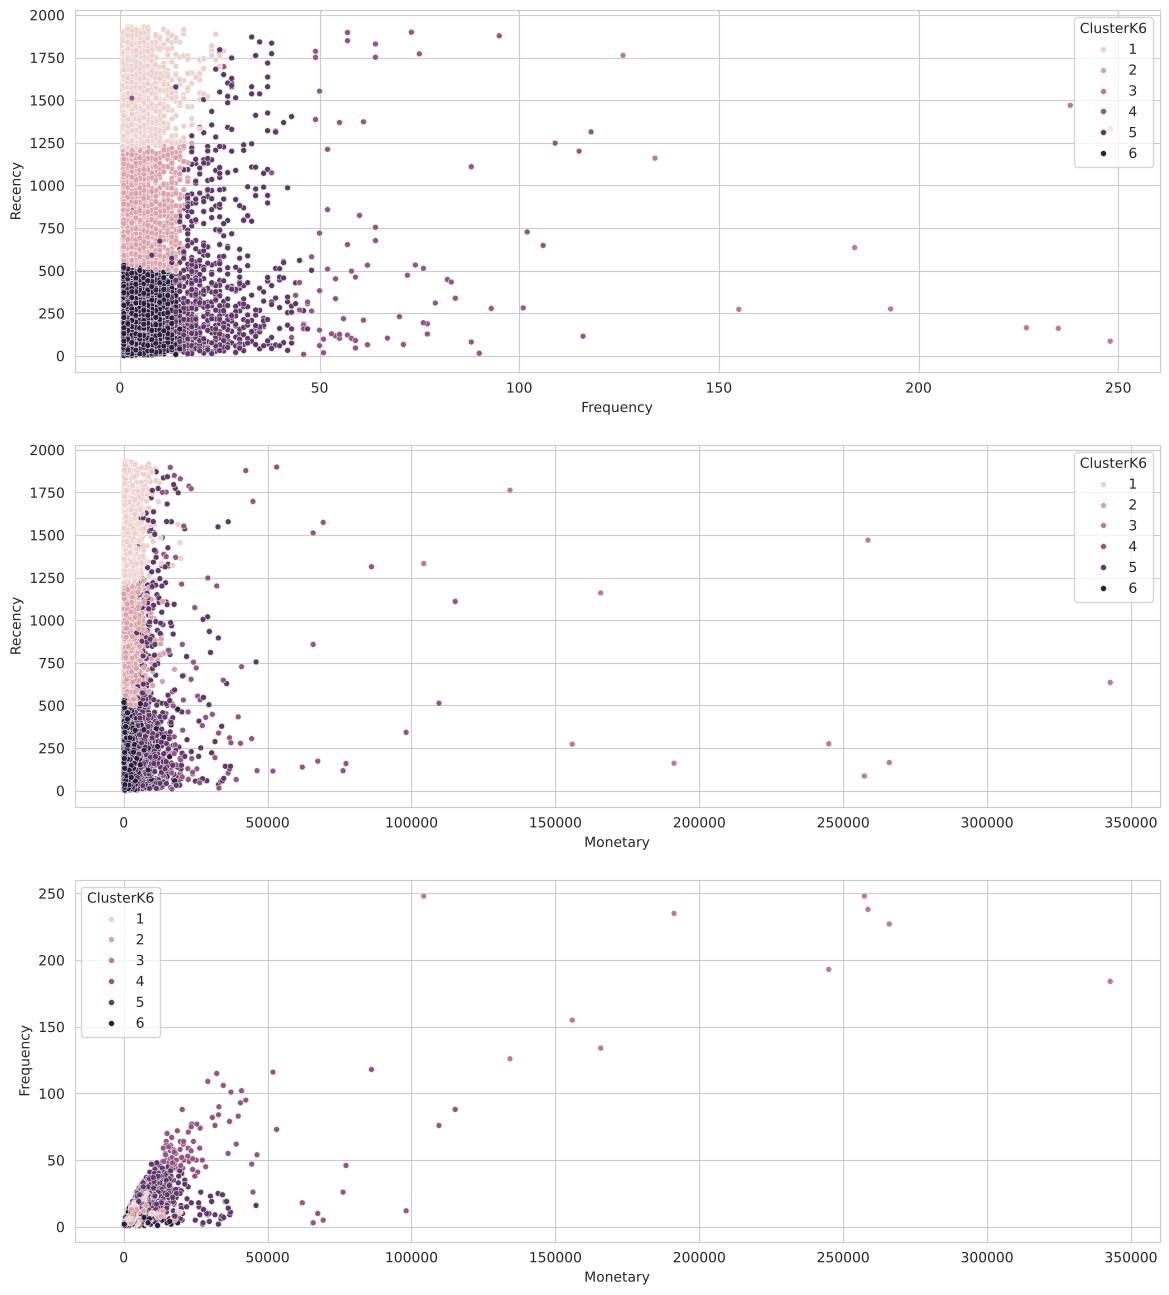

In [40]:
LabelledRFMdata = RFMdata
LabelledRFMdata[COL_CHI] = ClusterIDK13
LabelledRFMdata[COL_DBI] = ClusterIDK6

def plot_rfm_pairs(data, hue):            # Figures 4.34 / 4.36 / 5.42 / 5.43
    fig, axes = plt.subplots(3, 1, figsize=(14, 16))
    sns.scatterplot(data=data, x='Frequency', y='Recency', hue=hue, ax=axes[0], s=18)
    sns.scatterplot(data=data, x='Monetary', y='Recency', hue=hue, ax=axes[1], s=18)
    sns.scatterplot(data=data, x='Monetary', y='Frequency', hue=hue, ax=axes[2], s=18)
    plt.show()

plot_rfm_pairs(LabelledRFMdata, COL_DBI)     # Figure 4.34

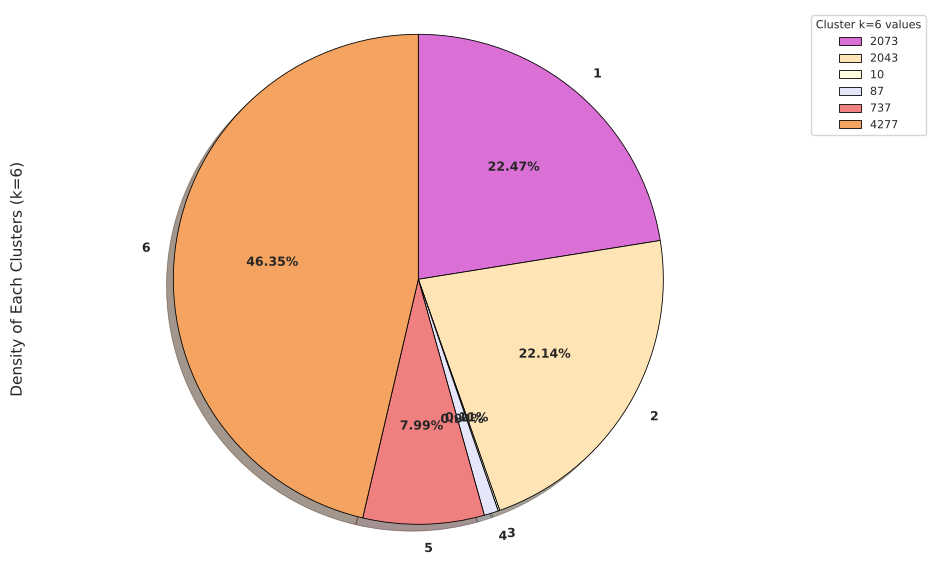

In [41]:
counts6 = LabelledRFMdata[COL_DBI].value_counts().sort_index()
plot_pie(counts6, f'Density of Each Clusters (k={K_DBI})', f'Cluster k={K_DBI} values')   # Figure 4.35
plt.show()

With k = 6, my dissertation clusters had 4,204 · 1,933 · 113 · 2,236 · 4 · 737 customers (45.56% · 20.95% · 1.22% · 24.23% · 0.04% · 7.99%).

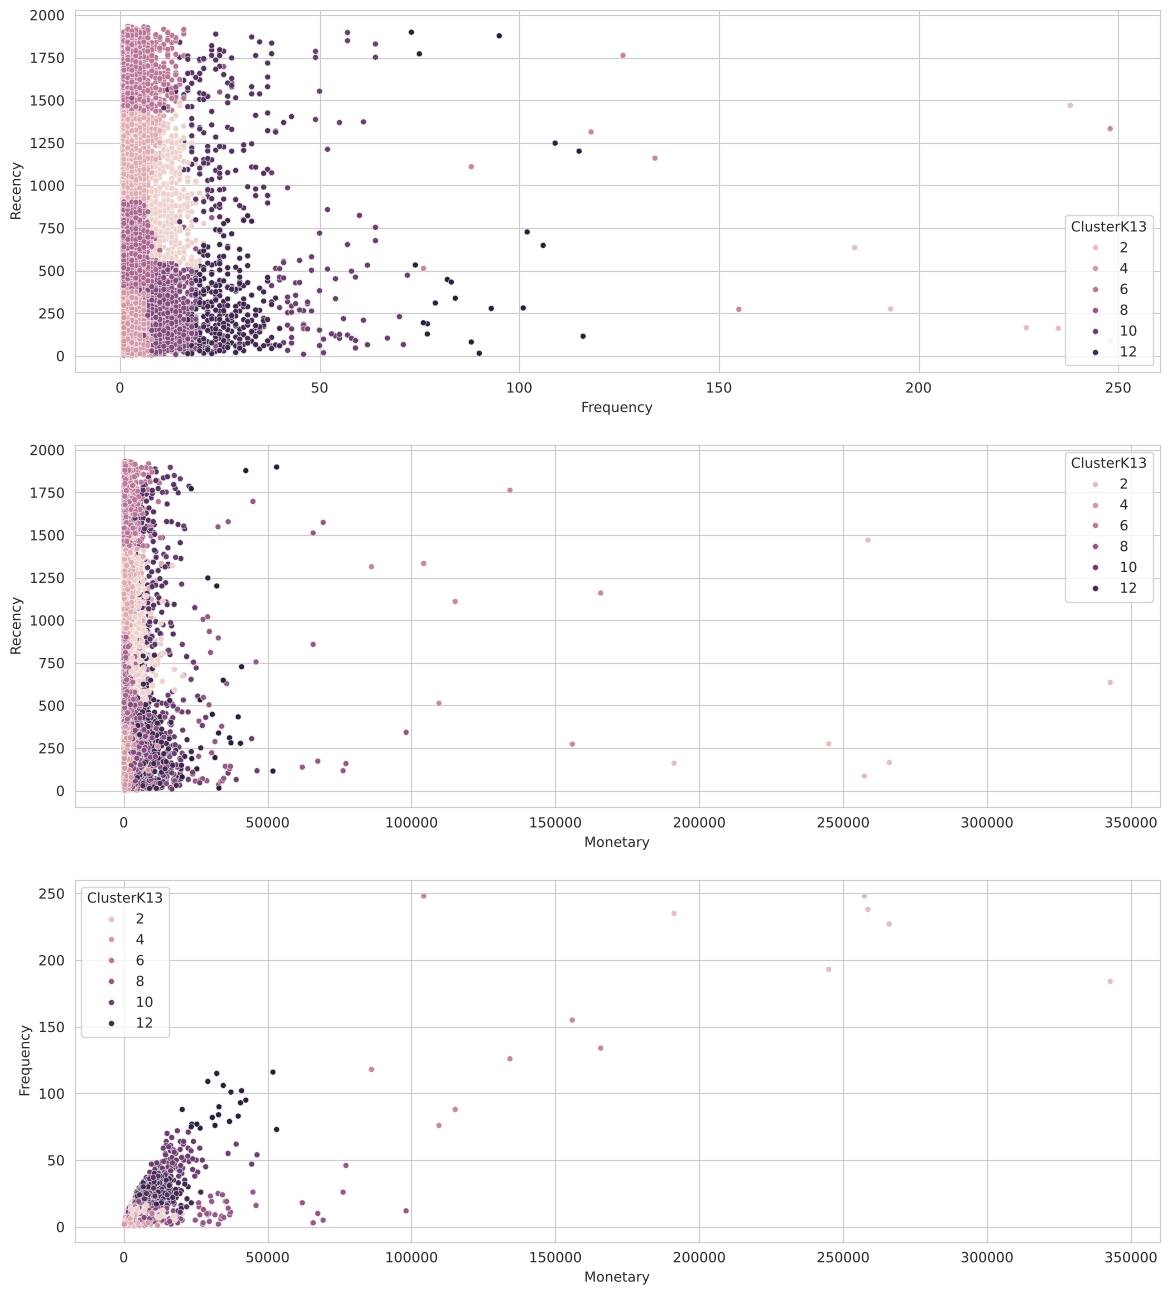

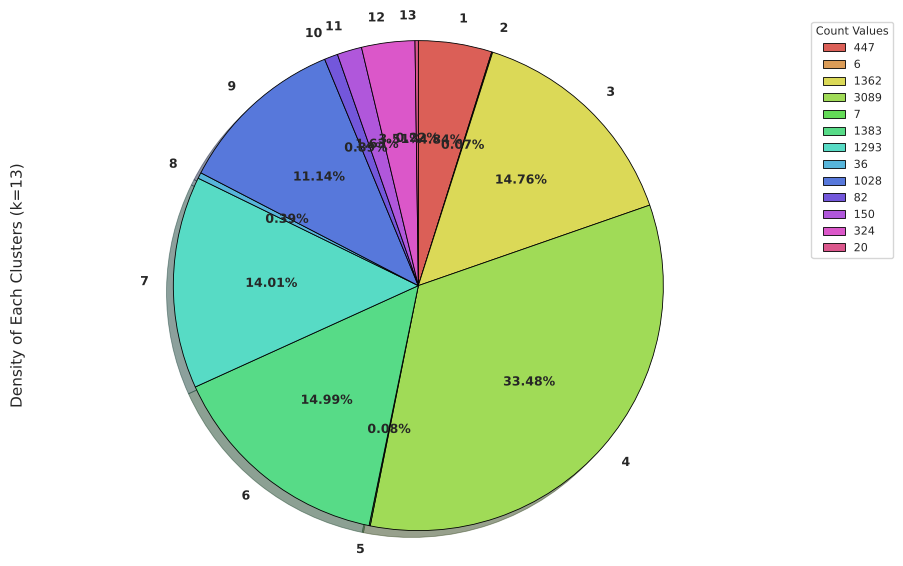

In [42]:
plot_rfm_pairs(LabelledRFMdata, COL_CHI)     # Figure 4.36
counts13 = LabelledRFMdata[COL_CHI].value_counts().sort_index()
plot_pie(counts13, f'Density of Each Clusters (k={K_CHI})', 'Count Values',
         colors=sns.color_palette('hls', len(counts13)))                                   # Figure 4.37
plt.show()

With k = 13, the largest cluster had 2,656 customers (28.79%). The smallest was a group of fewer than 5 customers, the very top spenders. I don't publish its profile.

In my original code I hard-coded which cluster numbers were the largest and smallest. That only worked for that one run, so here I look them up with `value_counts()`.

In [43]:
big13, small13 = counts13.idxmax(), counts13.idxmin()
ClusterCHIn6 = LabelledRFMdata[LabelledRFMdata[COL_CHI] == big13]    # Largest group
ClusterCHIn4 = LabelledRFMdata[LabelledRFMdata[COL_CHI] == small13]  # Smallest group
display(ClusterCHIn6.describe())    # Figure 4.38
show_group(ClusterCHIn4)             # Figure 4.39 (suppressed if fewer than MIN_GROUP_SIZE)

,idMember,Recency,Frequency,Monetary,ClusterK13,ClusterK6
count,3089.000000,3089.000000,3089.000000,3089.000000,3089.0,3089.0
mean,104647.805115,147.569764,3.061832,985.504837,4.0,6.0
std,2695.561770,96.961181,1.768975,1021.540973,0.0,0.0
min,100004.000000,0.000000,1.000000,57.580000,4.0,6.0
25%,102339.000000,69.000000,2.000000,327.000000,4.0,6.0
50%,104642.000000,124.000000,3.000000,699.800000,4.0,6.0
75%,107000.000000,210.000000,4.000000,1290.150000,4.0,6.0
max,109226.000000,398.000000,8.000000,11774.040000,4.0,6.0


,idMember,Recency,Frequency,Monetary,ClusterK13,ClusterK6
count,6.000000,6.000000,6.000000,6.000000,6.0,6.0
mean,105390.000000,465.333333,220.833333,260169.201667,2.0,3.0
std,1924.313696,529.354576,26.087673,48690.866502,0.0,0.0
min,103342.000000,86.000000,184.000000,191228.880000,2.0,3.0
25%,104054.000000,162.000000,201.500000,248094.002500,2.0,3.0
50%,105092.500000,220.000000,231.000000,257988.575000,2.0,3.0
75%,106169.250000,545.000000,237.250000,264162.217500,2.0,3.0
max,108577.000000,1470.000000,248.000000,342793.270000,2.0,3.0


In [44]:
big6, small6 = counts6.idxmax(), counts6.idxmin()
ClusterDBIn1 = LabelledRFMdata[LabelledRFMdata[COL_DBI] == big6]     # Largest group
ClusterDBIn5 = LabelledRFMdata[LabelledRFMdata[COL_DBI] == small6]   # Smallest group
display(ClusterDBIn1.describe())    # Figure 4.40
show_group(ClusterDBIn5)             # Figure 4.41 (suppressed if fewer than MIN_GROUP_SIZE)

,idMember,Recency,Frequency,Monetary,ClusterK13,ClusterK6
count,4277.000000,4277.000000,4277.000000,4277.000000,4277.000000,4277.0
mean,104640.889642,184.196867,4.395137,1509.333867,5.207388,6.0
std,2682.492482,132.216405,3.282683,1695.551170,2.008928,0.0
min,100003.000000,0.000000,1.000000,57.580000,4.000000,6.0
25%,102343.000000,76.000000,2.000000,407.830000,4.000000,6.0
50%,104631.000000,146.000000,3.000000,940.020000,4.000000,6.0
75%,106990.000000,269.000000,6.000000,2012.540000,7.000000,6.0
max,109226.000000,535.000000,16.000000,18742.260000,9.000000,6.0


,idMember,Recency,Frequency,Monetary,ClusterK13,ClusterK6
count,10.000000,10.000000,10.000000,10.000000,10.000000,10.0
mean,104496.100000,732.100000,198.800000,212109.869000,3.200000,3.0
std,2542.604153,636.463746,47.321125,73579.336467,1.549193,0.0
min,100958.000000,86.000000,126.000000,104248.550000,2.000000,3.0
25%,102871.750000,192.000000,162.250000,158332.960000,2.000000,3.0
50%,104373.000000,455.000000,210.000000,218115.185000,2.000000,3.0
75%,106169.250000,1289.750000,237.250000,258297.092500,5.000000,3.0
max,108577.000000,1763.000000,248.000000,342793.270000,5.000000,3.0


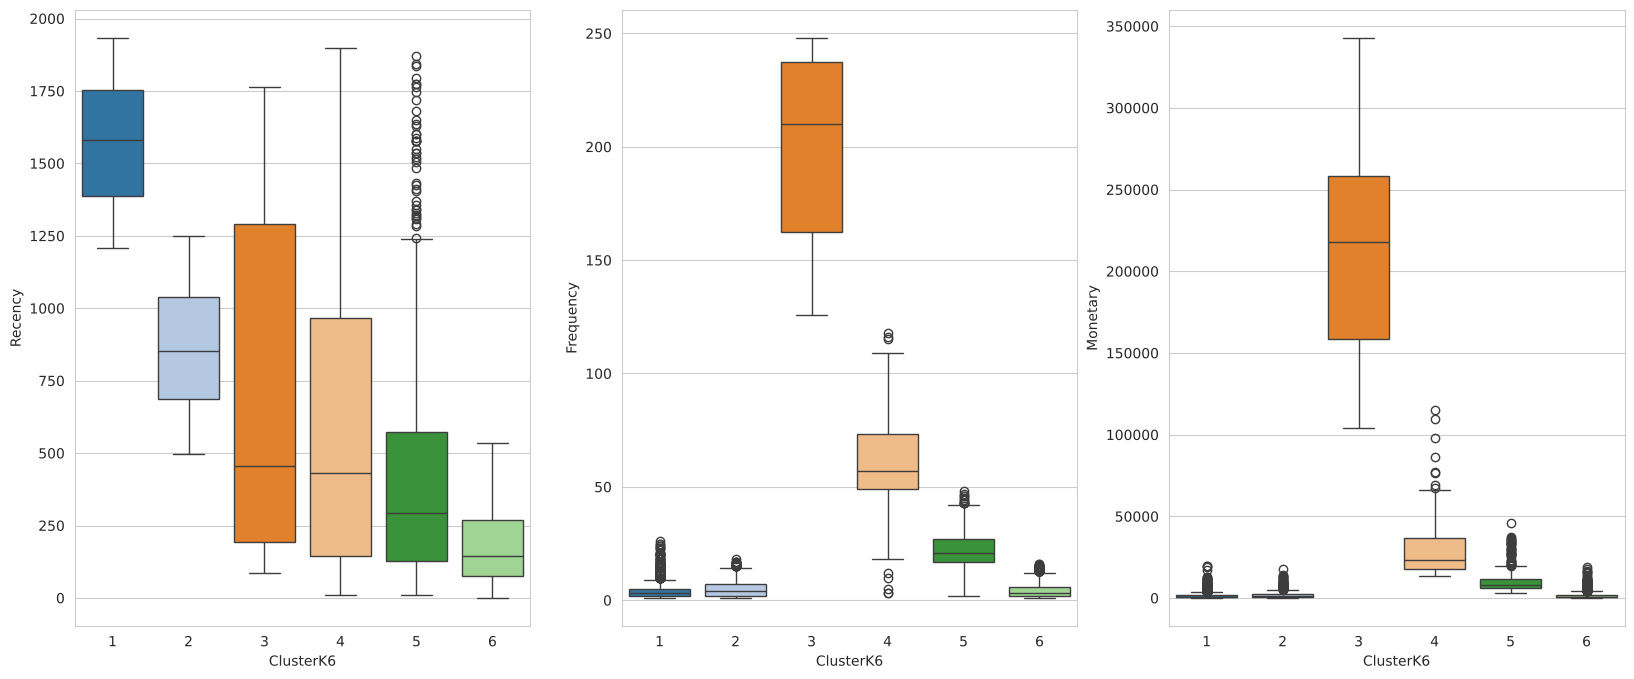

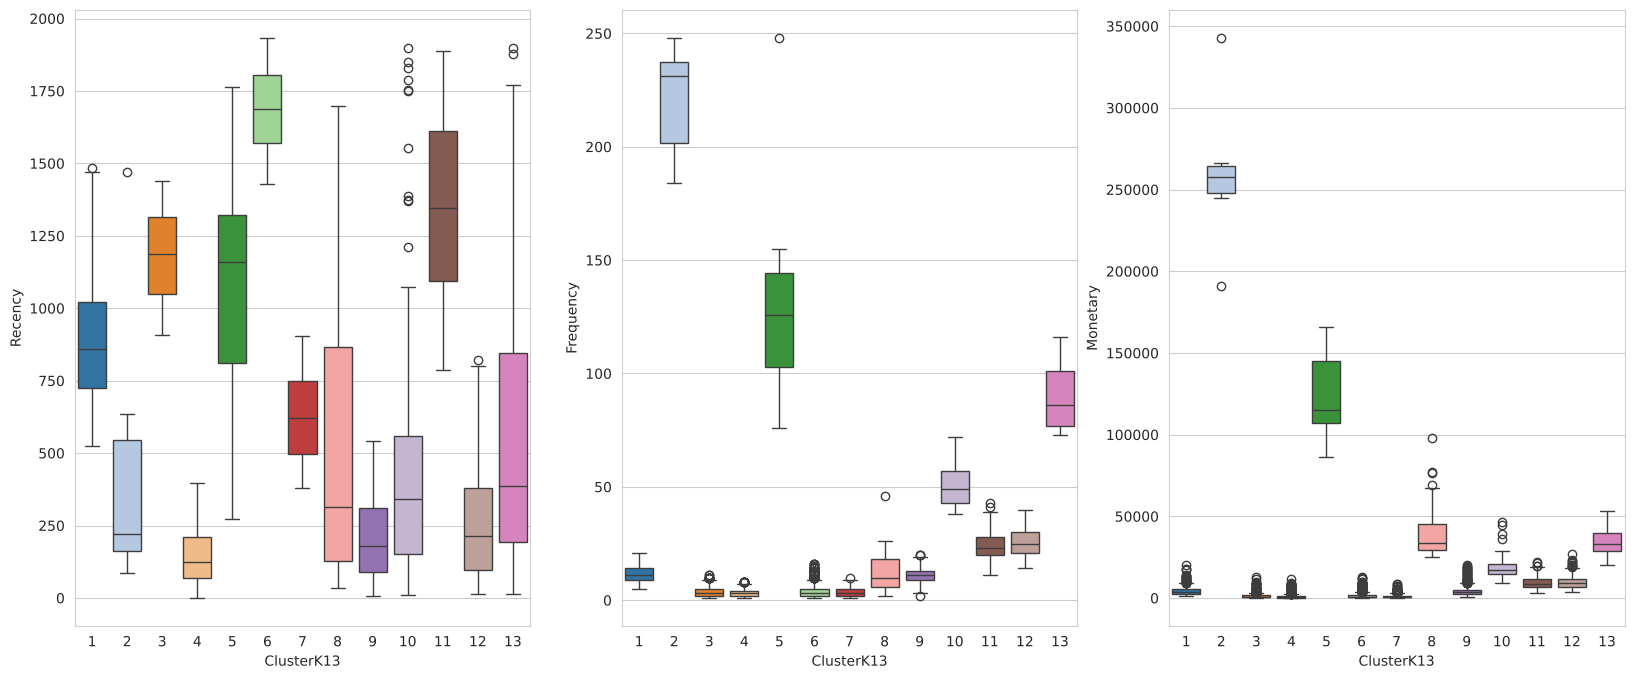

In [45]:
for col in [COL_DBI, COL_CHI]:      # Figure 4.42 (k=6) and Figure 4.43 (k=13)
    plt.figure(figsize=(20, 8))
    plt.subplot(1, 3, 1)
    sns.boxplot(x=LabelledRFMdata[col], y=LabelledRFMdata['Recency'], hue=LabelledRFMdata[col].astype('category'), palette='tab20', legend=False, dodge=False)
    plt.subplot(1, 3, 2)
    sns.boxplot(x=LabelledRFMdata[col], y=LabelledRFMdata['Frequency'], hue=LabelledRFMdata[col].astype('category'), palette='tab20', legend=False, dodge=False)
    plt.subplot(1, 3, 3)
    sns.boxplot(x=LabelledRFMdata[col], y=LabelledRFMdata['Monetary'], hue=LabelledRFMdata[col].astype('category'), palette='tab20', legend=False, dodge=False)
    plt.show()

I took k = 6 forward. Fewer clusters are easier to explain and act on, and more segments don't by themselves make for better marketing.

# CHAPTER 5: RESULTS FINDINGS & DISCUSSIONS
## 5.1 The Outcomes of the K-Means Customer Segmentation (k = 6)
To understand each cluster, I went through the same steps for every one of them.

In [46]:
ClusterGroupK6 = LabelledRFMdata.groupby(by=[COL_DBI])[COL_DBI].count()
ClusterGroups = pd.DataFrame(ClusterGroupK6)
ClusterGroups.columns = ['ClusterSize']
ClusterGroups = ClusterGroups.reset_index()
ClusterGroups = ClusterGroups.rename(columns={COL_DBI: 'ClusterNo'})
ClusterGroups          # Figure 5.1

,ClusterNo,ClusterSize
0,1,2073
1,2,2043
2,3,10
3,4,87
4,5,737
5,6,4277


### RFM quantile-score functions
These are my original scoring functions. Each one reads `QValues`, which I recalculate for each cluster before scoring.

A quirk worth knowing: `Frequency_QScore` only gives a 2 when Frequency is exactly the 25th percentile, so values between Q1 and the median end up with a 1. I've left it unchanged to match the report.

In [47]:
def Recency_QScore(rfm):
    R4 = QValues.Recency[0.75]
    R3 = QValues.Recency[0.5]
    R2 = QValues.Recency[0.25]
    if rfm.Recency <= R2:
        recency_score = 4   #Best, Repeat Buyers
    elif rfm.Recency <= R3:
        recency_score = 3
    elif rfm.Recency <= R4:
        recency_score = 2
    else:
        recency_score = 1
    return recency_score

def Frequency_QScore(rfm):
    F4 = QValues.Frequency[0.75]
    F3 = QValues.Frequency[0.5]
    F2 = QValues.Frequency[0.25]
    if rfm.Frequency >= F4:
        frequency_score = 4   #Best,Consistent Buyers
    elif rfm.Frequency > F3:
        frequency_score = 3
    elif rfm.Frequency == F2:
        frequency_score = 2
    else:
        frequency_score = 1
    return frequency_score

def Monetary_QScore(rfm):
    M4 = QValues.Monetary[0.75]
    M3 = QValues.Monetary[0.5]
    M2 = QValues.Monetary[0.25]
    if rfm.Monetary >= M4:
        monetary_score = 4   #Best,High Spenders
    elif rfm.Monetary >= M3:
        monetary_score = 3
    elif rfm.Monetary >= M2:
        monetary_score = 2
    else:
        monetary_score = 1
    return monetary_score

### Profiling each cluster
For every cluster I looked at the summary statistics, the distributions, boxplots, a pairplot, Monetary against Frequency with a fitted line, their correlation, the quantile scores, and three pie charts of those scores. In my dissertation I repeated these steps cell by cell. Here they are in one function. Clusters with fewer than `MIN_GROUP_SIZE` customers (like my Cluster 5) are not profiled at all, so no individual's figures can be read off.

In [48]:
ClusterGroupN = {}
def profile_cluster(n, min_size_for_plots=10):
    global QValues
    grp = LabelledRFMdata[LabelledRFMdata[COL_DBI] == n][['idMember', 'Recency', 'Frequency', 'Monetary']].copy()
    ClusterGroupN[n] = grp
    print(f"================  Cluster {n}  ({len(grp)} customers)  ================")
    if len(grp) < MIN_GROUP_SIZE:                                   # small-group suppression (thesis listed these rows, Fig 5.31)
        print(f"Fewer than {MIN_GROUP_SIZE} customers: profile suppressed.")
        return grp
    display(grp.describe())                                         # e.g. Figure 5.2
    if len(grp) < min_size_for_plots:
        return grp

    fig, axes = plt.subplots(3, 1, figsize=(9, 8))                  # e.g. Figure 5.3(a)
    for ax, f in zip(axes, nfeatures):
        sns.histplot(grp[f], kde=True, stat='density', ax=ax, alpha=0.4)
    plt.tight_layout(); plt.show()
    fig, axes = plt.subplots(3, 1, figsize=(9, 6))                  # e.g. Figure 5.3(b)
    for ax, f in zip(axes, nfeatures):
        sns.boxplot(x=grp[f], ax=ax)
    plt.tight_layout(); plt.show()

    sns.pairplot(grp[nfeatures]); plt.show()                         # e.g. Figure 5.4
    sns.lmplot(data=grp, x='Monetary', y='Frequency', line_kws={'color': 'red'}); plt.show()   # e.g. Figure 5.5
    display(grp[['Frequency', 'Monetary']].corr())                  # e.g. Figure 5.6

    QValues = grp.quantile([.25, .5, .75, 1])                       # Figure 5.7
    display(QValues)
    grp['RQScore'] = grp.apply(Recency_QScore, axis=1)
    grp['FQScore'] = grp.apply(Frequency_QScore, axis=1)
    grp['MQScore'] = grp.apply(Monetary_QScore, axis=1)
    display(grp.head())                                             # e.g. Figure 5.8

    fig, axes = plt.subplots(1, 3, figsize=(22, 6))                 # e.g. Figure 5.9
    for ax, (c, nm) in zip(axes, [('RQScore', 'R'), ('FQScore', 'F'), ('MQScore', 'M')]):
        vc = grp[c].value_counts()
        plot_pie(vc, f'Density of {nm} Qscore (k={n})', 'Count Values', title=f'The {nm} Qscore(k={n})',
                 colors=sns.color_palette('hls', 4)[:len(vc)], ax=ax)
    plt.show()
    # figures quoted in the thesis bullets
    print(f"Recency  <= Q3 ({QValues.Recency[0.75]:.0f} days): {(grp.Recency <= QValues.Recency[0.75]).mean():.2%}")
    print(f"Frequency >= 2 purchases: {(grp.Frequency >= 2).mean():.2%}")
    med_txt = "median" if MASK_BUSINESS_FIGURES else f"median (RM{QValues.Monetary[0.5]:.0f})"
    print(f"Monetary >= {med_txt}: {(grp.Monetary >= QValues.Monetary[0.5]).mean():.2%}")
    return grp

### 5.1.1 Cluster 1

================  Cluster 1  (2073 customers)  ================


,idMember,Recency,Frequency,Monetary
count,2073.000000,2073.000000,2073.000000,2073.000000
mean,104549.727931,1572.193439,4.418234,1537.215109
std,2681.900151,204.924701,3.489116,1876.285850
min,100005.000000,1207.000000,1.000000,74.140000
25%,102167.000000,1389.000000,2.000000,463.940000
50%,104520.000000,1582.000000,3.000000,899.950000
75%,106881.000000,1752.000000,5.000000,1810.720000
max,109227.000000,1933.000000,26.000000,19874.770000


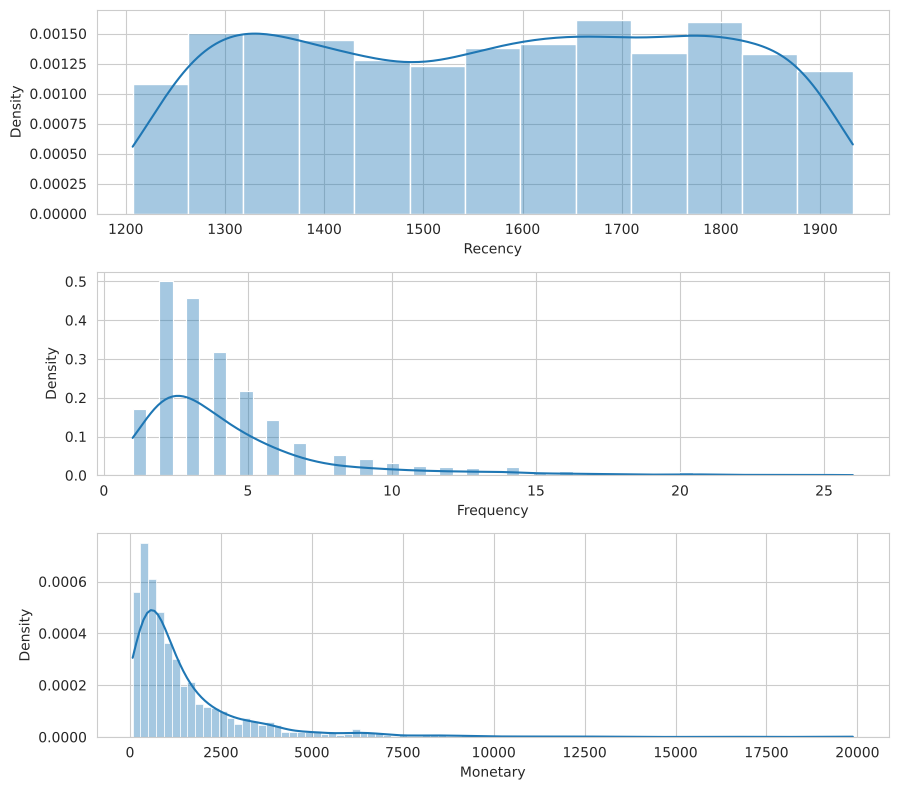

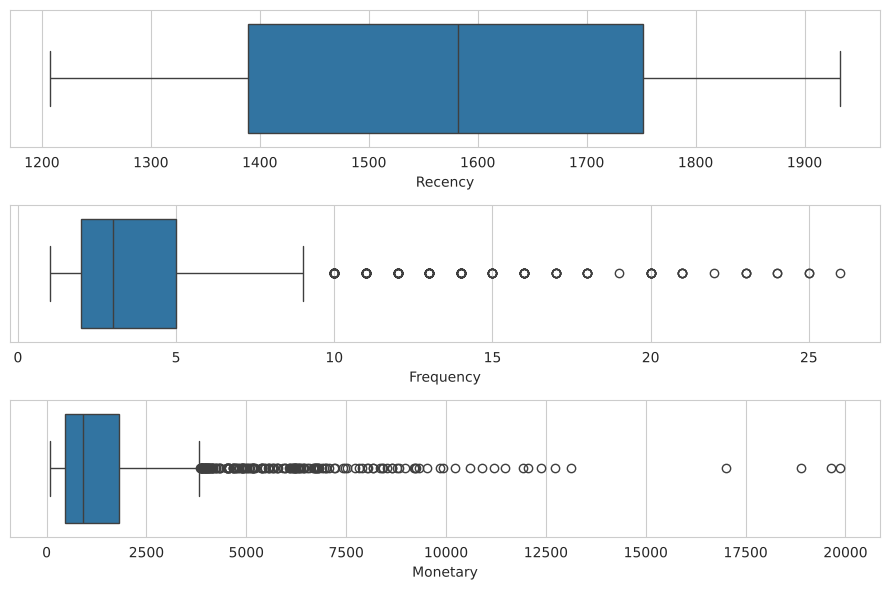

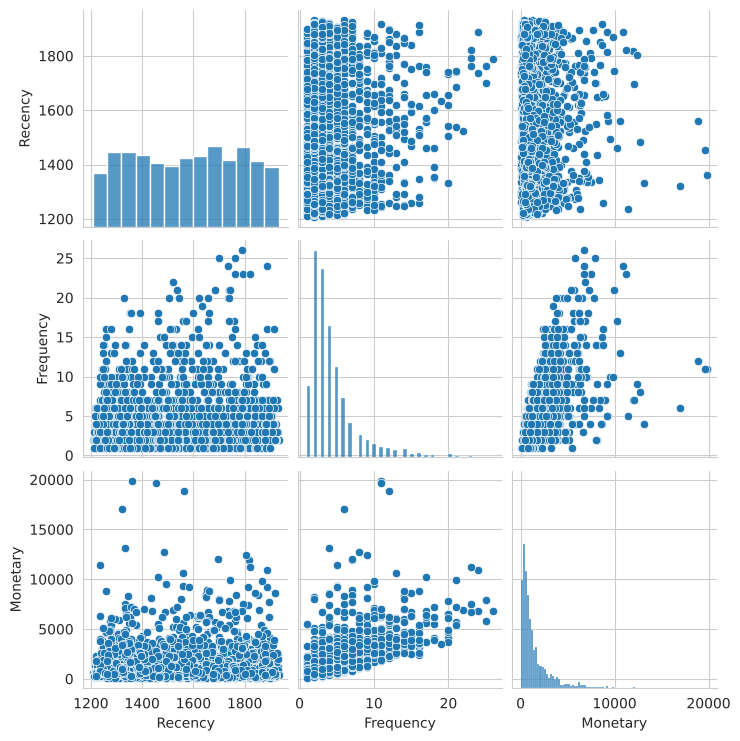

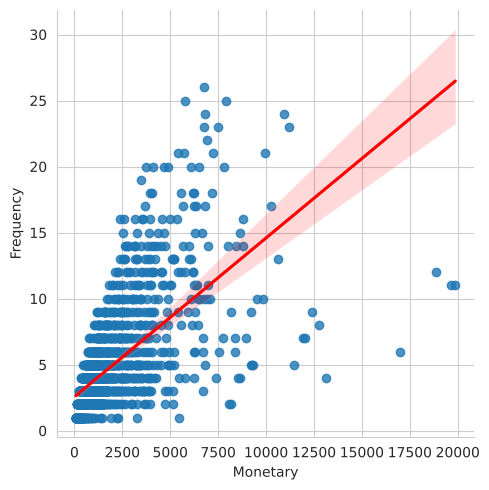

,Frequency,Monetary
Frequency,1.000000,0.646866
Monetary,0.646866,1.000000


,idMember,Recency,Frequency,Monetary
0.25,102167.0,1389.0,2.0,463.94
0.50,104520.0,1582.0,3.0,899.95
0.75,106881.0,1752.0,5.0,1810.72
1.00,109227.0,1933.0,26.0,19874.77


,idMember,Recency,Frequency,Monetary,RQScore,FQScore,MQScore
4,100005,1643,3,862.84,2,1,2
5,100006,1445,3,2728.26,3,1,4
12,100013,1762,1,86.49,1,1,1
14,100015,1397,1,83.74,3,1,1
20,100021,1340,5,1313.32,4,4,3


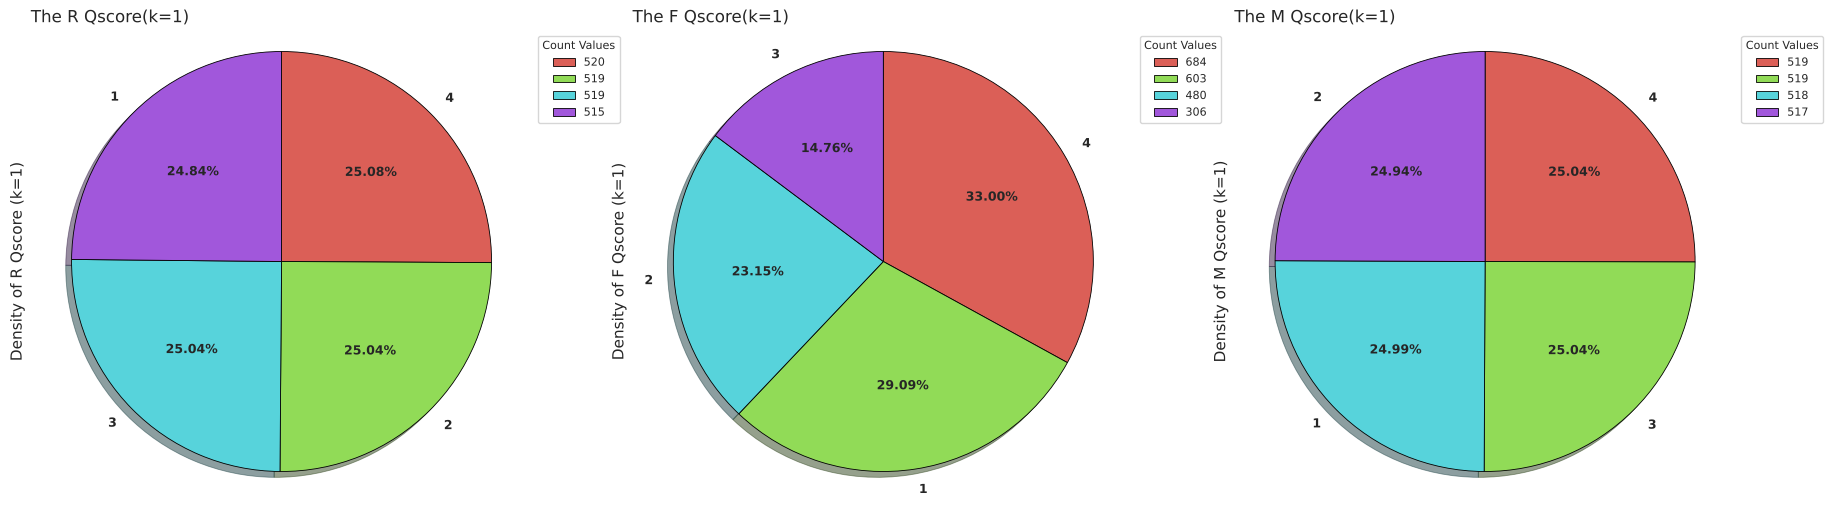

Recency  <= Q3 (1752 days): 75.16%
Frequency >= 2 purchases: 92.04%
Monetary >= median: 50.07%


In [49]:
ClusterGroupN1 = profile_cluster(1) if 1 in counts6.index else None

### 5.1.2 Cluster 2

================  Cluster 2  (2043 customers)  ================


,idMember,Recency,Frequency,Monetary
count,2043.000000,2043.000000,2043.000000,2043.000000
mean,104680.382281,861.089574,5.101322,1767.523984
std,2634.119120,203.931842,3.535328,1832.755359
min,100001.000000,496.000000,1.000000,63.300000
25%,102438.500000,685.000000,2.000000,550.985000
50%,104747.000000,852.000000,4.000000,1183.640000
75%,106960.000000,1038.500000,7.000000,2415.235000
max,109225.000000,1251.000000,18.000000,17655.400000


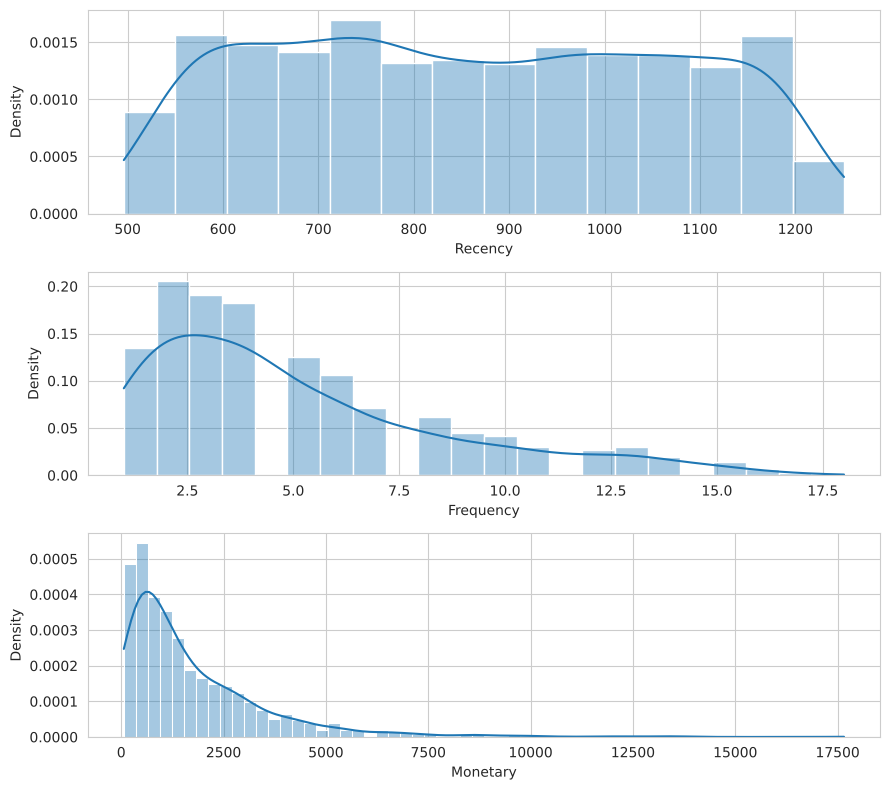

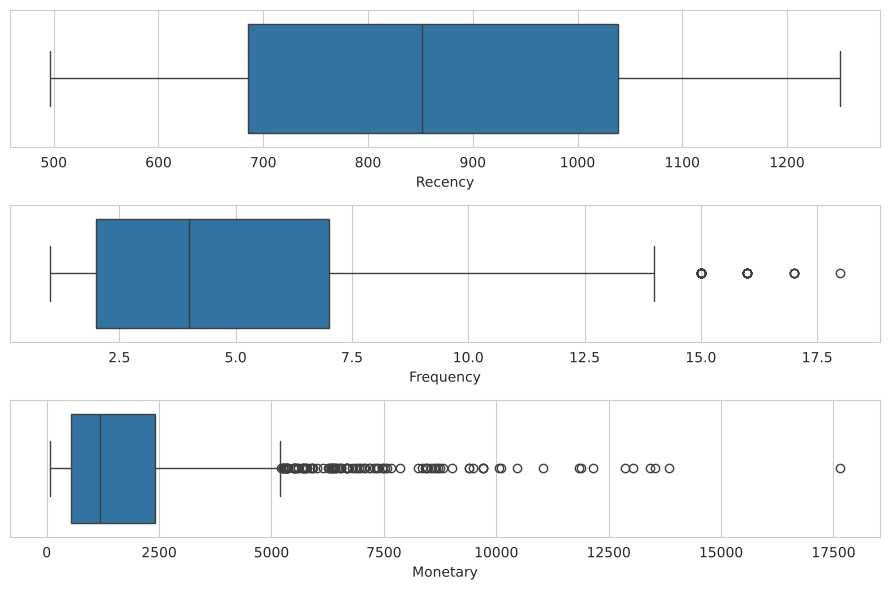

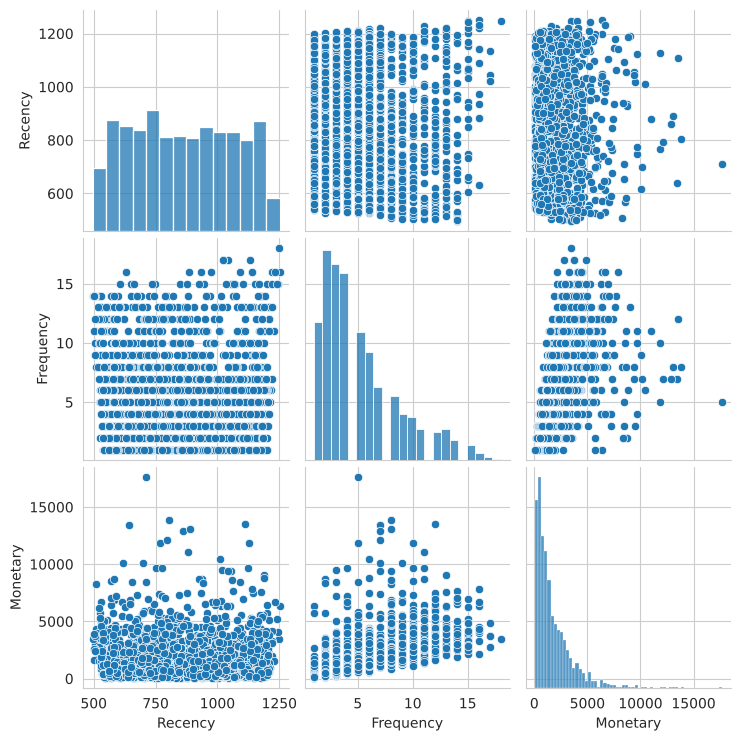

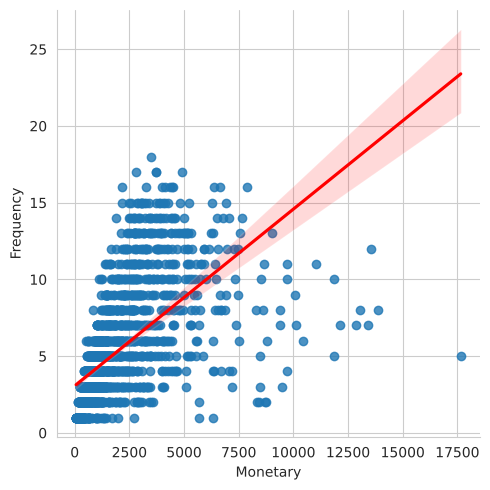

,Frequency,Monetary
Frequency,1.000000,0.596942
Monetary,0.596942,1.000000


,idMember,Recency,Frequency,Monetary
0.25,102438.5,685.0,2.0,550.985
0.50,104747.0,852.0,4.0,1183.640
0.75,106960.0,1038.5,7.0,2415.235
1.00,109225.0,1251.0,18.0,17655.400


,idMember,Recency,Frequency,Monetary,RQScore,FQScore,MQScore
0,100001,558,6,2024.88,4,3,3
1,100002,936,7,1306.48,2,4,3
6,100007,1031,5,1898.46,2,3,3
8,100009,743,11,2537.26,3,4,4
11,100012,922,5,963.67,2,3,2


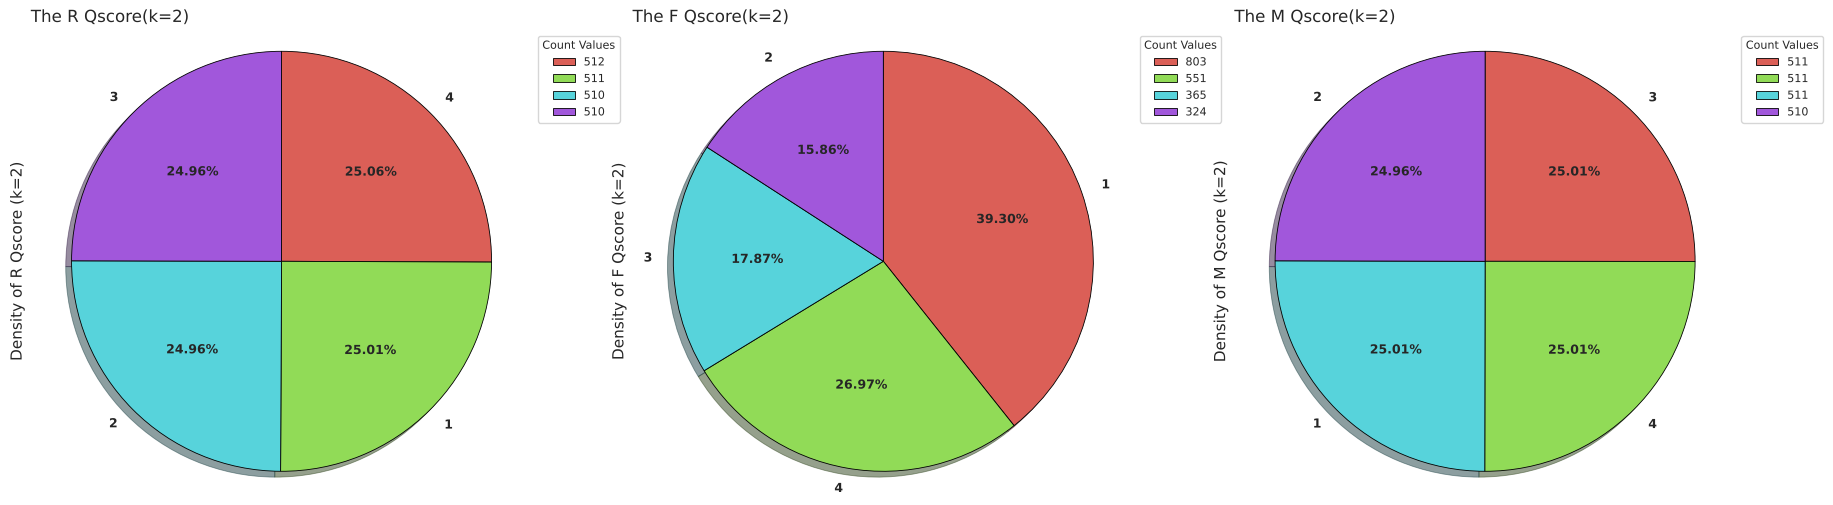

Recency  <= Q3 (1038 days): 74.99%
Frequency >= 2 purchases: 89.57%
Monetary >= median: 50.02%


In [50]:
ClusterGroupN2 = profile_cluster(2) if 2 in counts6.index else None

### 5.1.3 Cluster 3

================  Cluster 3  (10 customers)  ================


,idMember,Recency,Frequency,Monetary
count,10.000000,10.000000,10.000000,10.000000
mean,104496.100000,732.100000,198.800000,212109.869000
std,2542.604153,636.463746,47.321125,73579.336467
min,100958.000000,86.000000,126.000000,104248.550000
25%,102871.750000,192.000000,162.250000,158332.960000
50%,104373.000000,455.000000,210.000000,218115.185000
75%,106169.250000,1289.750000,237.250000,258297.092500
max,108577.000000,1763.000000,248.000000,342793.270000


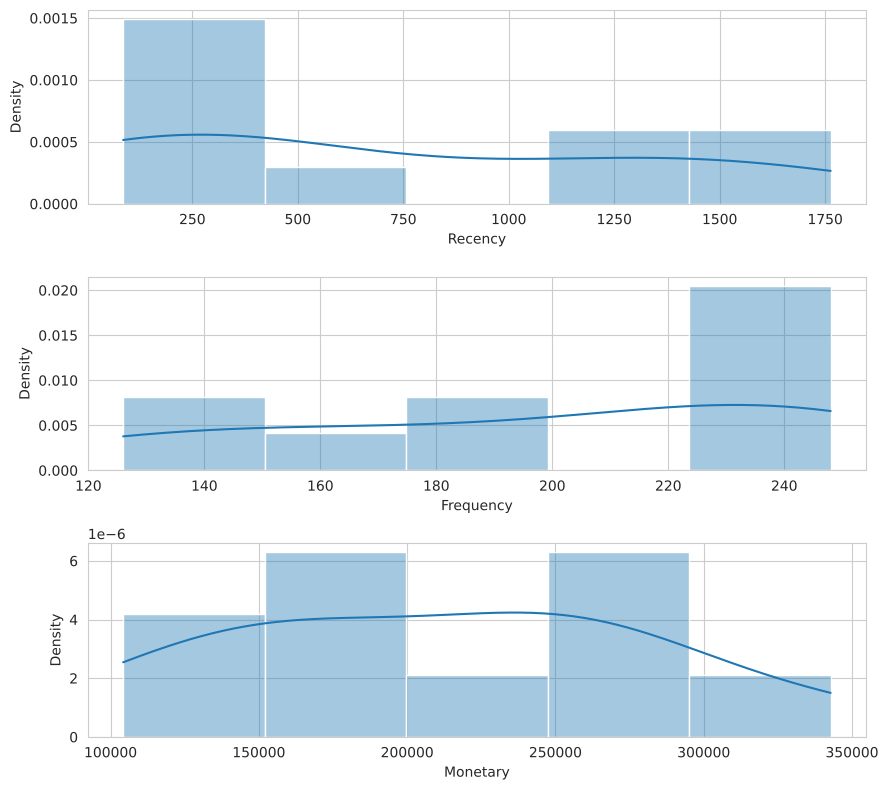

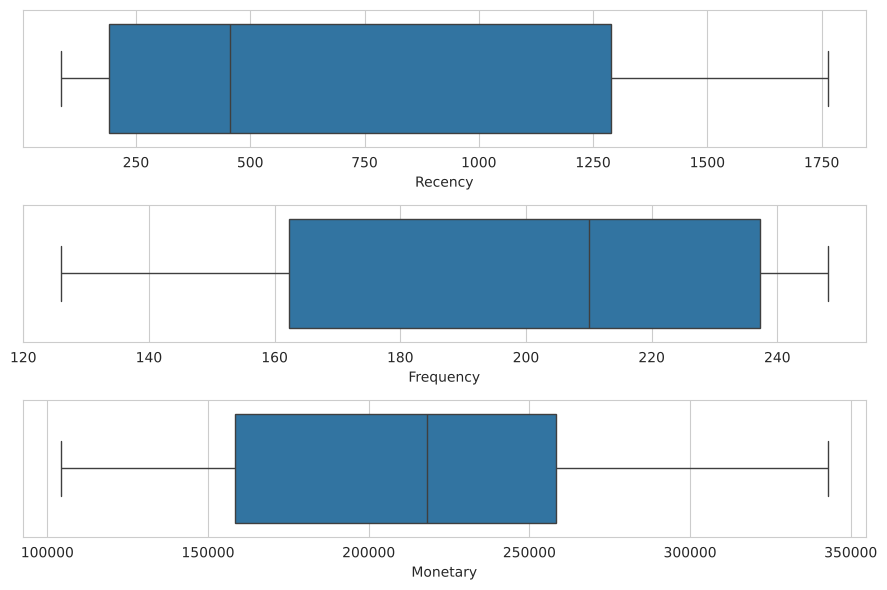

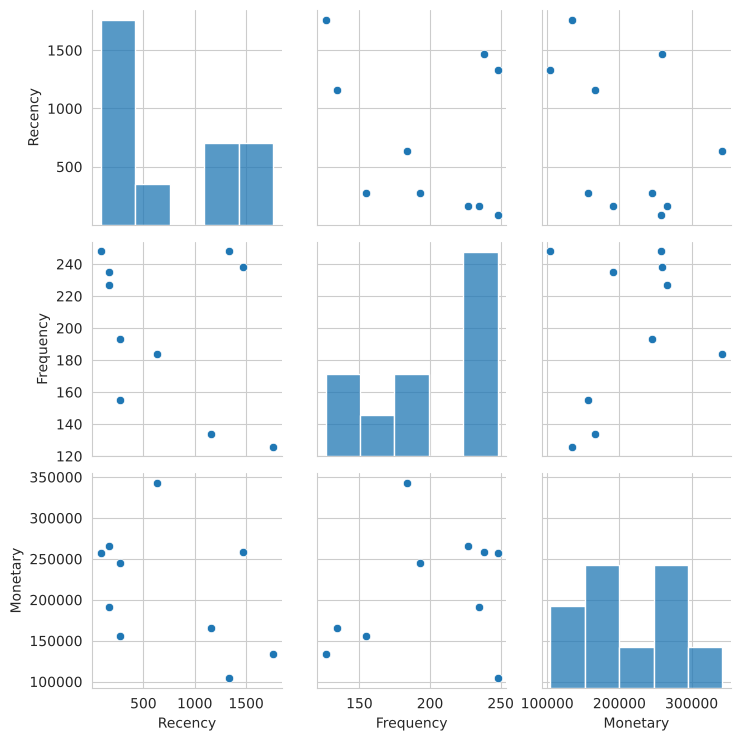

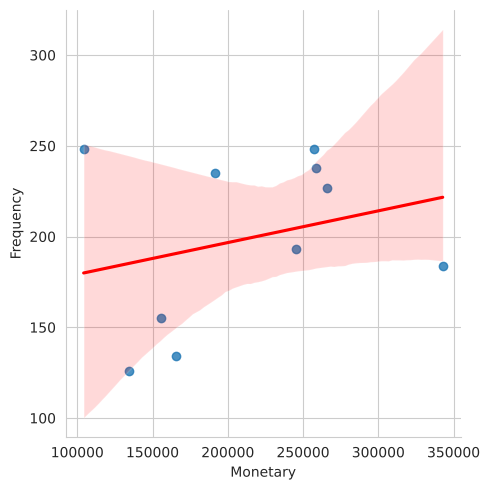

,Frequency,Monetary
Frequency,1.000000,0.271885
Monetary,0.271885,1.000000


,idMember,Recency,Frequency,Monetary
0.25,102871.75,192.00,162.25,158332.9600
0.50,104373.00,455.00,210.00,218115.1850
0.75,106169.25,1289.75,237.25,258297.0925
1.00,108577.00,1763.00,248.00,342793.2700


,idMember,Recency,Frequency,Monetary,RQScore,FQScore,MQScore
957,100958,1763,126,134229.39,1,1,1
1376,101377,273,155,155863.15,3,1,1
2714,102715,1160,134,165742.39,2,1,2
3341,103342,635,184,342793.27,2,1,4
3734,103735,161,235,191228.88,4,3,2


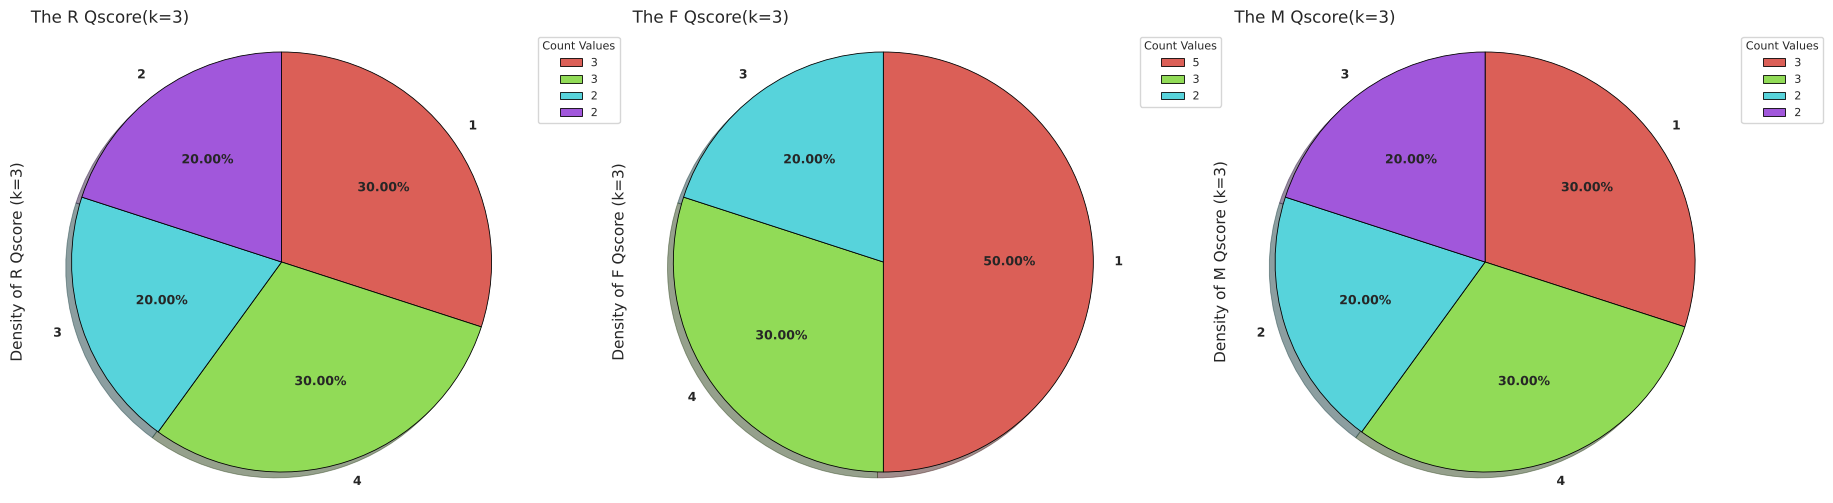

Recency  <= Q3 (1290 days): 70.00%
Frequency >= 2 purchases: 100.00%
Monetary >= median: 50.00%


In [51]:
ClusterGroupN3 = profile_cluster(3) if 3 in counts6.index else None

### 5.1.4 Cluster 4

================  Cluster 4  (87 customers)  ================


,idMember,Recency,Frequency,Monetary
count,87.000000,87.000000,87.000000,87.000000
mean,104466.482759,627.689655,59.977011,31804.351034
std,2793.517133,590.748329,23.956345,21961.965647
min,100080.000000,9.000000,3.000000,13436.350000
25%,102107.500000,144.500000,49.000000,17555.310000
50%,103932.000000,430.000000,57.000000,23458.290000
75%,107059.000000,966.000000,73.500000,37018.875000
max,109155.000000,1899.000000,118.000000,115183.750000


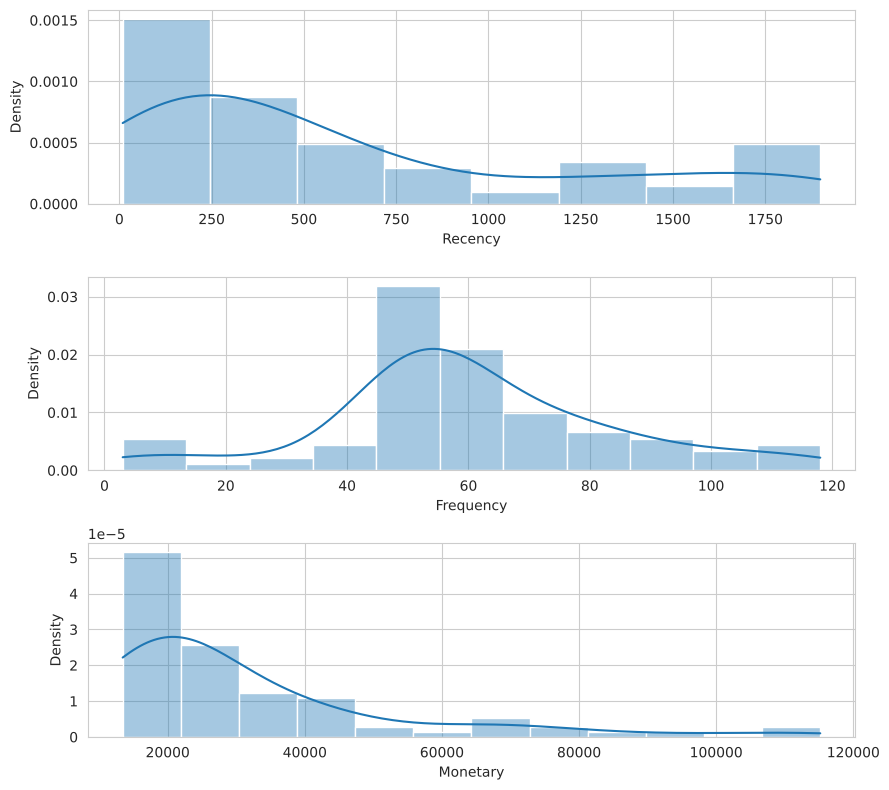

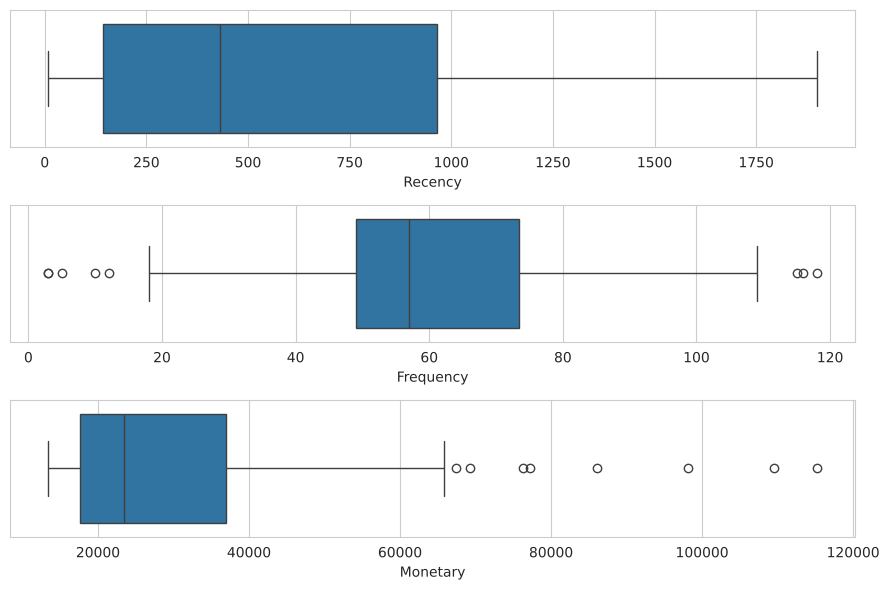

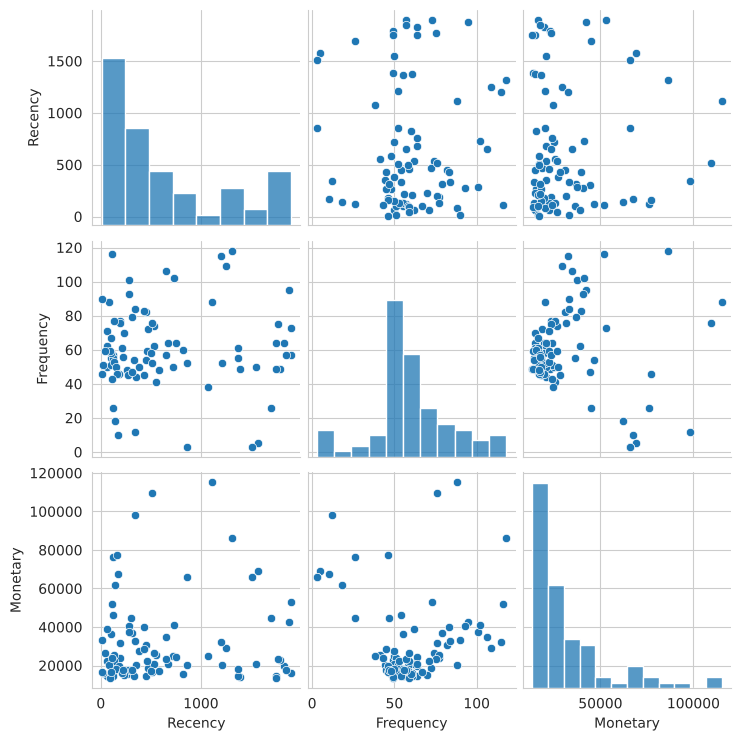

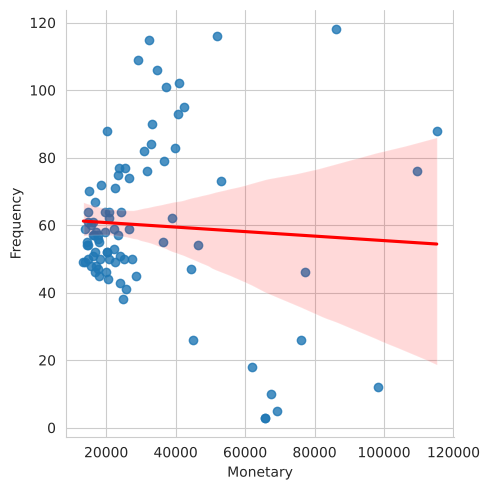

,Frequency,Monetary
Frequency,1.000000,-0.061217
Monetary,-0.061217,1.000000


,idMember,Recency,Frequency,Monetary
0.25,102107.5,144.5,49.0,17555.310
0.50,103932.0,430.0,57.0,23458.290
0.75,107059.0,966.0,73.5,37018.875
1.00,109155.0,1899.0,118.0,115183.750


,idMember,Recency,Frequency,Monetary,RQScore,FQScore,MQScore
79,100080,305,47,44470.23,3,1,4
98,100099,555,41,25703.07,2,1,3
233,100234,1878,95,42425.15,1,4,4
255,100256,533,74,26550.94,2,4,3
355,100356,1830,64,19671.64,1,3,2


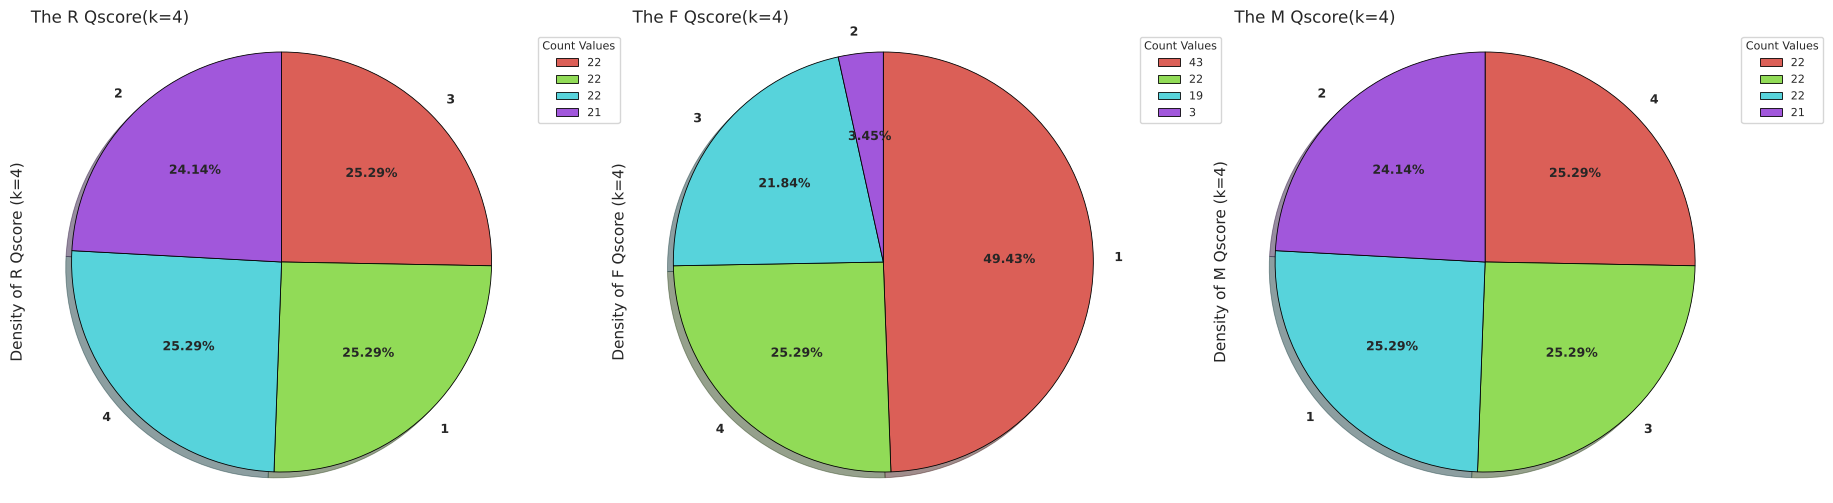

Recency  <= Q3 (966 days): 74.71%
Frequency >= 2 purchases: 100.00%
Monetary >= median: 50.57%


In [52]:
ClusterGroupN4 = profile_cluster(4) if 4 in counts6.index else None

### 5.1.5 Cluster 5

================  Cluster 5  (737 customers)  ================


,idMember,Recency,Frequency,Monetary
count,737.000000,737.000000,737.000000,737.000000
mean,104473.732700,432.450475,22.721845,9703.755197
std,2568.740337,410.740739,7.979421,5907.481154
min,100019.000000,11.000000,2.000000,2851.280000
25%,102266.000000,127.000000,17.000000,5895.190000
50%,104444.000000,292.000000,21.000000,8141.480000
75%,106524.000000,573.000000,27.000000,11495.350000
max,109218.000000,1871.000000,48.000000,45983.870000


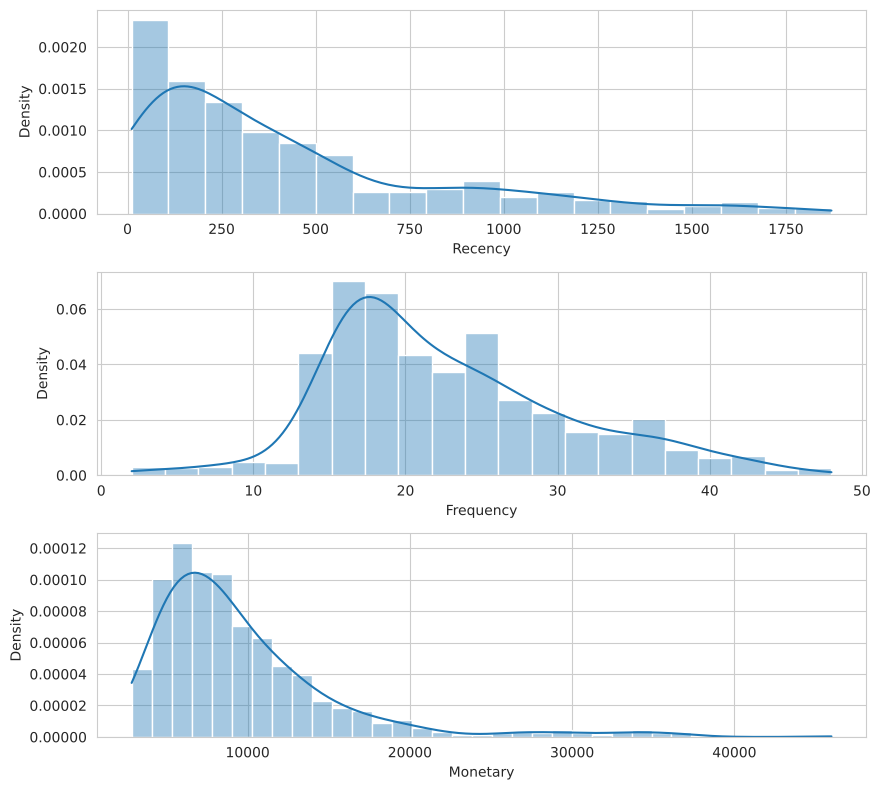

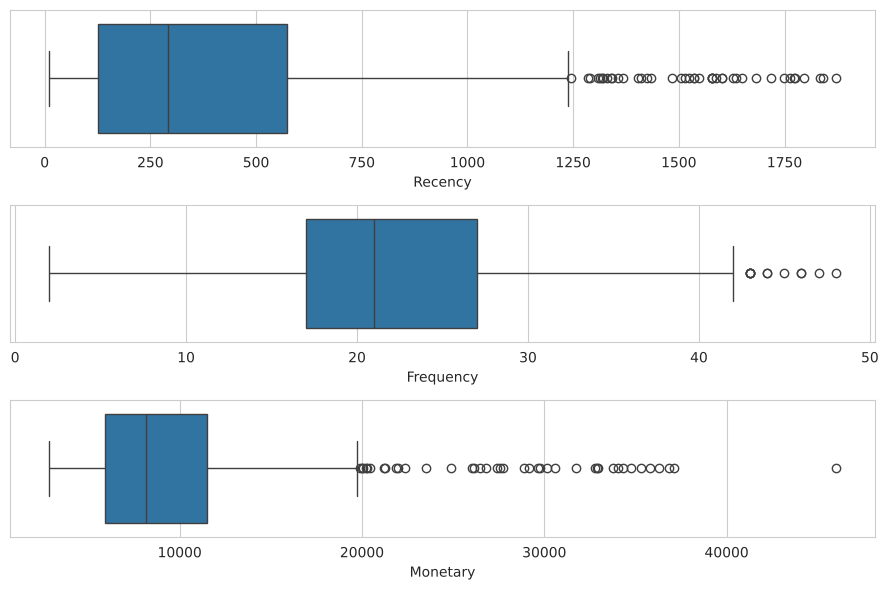

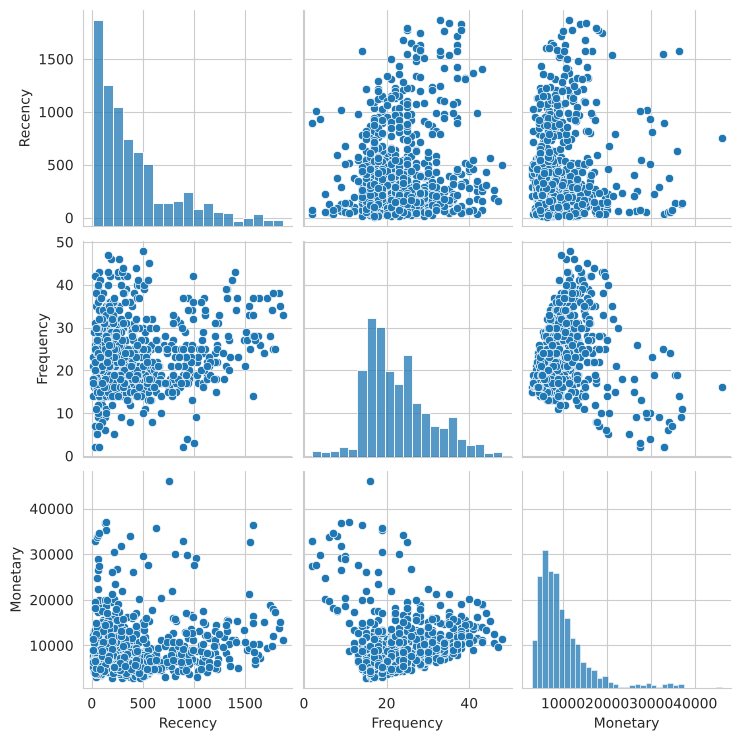

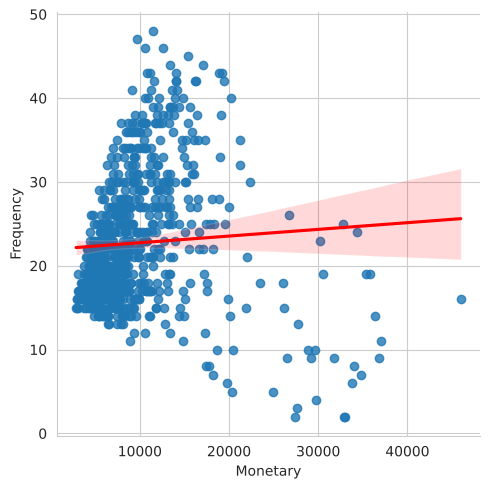

,Frequency,Monetary
Frequency,1.000000,0.059118
Monetary,0.059118,1.000000


,idMember,Recency,Frequency,Monetary
0.25,102266.0,127.0,17.0,5895.19
0.50,104444.0,292.0,21.0,8141.48
0.75,106524.0,573.0,27.0,11495.35
1.00,109218.0,1871.0,48.0,45983.87


,idMember,Recency,Frequency,Monetary,RQScore,FQScore,MQScore
18,100019,299,21,22003.05,2,1,4
33,100034,372,12,10559.71,2,1,3
38,100039,56,17,13115.83,4,2,4
48,100049,528,20,7816.44,2,1,2
53,100054,16,21,12308.61,4,1,4


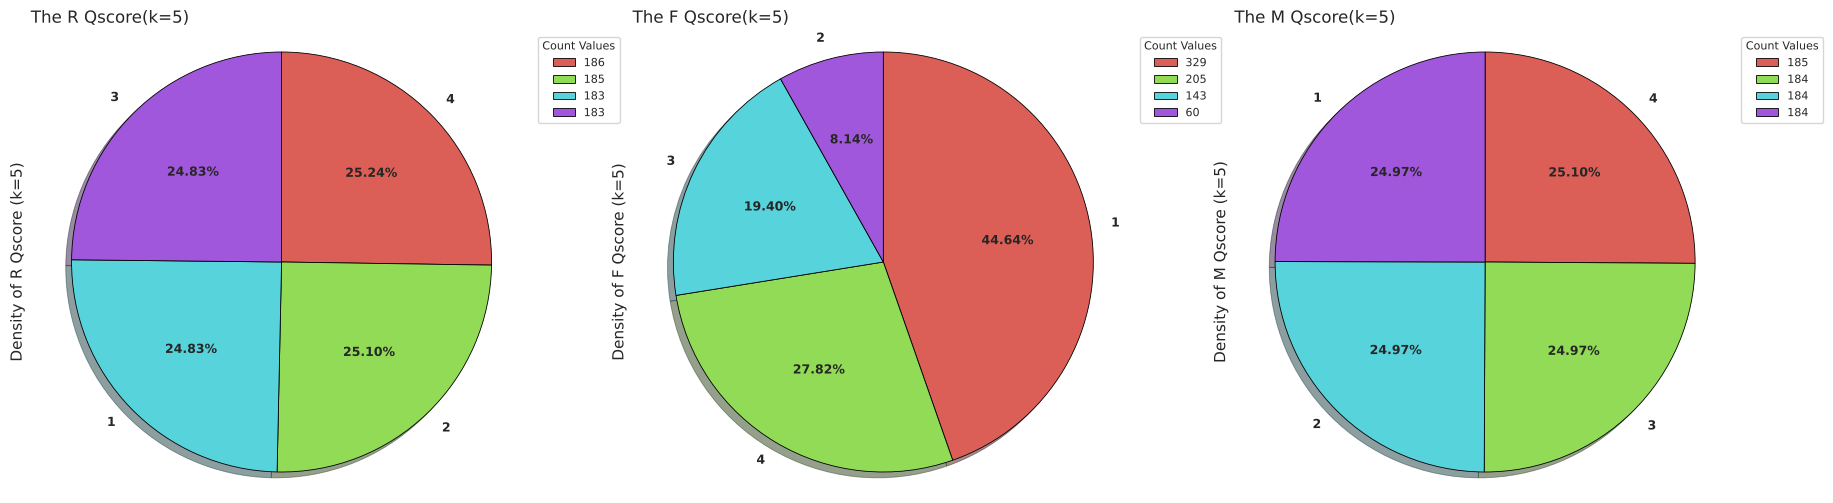

Recency  <= Q3 (573 days): 75.17%
Frequency >= 2 purchases: 100.00%
Monetary >= median: 50.07%


In [53]:
ClusterGroupN5 = profile_cluster(5) if 5 in counts6.index else None

### 5.1.6 Cluster 6

================  Cluster 6  (4277 customers)  ================


,idMember,Recency,Frequency,Monetary
count,4277.000000,4277.000000,4277.000000,4277.000000
mean,104640.889642,184.196867,4.395137,1509.333867
std,2682.492482,132.216405,3.282683,1695.551170
min,100003.000000,0.000000,1.000000,57.580000
25%,102343.000000,76.000000,2.000000,407.830000
50%,104631.000000,146.000000,3.000000,940.020000
75%,106990.000000,269.000000,6.000000,2012.540000
max,109226.000000,535.000000,16.000000,18742.260000


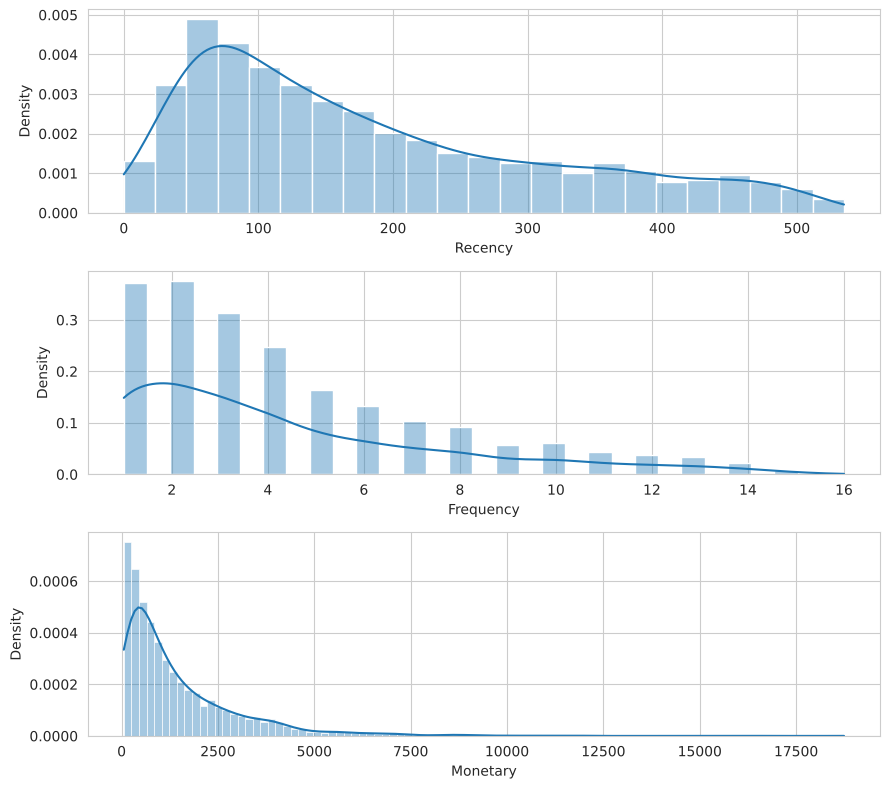

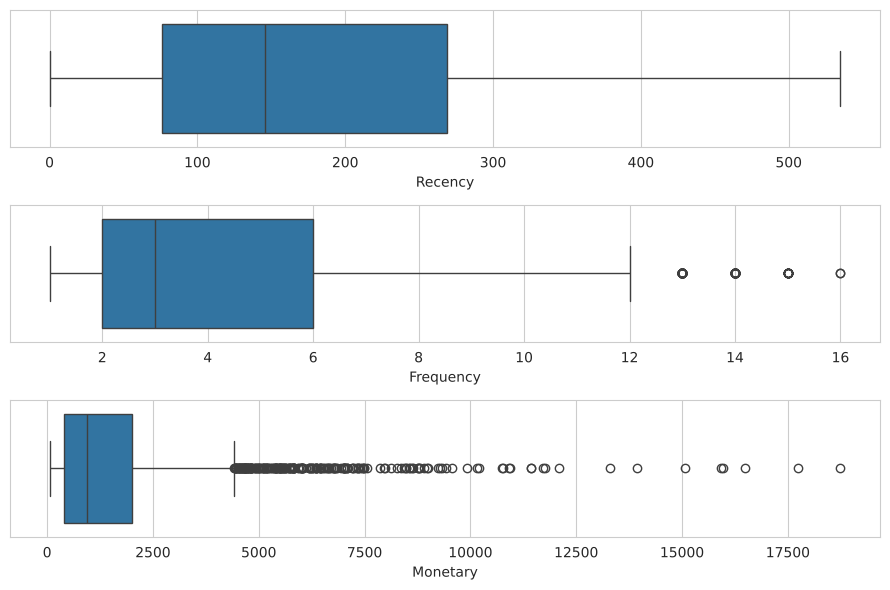

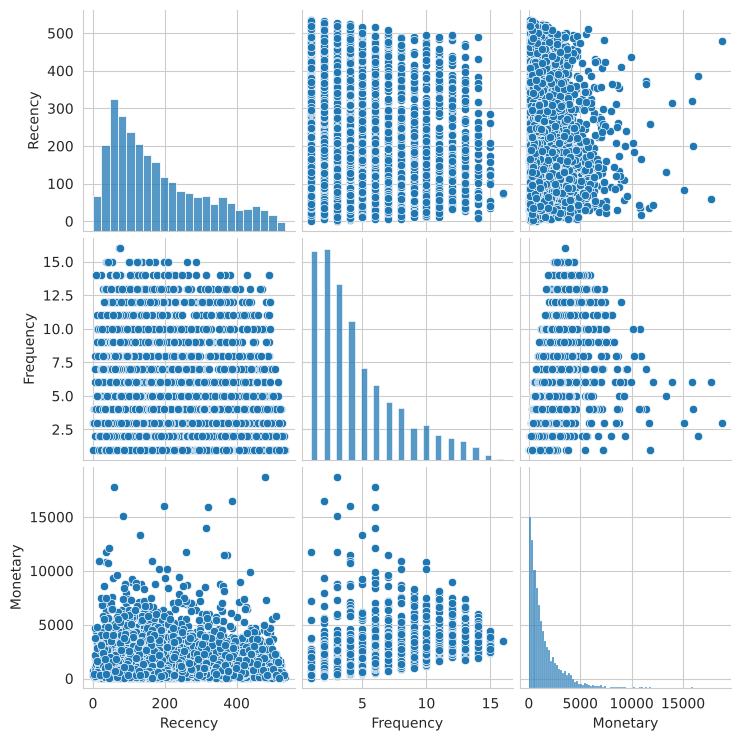

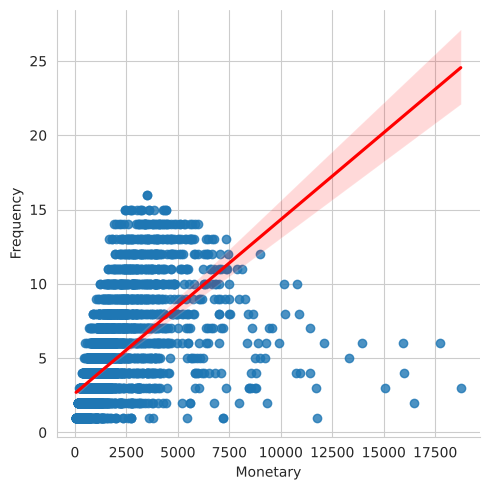

,Frequency,Monetary
Frequency,1.000000,0.604136
Monetary,0.604136,1.000000


,idMember,Recency,Frequency,Monetary
0.25,102343.0,76.0,2.0,407.83
0.50,104631.0,146.0,3.0,940.02
0.75,106990.0,269.0,6.0,2012.54
1.00,109226.0,535.0,16.0,18742.26


,idMember,Recency,Frequency,Monetary,RQScore,FQScore,MQScore
2,100003,136,10,5311.35,3,4,4
3,100004,118,7,2852.42,3,4,4
7,100008,466,10,2379.07,1,4,4
9,100010,380,2,1963.97,1,2,3
10,100011,55,5,784.03,4,3,2


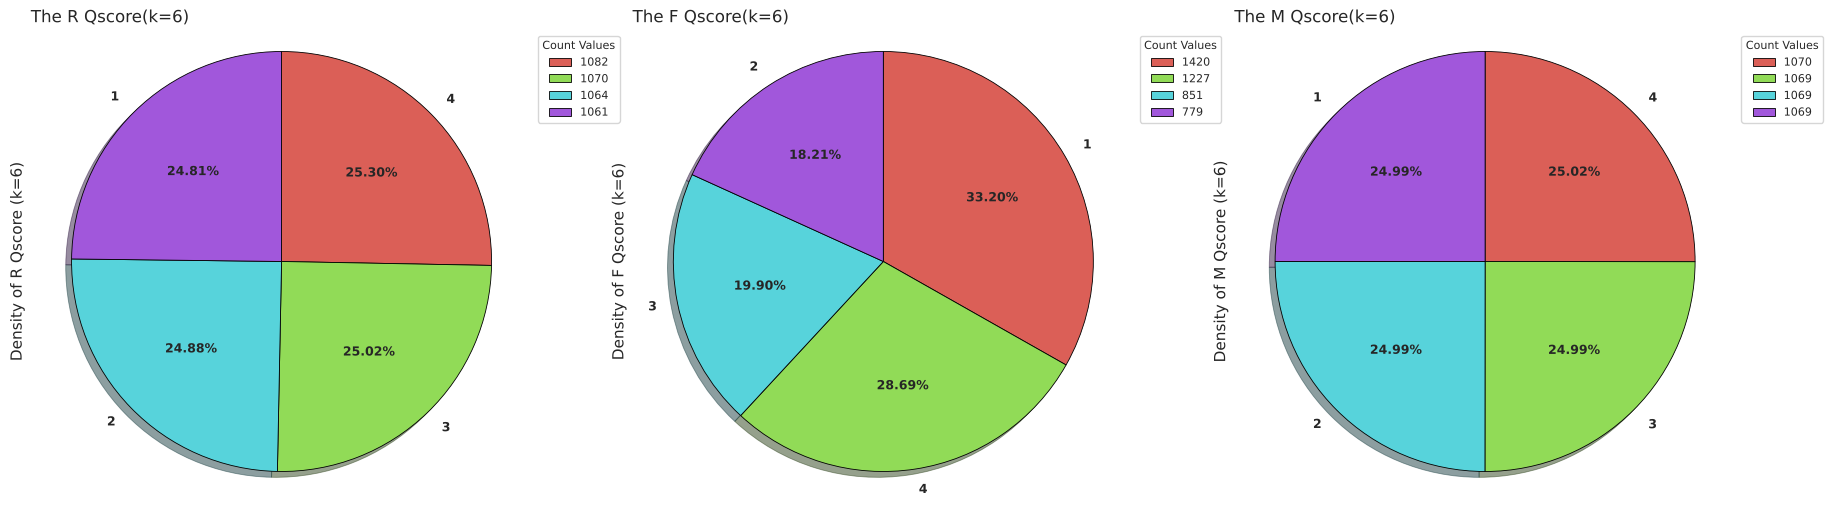

Recency  <= Q3 (269 days): 75.19%
Frequency >= 2 purchases: 82.00%
Monetary >= median: 50.01%


In [54]:
ClusterGroupN6 = profile_cluster(6) if 6 in counts6.index else None

### Summary of the k = 6 segmentation
K-Means numbers its clusters arbitrarily, and they change between runs, so the numbers here won't match my dissertation's. I use the medians in the table below to work out which cluster is which.

This is how I described the six segments in my dissertation (Table 5.1):

| Cluster | Size | What they looked like | What I called them |
|---|---|---|---|
| 1 | 4,204 | bought within the last 619 days, median 2 purchases, mid spend | Recent Active Customer |
| 2 | 1,933 | last purchase 613 – 1,399 days ago, median 3 purchases, mid spend | Attention Needed Customer |
| 3 | 113 | at least 24 purchases, high spend, mostly recent | Top Loyal Customer |
| 4 | 2,236 | last purchase at least 1,321 days ago, low spend | Lost Customer |
| 5 | 4 | very recent, very frequent, by far the highest spend (exact ranges withheld: fewer than 5 customers) | Champion Customer |
| 6 | 737 | mostly within the last year, at least 5 purchases, high spend | Loyal Customer |

Frequency and Monetary were clearly correlated in most clusters (r = 0.698, 0.571, 0.647 and 0.274), and only weakly in Cluster 3.

In [55]:
Summary_k6 = (LabelledRFMdata.groupby(COL_DBI)
              .agg(ClusterSize=('idMember', 'size'),
                   Recency_median=('Recency', 'median'), Recency_min=('Recency', 'min'), Recency_max=('Recency', 'max'),
                   Frequency_median=('Frequency', 'median'), Monetary_median=('Monetary', 'median'),
                   Monetary_min=('Monetary', 'min'),
                   corr_F_M=('Frequency', lambda s: s.corr(LabelledRFMdata.loc[s.index, 'Monetary']))))
Summary_k6 = Summary_k6.astype(float)
Summary_k6.loc[Summary_k6.ClusterSize < MIN_GROUP_SIZE, Summary_k6.columns != 'ClusterSize'] = np.nan   # suppressed: group too small
Summary_k6

,ClusterSize,Recency_median,Recency_min,Recency_max,Frequency_median,Monetary_median,Monetary_min,corr_F_M
ClusterK6,,,,,,,,
1,2073.0,1582.0,1207.0,1933.0,3.0,899.950,74.14,0.646866
2,2043.0,852.0,496.0,1251.0,4.0,1183.640,63.30,0.596942
3,10.0,455.0,86.0,1763.0,210.0,218115.185,104248.55,0.271885
4,87.0,430.0,9.0,1899.0,57.0,23458.290,13436.35,-0.061217
5,737.0,292.0,11.0,1871.0,21.0,8141.480,2851.28,0.059118
6,4277.0,146.0,0.0,535.0,3.0,940.020,57.58,0.604136


## 5.2 Data Scaling with Normalization on RFM feature
Next I tried adding a MinMax scaling on top of the standardised data and ran the same CHI / DBI search again.

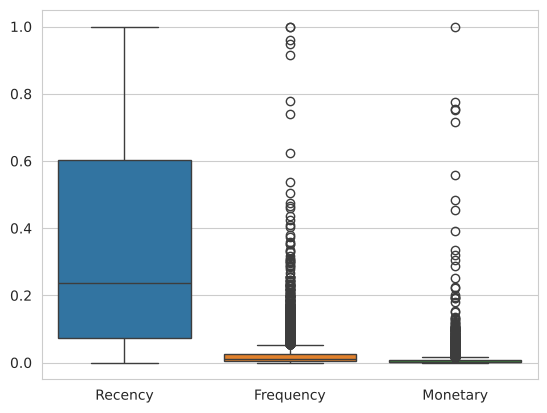

In [56]:
mm = MinMaxScaler()
StandardMinMaxRFMdata = pd.DataFrame(mm.fit_transform(TransformedRFMdata[nfeatures]), columns=nfeatures)
sns.boxplot(data=StandardMinMaxRFMdata)      # Figure 5.39
plt.show()

In [57]:
start_time = time.time()
calinski_avgs = []
min_k = 2
Xdata3 = StandardMinMaxRFMdata

for k in range(min_k, 15):
    kmeanCHI = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(Xdata3)
    score3 = metrics.calinski_harabasz_score(Xdata3, kmeanCHI.labels_)
    print("Calinski Harabasz Index for k =", k, "is", score3)
    calinski_avgs.append(score3)

Optimal_K3 = calinski_avgs.index(max(calinski_avgs)) + min_k
print("Optimal K is", Optimal_K3)
t3 = time.time() - start_time
print("--- %s seconds ---" % t3)       # Figure 5.40(a)

Calinski Harabasz Index for k = 2 is 33485.05281731671


Calinski Harabasz Index for k = 3 is 38173.78661247221
Calinski Harabasz Index for k = 4 is 39938.17846861607
Calinski Harabasz Index for k = 5 is 39837.99090218588
Calinski Harabasz Index for k = 6 is 39366.55951251182
Calinski Harabasz Index for k = 7 is 41049.506323162255


Calinski Harabasz Index for k = 8 is 40800.52009342765


Calinski Harabasz Index for k = 9 is 40937.34792889583
Calinski Harabasz Index for k = 10 is 42085.13722476315
Calinski Harabasz Index for k = 11 is 42318.086398610176


Calinski Harabasz Index for k = 12 is 42054.94223027113
Calinski Harabasz Index for k = 13 is 41922.39511081864
Calinski Harabasz Index for k = 14 is 41934.77968677952
Optimal K is 11
--- 0.6715049743652344 seconds ---


In [58]:
start_time = time.time()
davies_avgs = []
min_k = 2
Xdata4 = StandardMinMaxRFMdata

for k in range(min_k, 15):
    kmeanDBI = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(Xdata4)
    score4 = metrics.davies_bouldin_score(Xdata4, kmeanDBI.labels_)
    print("Davies Bouldin Index for k =", k, "is", score4)
    davies_avgs.append(score4)

Optimal_K4 = davies_avgs.index(min(davies_avgs)) + min_k
print("Optimal K is", Optimal_K4)
t4 = time.time() - start_time
print("--- %s seconds ---" % t4)       # Figure 5.40(b)

Davies Bouldin Index for k = 2 is 0.4416457392975412
Davies Bouldin Index for k = 3 is 0.5162311524953082
Davies Bouldin Index for k = 4 is 0.5428716204881385
Davies Bouldin Index for k = 5 is 0.6045429798085873
Davies Bouldin Index for k = 6 is 0.5515994702659973


Davies Bouldin Index for k = 7 is 0.5899251209298271
Davies Bouldin Index for k = 8 is 0.6348847452100119
Davies Bouldin Index for k = 9 is 0.669804657992372
Davies Bouldin Index for k = 10 is 0.6742098468983775


Davies Bouldin Index for k = 11 is 0.683190232688857
Davies Bouldin Index for k = 12 is 0.6999462498428031
Davies Bouldin Index for k = 13 is 0.707979789621506


Davies Bouldin Index for k = 14 is 0.7319697695492072
Optimal K is 2
--- 0.7999324798583984 seconds ---


This time CHI peaked at k = 10 (53,691.91) and DBI was lowest at k = 2 (0.3991).

In [59]:
K_CHI2, K_DBI2 = (10, 2) if USE_THESIS_K else (Optimal_K3, Optimal_K4)
COL_CHI2, COL_DBI2 = f'ClusterK{K_CHI2}', f'ClusterK{K_DBI2}'

newLabelRDFMdata = pd.DataFrame(RFMdata)

XData10 = StandardMinMaxRFMdata
kMeanXK10 = KMeans(n_clusters=K_CHI2, n_init=N_INIT, random_state=RANDOM_STATE).fit(XData10)
KMeanLabelK10 = kMeanXK10.fit_predict(XData10)
ClusterIDK10 = KMeanLabelK10 + 1
newLabelRDFMdata[COL_CHI2] = ClusterIDK10

XData2 = StandardMinMaxRFMdata
kMeanXK2 = KMeans(n_clusters=K_DBI2, n_init=N_INIT, random_state=RANDOM_STATE).fit(XData2)
KMeanLabelK2 = kMeanXK2.fit_predict(XData2)
ClusterIDK2 = KMeanLabelK2 + 1
newLabelRDFMdata[COL_DBI2] = ClusterIDK2

newLabelRDFMdata.head(5)     # Figure 5.41

,idMember,Recency,Frequency,Monetary,ClusterK13,ClusterK6,ClusterK10,ClusterK2
0,100001,558,6,2024.88,7,2,4,1
1,100002,936,7,1306.48,3,2,1,2
2,100003,136,10,5311.35,9,6,2,1
3,100004,118,7,2852.42,4,6,2,1
4,100005,1643,3,862.84,6,1,3,2


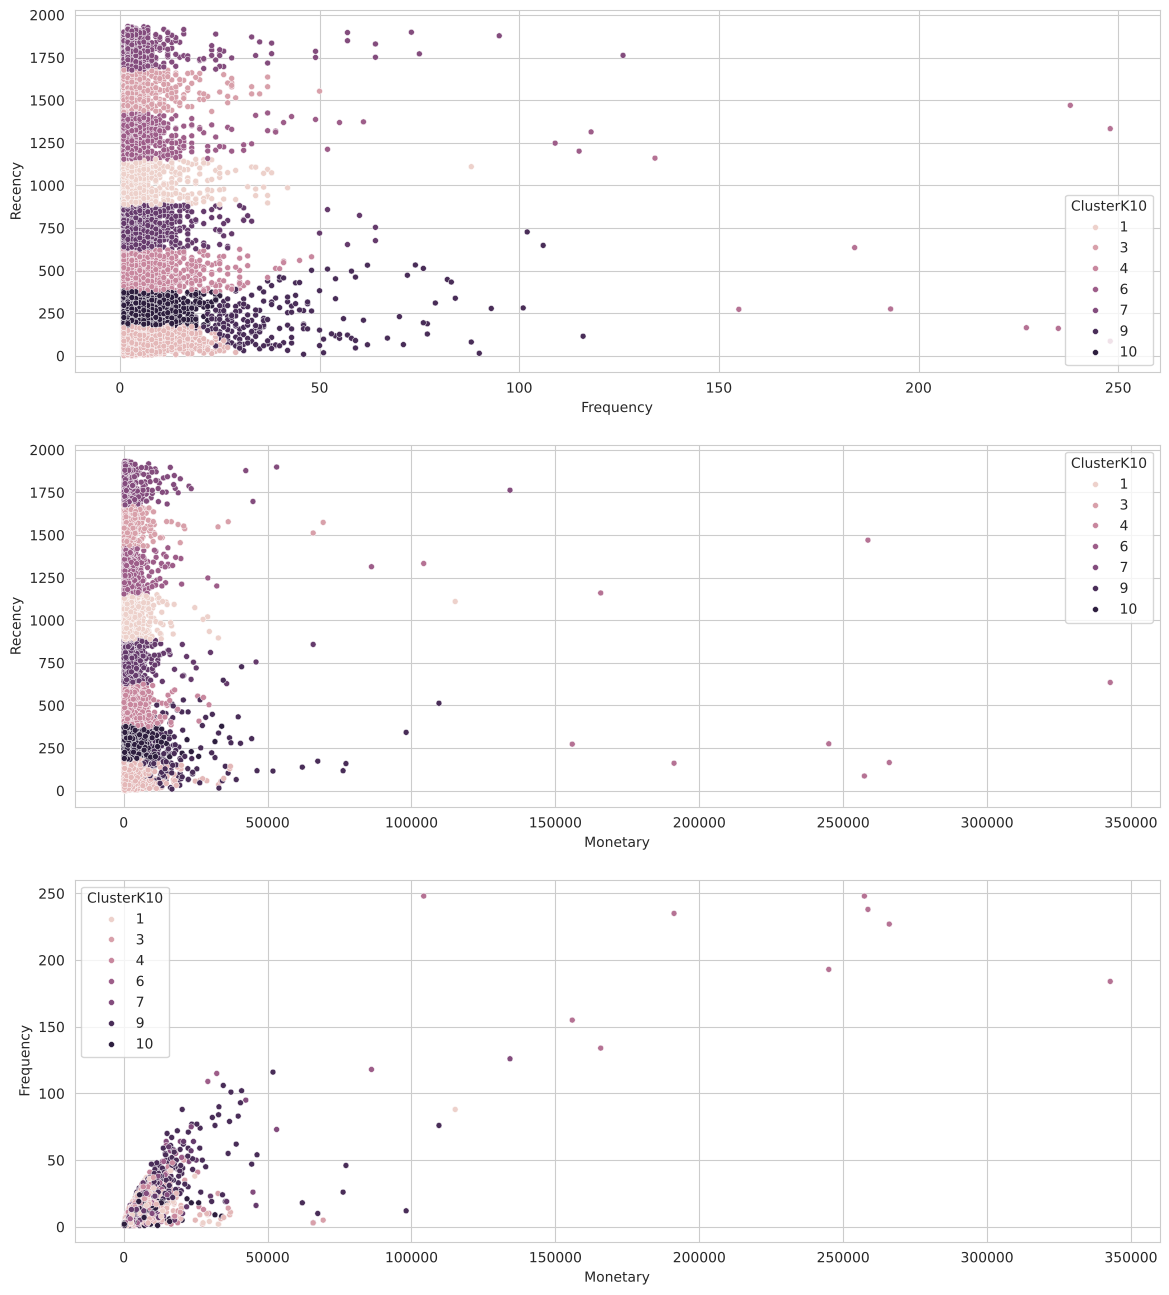

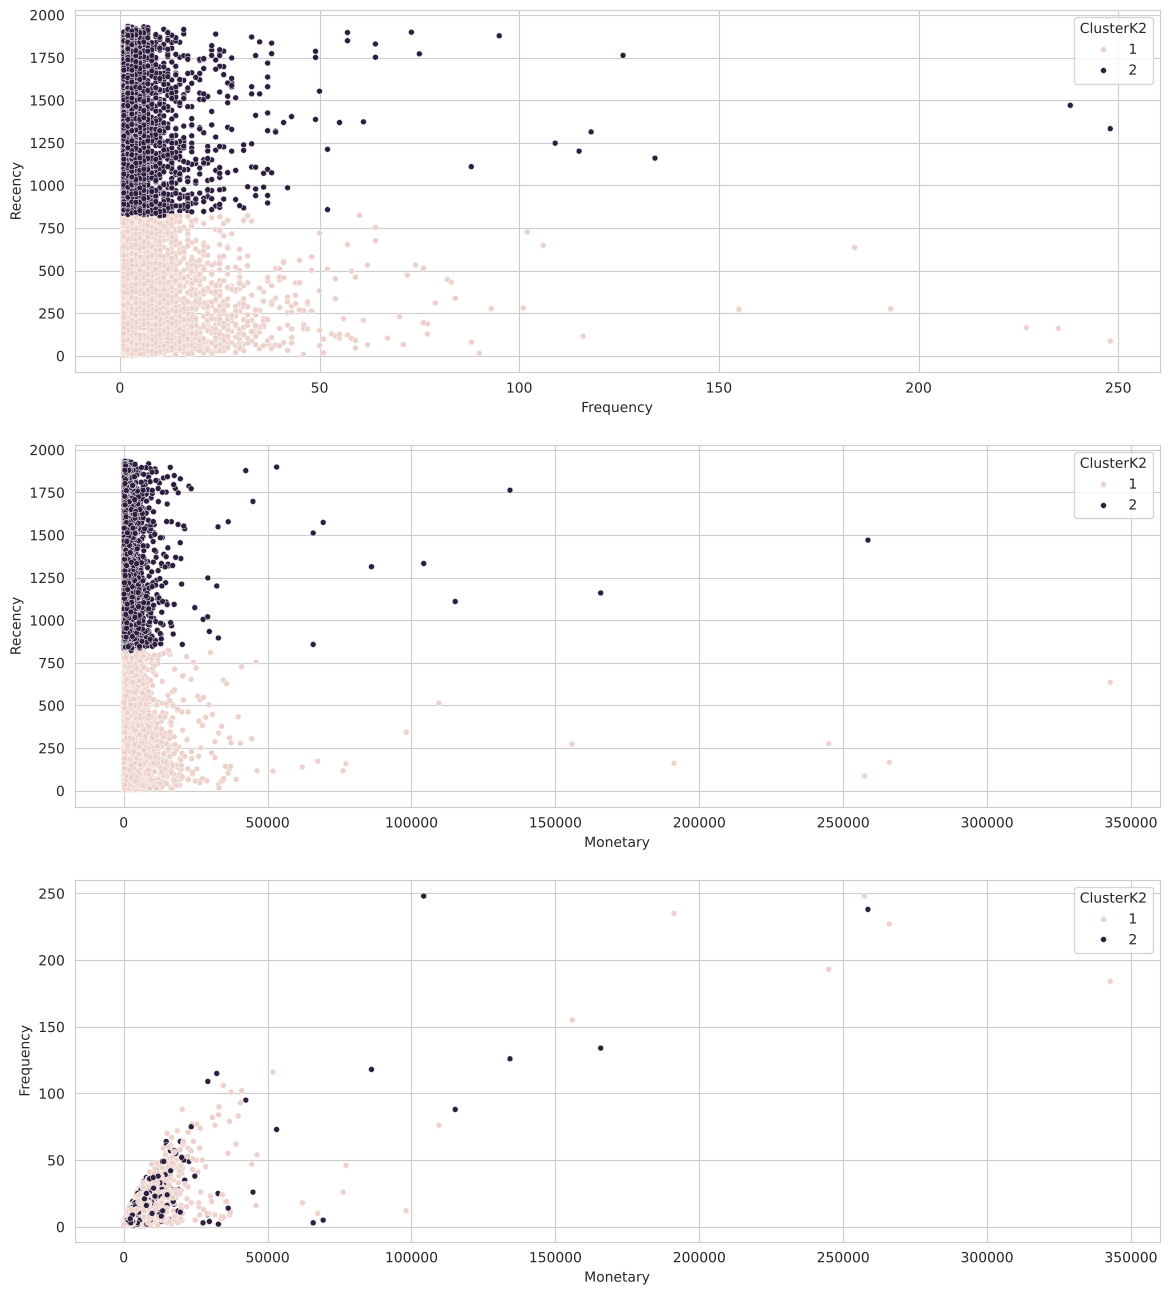

In [60]:
plot_rfm_pairs(newLabelRDFMdata, COL_CHI2)    # Figure 5.42
plot_rfm_pairs(newLabelRDFMdata, COL_DBI2)    # Figure 5.43

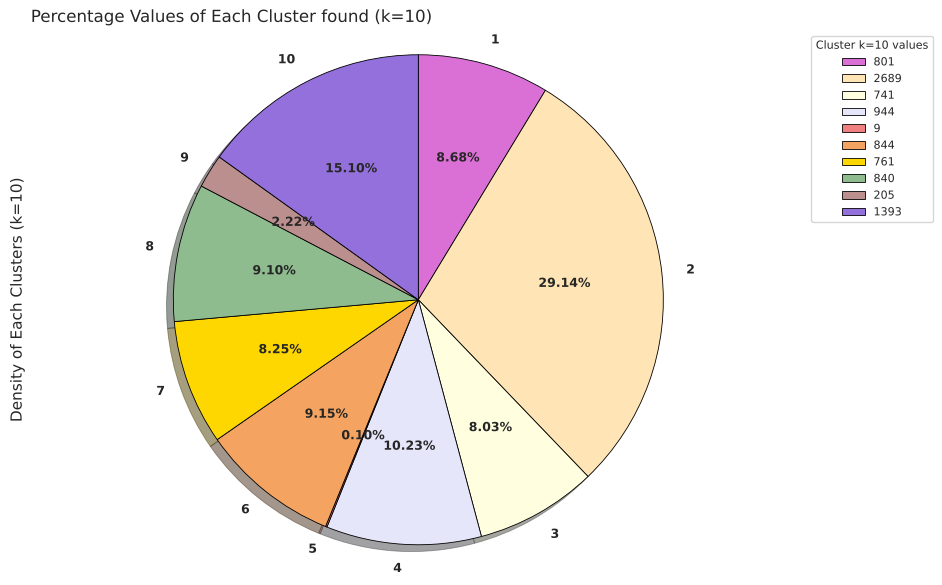

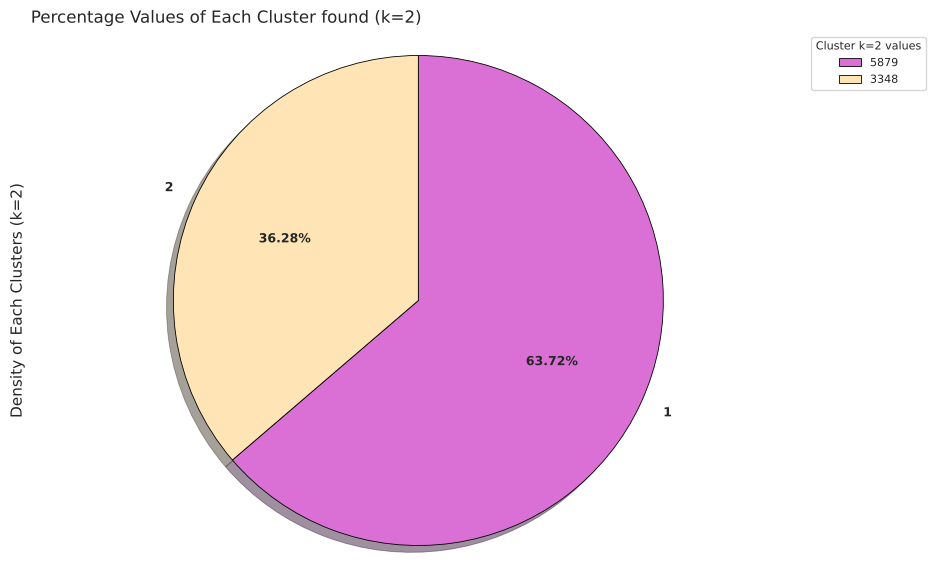

In [61]:
c10 = newLabelRDFMdata[COL_CHI2].value_counts().sort_index()
plot_pie(c10, f'Density of Each Clusters (k={K_CHI2})', f'Cluster k={K_CHI2} values',
         title=f'Percentage Values of Each Cluster found (k={K_CHI2})')       # Figure 5.44
plt.show()
c2 = newLabelRDFMdata[COL_DBI2].value_counts().sort_index()
plot_pie(c2, f'Density of Each Clusters (k={K_DBI2})', f'Cluster k={K_DBI2} values',
         title=f'Percentage Values of Each Cluster found (k={K_DBI2})')       # Figure 5.45
plt.show()

With k = 10, my cluster sizes were 1,011 · 2,225 · 846 · 906 · 835 · 99 · 551 · 394 · 1,037 · 1,323. With k = 2 they were 5,442 (58.98%) and 3,785 (41.02%).

What I took from this: with the extra scaling, the best k changed much less between repeated runs. k = 10 gives a more detailed picture of customer types, while k = 2 gives a simple split that is easy to act on.

## 5.3 Quantile-Scores Approach
Machine learning isn't always the easiest thing for a marketing team to use, so I also built a simpler, rule-based segmentation. Each customer gets a score from 1 to 4 for R, F and M across the whole dataset. The three scores are combined into a 3-digit code and a total (3–12), and a small set of rules maps the codes to business segments.

The scoring functions for this section weren't printed in my report, so I rebuilt them from the scored rows that were (Fig 5.46, 5.48, 5.50 and 5.52). They reproduce all 23 printed examples. They differ slightly from the per-cluster versions in §5.1: for Frequency, the median and above gets a 3, and anything above Q1 gets a 2.

In [62]:
rawRFMdata = RFMdata[['Recency', 'Frequency', 'Monetary']].copy()
RFMquantiles = rawRFMdata.quantile(q=[0.25, 0.5, 0.75, 1])
RFMquantiles      # Figure 5.46 (top)

,Recency,Frequency,Monetary
0.25,141.0,2.0,498.350
0.50,457.0,4.0,1122.150
0.75,1164.0,7.0,2695.345
1.00,1933.0,248.0,342793.270


In [63]:
def Recency_Scoring(rfm):
    if rfm.Recency <= RFMquantiles.Recency[0.25]:
        return 4
    elif rfm.Recency <= RFMquantiles.Recency[0.5]:
        return 3
    elif rfm.Recency <= RFMquantiles.Recency[0.75]:
        return 2
    else:
        return 1

def Frequency_Scoring(rfm):
    if rfm.Frequency >= RFMquantiles.Frequency[0.75]:
        return 4
    elif rfm.Frequency >= RFMquantiles.Frequency[0.5]:
        return 3
    elif rfm.Frequency > RFMquantiles.Frequency[0.25]:
        return 2
    else:
        return 1

def Monetary_Scoring(rfm):
    if rfm.Monetary >= RFMquantiles.Monetary[0.75]:
        return 4
    elif rfm.Monetary >= RFMquantiles.Monetary[0.5]:
        return 3
    elif rfm.Monetary >= RFMquantiles.Monetary[0.25]:
        return 2
    else:
        return 1

rawRFMdata['RecencyScore'] = rawRFMdata.apply(Recency_Scoring, axis=1)
rawRFMdata['FrequencyScore'] = rawRFMdata.apply(Frequency_Scoring, axis=1)
rawRFMdata['MonetaryScore'] = rawRFMdata.apply(Monetary_Scoring, axis=1)
rawRFMdata.head(5)    # Figure 5.46 (bottom)

,Recency,Frequency,Monetary,RecencyScore,FrequencyScore,MonetaryScore
0,558,6,2024.88,2,3,3
1,936,7,1306.48,2,4,3
2,136,10,5311.35,4,4,4
3,118,7,2852.42,4,4,4
4,1643,3,862.84,1,2,2


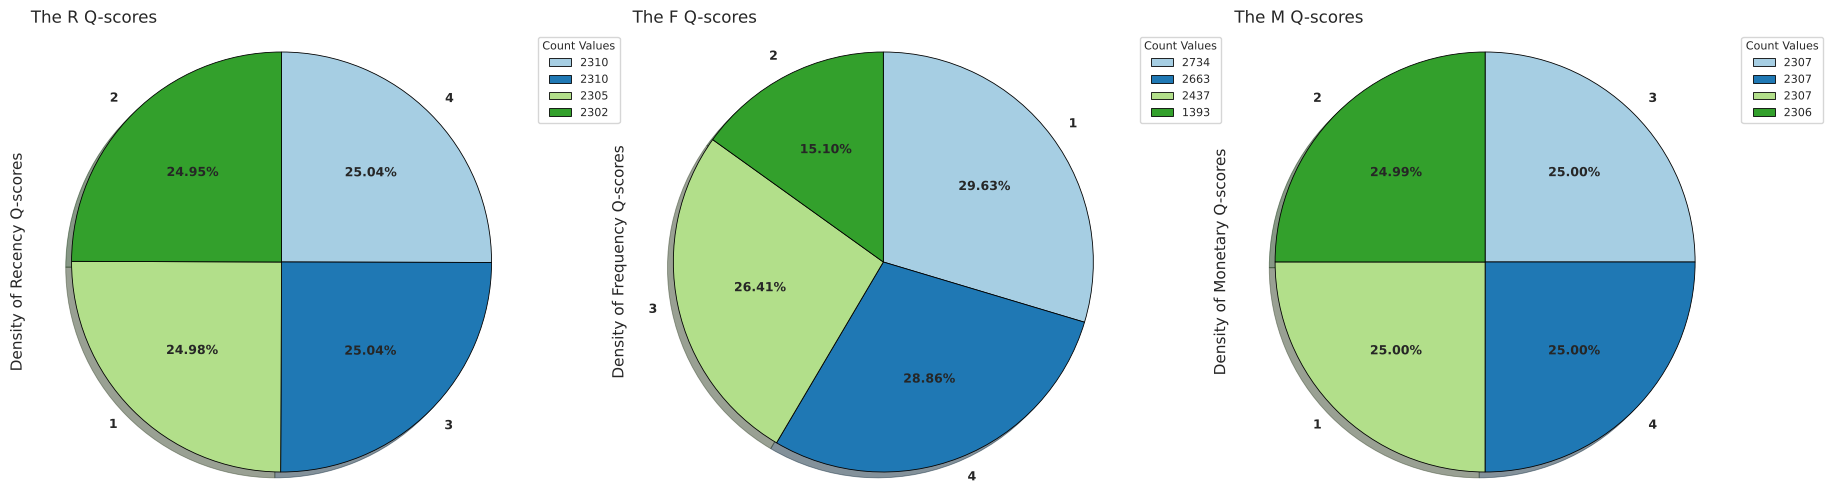

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))      # Figure 5.47
for ax, (c, nm, full) in zip(axes, [('RecencyScore', 'R', 'Recency'), ('FrequencyScore', 'F', 'Frequency'),
                                    ('MonetaryScore', 'M', 'Monetary')]):
    vc = rawRFMdata[c].value_counts()
    plot_pie(vc, f'Density of {full} Q-scores', 'Count Values', title=f'The {nm} Q-scores',
             colors=sns.color_palette('Paired')[:len(vc)], ax=ax)
plt.show()

In [65]:
def RFM_Scoring(customer):          # Figure 5.48
    return str(int(customer['RecencyScore'])) + str(int(customer['FrequencyScore'])) + str(int(customer['MonetaryScore']))

rawRFMdata['CustomerRFMScore'] = rawRFMdata.apply(RFM_Scoring, axis=1)
rawRFMdata.sample(5)

,Recency,Frequency,Monetary,RecencyScore,FrequencyScore,MonetaryScore,CustomerRFMScore
1397,1825,4,800.31,1,3,2,132
2774,46,4,1478.00,4,3,3,433
7674,712,5,17655.40,2,3,4,234
8937,961,1,343.30,2,1,1,211
5004,24,10,6817.37,4,4,4,444


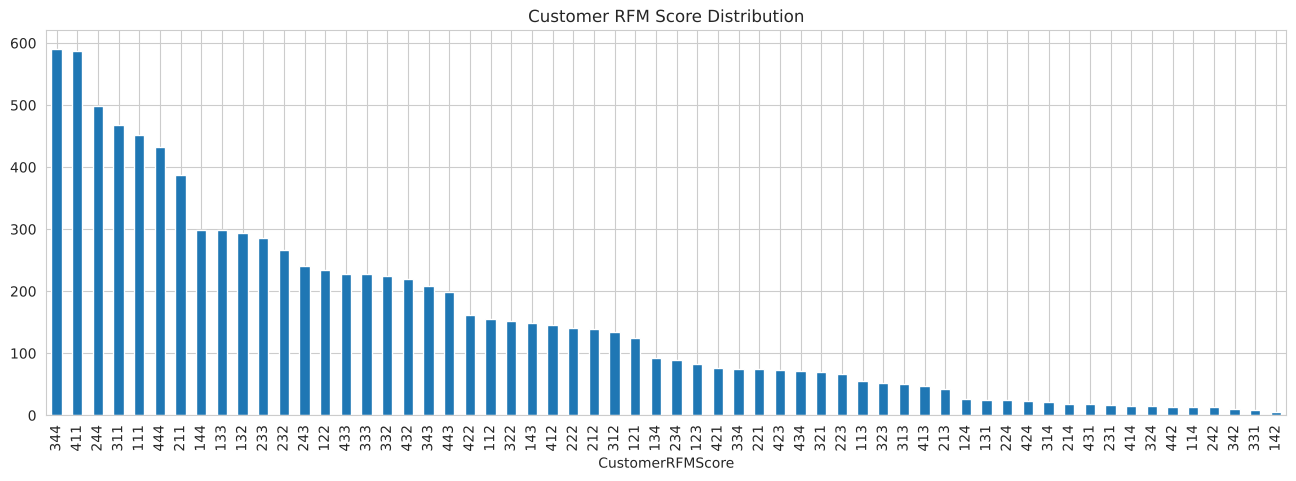

In [66]:
# Figure 5.49: histogram of 3-digit RFM codes (original used plotly)
RFMScoreCounts = rawRFMdata['CustomerRFMScore'].value_counts().reset_index()
RFMScoreCounts.columns = ['CustomerRFMScore', 'counts']
try:
    import plotly.express as px
    figp = px.histogram(RFMScoreCounts, x='CustomerRFMScore', y='counts', title='Customer RFM Score Distribution')
    figp.update_xaxes(type='category', categoryorder='total descending')
    figp.show()
except ImportError:
    RFMScoreCounts.plot.bar(x='CustomerRFMScore', y='counts', figsize=(16, 5), legend=False,
                            title='Customer RFM Score Distribution'); plt.show()

In [67]:
rawRFMdata['RFMLabel'] = rawRFMdata['RecencyScore'] + rawRFMdata['FrequencyScore'] + rawRFMdata['MonetaryScore']
display(rawRFMdata.sample(5))      # Figure 5.50
rawRFMdata.RFMLabel.unique()

,Recency,Frequency,Monetary,RecencyScore,FrequencyScore,MonetaryScore,CustomerRFMScore,RFMLabel
8870,133,3,573.36,4,2,2,422,8
7206,44,1,150.96,4,1,1,411,6
4009,17,8,1087.99,4,4,2,442,10
4178,51,3,2385.54,4,2,3,423,9
1735,1087,4,560.91,2,3,2,232,7


array([ 8,  9, 12,  5,  7,  3, 10, 11,  4,  6])

In [68]:
# Figure 5.51: segment definitions + Categorizer (verbatim)
SegmentTable = pd.DataFrame({
    'CustomerSegment': ['Champion Customer', 'Top Loyal Customer', 'Loyal Customer', 'Top Recent Customer',
                        'Recent Active Customer', 'Top Customer At Risk', 'Attention Needed Customer',
                        'Top Lost Customer', 'Lost Customer'],
    'RFM': ['(2|3|4)-(4)-(4)', '(3)-(1|2|3|4)-(3|4)', '(3)-(1|2|3|4)-(1|2)', '(4)-(1|2|3|4)-(3|4)',
            '(4)-(1|2|3|4)-(1|2)', '(2|3)-(1|2|3|4)-(3|4)', '(2|3)-(1|2|3|4)-(1|2)', '(1)-(1|2|3|4)-(3|4)',
            '(1)-(1|2|3|4)-(1|2)']})
display(SegmentTable)

def Categorizer(rfm):
    if (rfm[0] in ['2', '3', '4']) & (rfm[1] in ['4']) & (rfm[2] in ['4']):
        rfm = 'Champion Customer'
    elif (rfm[0] in ['3']) & (rfm[1] in ['1', '2', '3', '4']) & (rfm[2] in ['3', '4']):
        rfm = 'Top Loyal Customer'
    elif (rfm[0] in ['3']) & (rfm[1] in ['1', '2', '3', '4']) & (rfm[2] in ['1', '2']):
        rfm = 'Loyal Customer'
    elif (rfm[0] in ['4']) & (rfm[1] in ['1', '2', '3', '4']) & (rfm[2] in ['3', '4']):
        rfm = 'Top Recent Customer'
    elif (rfm[0] in ['4']) & (rfm[1] in ['1', '2', '3', '4']) & (rfm[2] in ['1', '2']):
        rfm = 'Recent Active Customer'
    elif (rfm[0] in ['2', '3']) & (rfm[1] in ['1', '2', '3', '4']) & (rfm[2] in ['3', '4']):
        rfm = 'Top Customer At Risk'
    elif (rfm[0] in ['2', '3']) & (rfm[1] in ['1', '2', '3', '4']) & (rfm[2] in ['1', '2']):
        rfm = 'Attention Needed Customer'
    elif (rfm[0] in ['1']) & (rfm[1] in ['1', '2', '3', '4']) & (rfm[2] in ['3', '4']):
        rfm = 'Top Lost Customer'
    elif (rfm[0] in ['1']) & (rfm[1] in ['1', '2', '3', '4']) & (rfm[2] in ['1', '2']):
        rfm = 'Lost Customer'
    return rfm

,CustomerSegment,RFM
0,Champion Customer,(2|3|4)-(4)-(4)
1,Top Loyal Customer,(3)-(1|2|3|4)-(3|4)
2,Loyal Customer,(3)-(1|2|3|4)-(1|2)
3,Top Recent Customer,(4)-(1|2|3|4)-(3|4)
4,Recent Active Customer,(4)-(1|2|3|4)-(1|2)
5,Top Customer At Risk,(2|3)-(1|2|3|4)-(3|4)
6,Attention Needed Customer,(2|3)-(1|2|3|4)-(1|2)
7,Top Lost Customer,(1)-(1|2|3|4)-(3|4)
8,Lost Customer,(1)-(1|2|3|4)-(1|2)


In [69]:
rawRFMdata['CustomerCategory'] = rawRFMdata["CustomerRFMScore"].apply(Categorizer)
rawRFMdata.sample(8)      # Figure 5.52

,Recency,Frequency,Monetary,RecencyScore,FrequencyScore,MonetaryScore,CustomerRFMScore,RFMLabel,CustomerCategory
3595,1252,2,628.26,1,1,2,112,4,Lost Customer
833,1219,6,1150.29,1,3,3,133,7,Top Lost Customer
1809,257,2,188.12,3,1,1,311,5,Loyal Customer
543,398,1,236.78,3,1,1,311,5,Loyal Customer
9220,905,9,2999.62,2,4,4,244,10,Champion Customer
5978,1360,12,5568.83,1,4,4,144,9,Top Lost Customer
938,19,1,240.39,4,1,1,411,6,Recent Active Customer
2243,1183,7,2180.35,1,4,3,143,8,Top Lost Customer


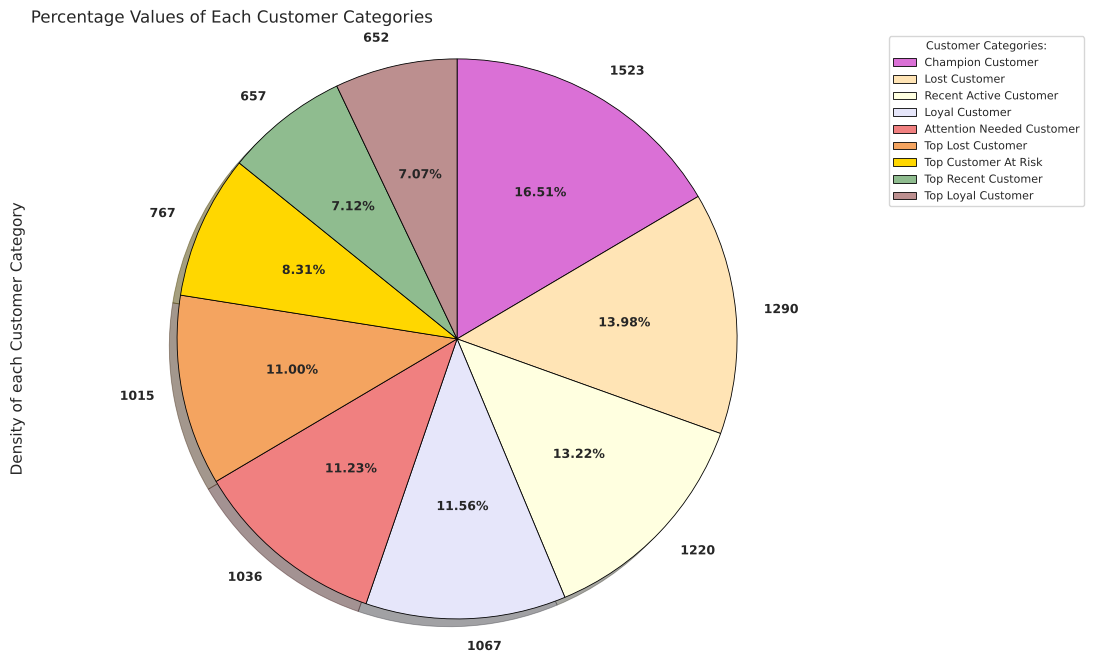

In [70]:
cat_counts = rawRFMdata['CustomerCategory'].value_counts()
plot_pie(cat_counts, 'Density of each Customer Category', 'Customer Categories:',
         title='Percentage Values of Each Customer Categories', labels=cat_counts.values,
         legend_labels=cat_counts.index, figsize=(11, 8))      # Figure 5.53
plt.show()

In my dissertation the categories came out as: Champion 1,730 (18.75%) · Lost 1,462 (15.84%) · Loyal 1,117 (12.11%) · Recent Active 1,046 (11.34%) · Attention Needed 987 (10.70%) · Top Customer At Risk 939 (10.18%) · Top Lost 843 (9.14%) · Top Loyal 638 (6.91%) · Top Recent 465 (5.04%).

## 5.4 Product Segmentation
I split individual product sales (`Order_Type == 'Product'`) into 16 SKU columns, one per product line, each holding the quantity bought.

In my dissertation I assigned SKUs with 16 keyword rules on `Item_Name`. Those rules are made of the partner's brand names, so they can't be published. Here each row's SKU is its product-line code (`Profile_Type`, masked as `P01` … `P16`), which my report describes as the product's brand code. On the synthetic data the two approaches agree for 99.9% of rows. The few differences are the kind of mis-tagged rows I removed in §4.3.3.

In [71]:
ProductData = pd.DataFrame(CleanedData[['idMember', 'Invoice', 'InvoiceDate', 'Item_Name', 'Quantity', 'Order_Type']])
IProductData = (ProductData[(ProductData.Order_Type == 'Product')]).copy()
display(IProductData.sample(3))

SKUProduct = sorted(CleanedData['Profile_Type'].dropna().unique())   # 16 product lines (masked codes)
SKUProduct          # Figure 5.54

,idMember,Invoice,InvoiceDate,Item_Name,Quantity,Order_Type
27586,106404,INV-P006347,2020-02-07 17:21:00,ITEM-0092,2,Product
19736,100585,INV-P030347,2020-07-10 01:24:00,ITEM-0092,1,Product
14575,106401,INV-P034625,2022-08-24 16:38:00,ITEM-0075,1,Product


['P01',
 'P02',
 'P03',
 'P04',
 'P05',
 'P06',
 'P07',
 'P08',
 'P09',
 'P10',
 'P11',
 'P12',
 'P13',
 'P14',
 'P15',
 'P16']

In [72]:
for i in SKUProduct:
    IProductData[i] = None
IProductData.info()          # Figure 5.55

<class 'pandas.DataFrame'>
Index: 53973 entries, 9 to 62765
Data columns (total 22 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   idMember     53973 non-null  int64         
 1   Invoice      53973 non-null  str           
 2   InvoiceDate  53973 non-null  datetime64[us]
 3   Item_Name    53973 non-null  str           
 4   Quantity     53973 non-null  int64         
 5   Order_Type   53973 non-null  str           
 6   P01          0 non-null      object        
 7   P02          0 non-null      object        
 8   P03          0 non-null      object        
 9   P04          0 non-null      object        
 10  P05          0 non-null      object        
 11  P06          0 non-null      object        
 12  P07          0 non-null      object        
 13  P08          0 non-null      object        
 14  P09          0 non-null      object        
 15  P10          0 non-null      object        
 16  P11          0 non-n

In [73]:
def distributeProductData(IProduct):                       # Figure 5.56 (public edition: SKU = product-line code)
    sku = CleanedData.loc[IProduct.index, 'Profile_Type']
    for s in SKUProduct:
        IProduct.loc[sku == s, s] = IProduct.loc[sku == s, 'Quantity']
    return IProduct

IProductData = distributeProductData(IProductData)
IProductData.sample(5)

,idMember,Invoice,InvoiceDate,Item_Name,Quantity,Order_Type,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16
8157,104757,INV-P026115,2017-12-15 14:57:00,ITEM-0017,2,Product,None,None,None,None,None,None,None,None,None,None,2,None,None,None,None,None
23652,101902,INV-P014944,2020-07-28 13:50:00,ITEM-0081,1,Product,None,None,None,None,None,None,1,None,None,None,None,None,None,None,None,None
39203,107377,INV-P008071,2018-12-02 19:31:00,ITEM-0078,1,Product,1,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
49388,102476,INV-P041578,2017-12-09 01:23:00,ITEM-0092,6,Product,None,None,None,None,None,6,None,None,None,None,None,None,None,None,None,None
39125,108577,INV-P019884,2018-10-23 14:41:00,ITEM-0078,1,Product,1,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None


In [74]:
def createINVYearMonthDay(itemDATASET):                    # Figure 5.57
    itemDATASET['Year'] = itemDATASET['InvoiceDate'].apply(lambda d: d.year)
    itemDATASET['Month'] = itemDATASET['InvoiceDate'].apply(lambda d: d.month)
    itemDATASET['Day'] = itemDATASET['InvoiceDate'].apply(lambda d: d.day)
    return itemDATASET

IProductData = createINVYearMonthDay(IProductData)
IProductData[SKUProduct] = IProductData[SKUProduct].apply(pd.to_numeric).fillna(0).astype(int)   # None -> 0 before summing
DisplayIProductData = IProductData.groupby(by=['Year'])[SKUProduct].sum()
if MASK_BUSINESS_FIGURES:           # public edition: % of all units sold 2017-2022, not unit volumes
    DisplayIProductData = (DisplayIProductData / DisplayIProductData.values.sum() * 100).round(2)
DisplayIProductData

,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16
Year,,,,,,,,,,,,,,,,
2017,6.82,0.01,0.02,0.18,0.54,1.21,1.62,0.73,0.16,0.14,1.61,0.14,0.14,0.01,2.05,0.13
2018,11.07,0.01,0.03,0.29,1.19,1.84,2.16,1.24,0.18,0.40,2.09,0.34,0.16,0.02,2.97,0.19
2019,8.23,0.00,0.01,0.24,0.67,1.39,1.79,0.87,0.12,0.19,1.78,0.23,0.21,0.00,2.15,0.12
2020,7.25,0.01,0.02,0.25,0.58,1.40,1.49,0.69,0.08,0.17,1.73,0.22,0.17,0.01,1.81,0.14
2021,6.26,0.01,0.01,0.16,0.51,1.13,1.28,0.79,0.10,0.18,1.34,0.19,0.10,0.01,1.87,0.12
2022,5.94,0.01,0.03,0.15,0.45,0.77,1.27,0.66,0.07,0.09,1.05,0.20,0.07,0.01,1.36,0.12


In [75]:
# thesis: the 13 main product lines (the 3 smallest left out)
ColumnLists = IProductData[SKUProduct].sum().sort_values(ascending=False).index[:13].tolist()
TopDisplayProductDataset = DisplayIProductData[ColumnLists]
TopDisplayProductDataset      # Figure 5.58

,P01,P15,P07,P11,P06,P08,P05,P12,P04,P10,P13,P16,P09
Year,,,,,,,,,,,,,
2017,6.82,2.05,1.62,1.61,1.21,0.73,0.54,0.14,0.18,0.14,0.14,0.13,0.16
2018,11.07,2.97,2.16,2.09,1.84,1.24,1.19,0.34,0.29,0.40,0.16,0.19,0.18
2019,8.23,2.15,1.79,1.78,1.39,0.87,0.67,0.23,0.24,0.19,0.21,0.12,0.12
2020,7.25,1.81,1.49,1.73,1.40,0.69,0.58,0.22,0.25,0.17,0.17,0.14,0.08
2021,6.26,1.87,1.28,1.34,1.13,0.79,0.51,0.19,0.16,0.18,0.10,0.12,0.10
2022,5.94,1.36,1.27,1.05,0.77,0.66,0.45,0.20,0.15,0.09,0.07,0.12,0.07


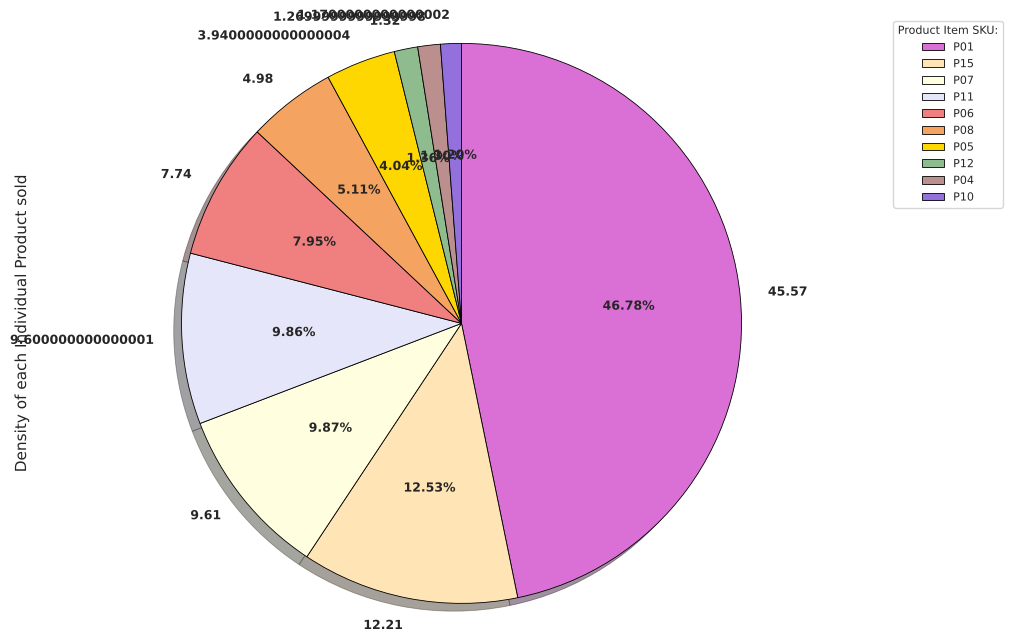

In [76]:
Top10Products = TopDisplayProductDataset.sum().sort_values(ascending=False).head(10)
plot_pie(Top10Products, 'Density of each Individual Product sold', 'Product Item SKU:',
         labels=Top10Products.values, legend_labels=Top10Products.index, figsize=(11, 8))   # Figure 5.59
plt.show()

In my dissertation, one flagship product line held 47.6% of the top-10 product units and the top 3 lines 73.5%. Each of the other seven lines held under 9%.

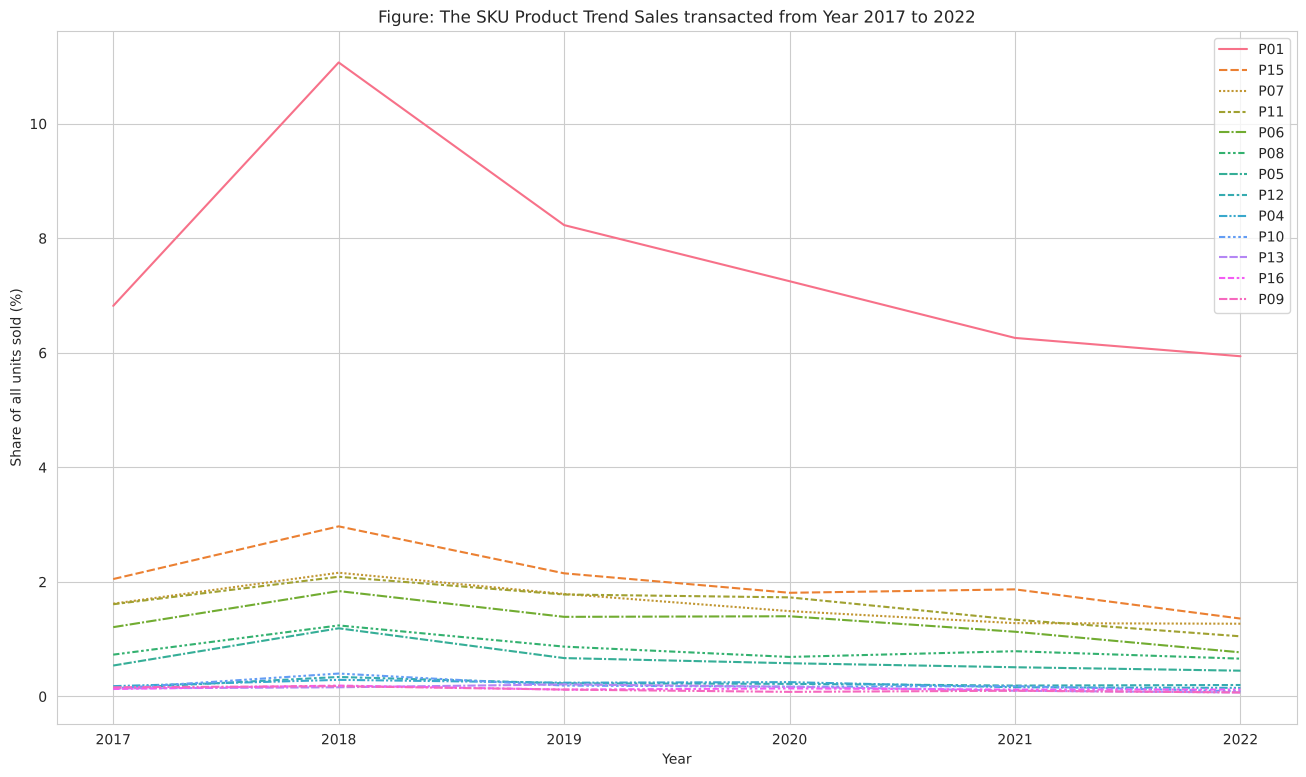

In [77]:
plt.figure(figsize=(16, 9))                                     # Figure 5.60
sns.lineplot(data=TopDisplayProductDataset)
plt.title('Figure: The SKU Product Trend Sales transacted from Year 2017 to 2022')
plt.ylabel('Share of all units sold (%)' if MASK_BUSINESS_FIGURES else 'Total Quantity'); plt.xlabel('Year')
plt.xticks(TopDisplayProductDataset.index)
plt.show()

For bundles, my dissertation split each bundle back into the 16 SKUs with `distributeBundleData()`, a function with 155 if-else rules. It isn't in my report's screenshots, so I couldn't rebuild it. The bundle popularity tables from the report are reproduced below.

In [78]:
BundleInfoData = ProductData[ProductData.Order_Type == 'Bundle']
DisplayBundleData = BundleInfoData.groupby(by=['Item_Name'])['Item_Name'].count()
DisplayBundleData = pd.DataFrame(DisplayBundleData)
DisplayBundleData.columns = ["Total"]
DisplayBundleData = DisplayBundleData.reset_index()
DisplayBundleData.columns = ["BundleName", "TotalBundleSum"]
if MASK_BUSINESS_FIGURES:           # public edition: % of all bundle lines, not counts
    DisplayBundleData["TotalBundleSum"] = (DisplayBundleData.TotalBundleSum / DisplayBundleData.TotalBundleSum.sum() * 100).round(2)
DisplayBundleData           # Figure 5.61 (thesis: 228 bundle packages)

,BundleName,TotalBundleSum
0,BUNDLE-0001,0.17
1,BUNDLE-0002,0.14
2,BUNDLE-0003,0.19
3,BUNDLE-0004,2.86
4,BUNDLE-0006,0.13
...,...,...
69,BUNDLE-0087,0.24
70,BUNDLE-0088,0.26
71,BUNDLE-0089,0.19
72,BUNDLE-0090,0.25


In [79]:
Top10DisplayBundletData = DisplayBundleData.sort_values(by=['TotalBundleSum'], ascending=False).head(10)
Top10DisplayBundletData     # Figure 5.62

,BundleName,TotalBundleSum
38,BUNDLE-0048,21.43
22,BUNDLE-0030,17.78
64,BUNDLE-0080,7.45
37,BUNDLE-0047,7.33
60,BUNDLE-0074,7.20
11,BUNDLE-0013,5.38
36,BUNDLE-0046,4.44
33,BUNDLE-0043,4.38
63,BUNDLE-0079,3.22
3,BUNDLE-0004,2.86


The best-selling bundles in my dissertation were starter packs and multi-packs of the flagship line, plus a triple pack from one of the supplement lines.

## 5.5 Monetary Generated by each State
For the expansion question I looked at two things per state: how many transaction lines it had ("Density") and its total sales (Amount × Quantity).

In [80]:
StateData = CleanedData[['State', 'Amount', 'Quantity']].copy()
StateData['Monetary'] = StateData['Amount'] * StateData['Quantity']
DataSID = StateData.groupby('State')['State'].count().rename('Density').to_frame()
DataSIM = StateData.groupby('State')['Monetary'].sum().round(2).to_frame()
DataStateMonetary = DataSID.merge(DataSIM, on='State')
if MASK_BUSINESS_FIGURES:           # public edition: % share of lines / sales, not RM
    DataStateMonetary = (DataStateMonetary / DataStateMonetary.sum() * 100).round(2)
DataStateMonetary.reset_index()       # Figure 5.63

,State,Density,Monetary
0,Region A,10.98,11.53
1,Region B,2.76,2.40
2,Region C,0.00,0.00
3,Region D,3.02,3.34
4,Region E,0.12,0.11
5,Region F,0.31,0.30
6,Region G,28.64,28.45
7,Region H,3.80,3.46
8,Region I,4.69,4.46
9,Region J,0.65,0.55


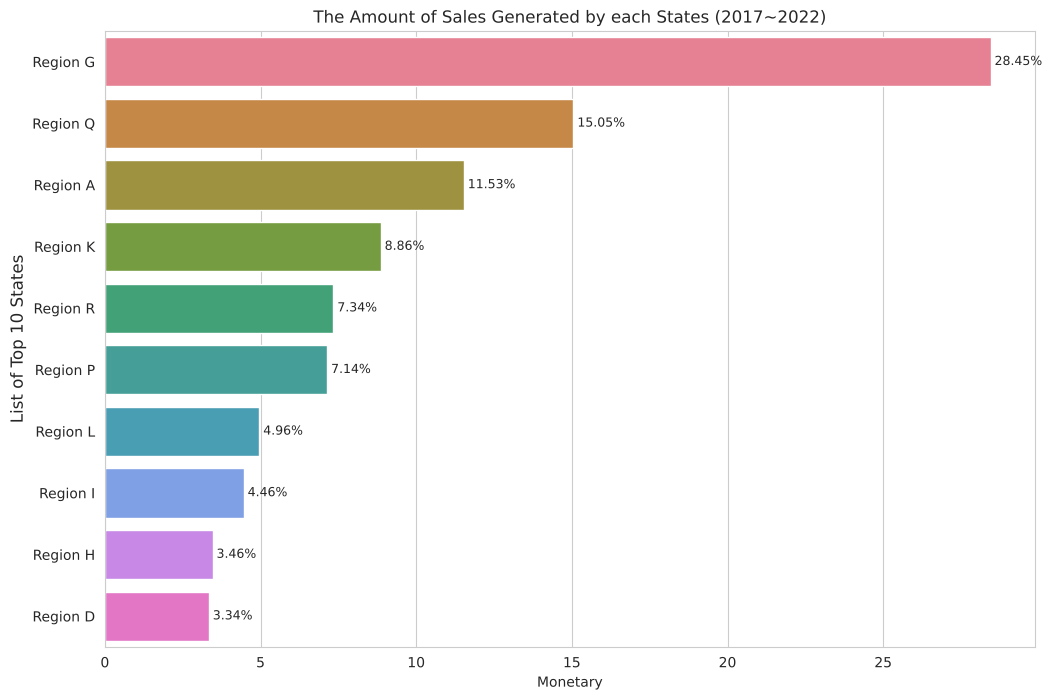

In [81]:
Top10StateMonetary = DataStateMonetary.sort_values('Monetary', ascending=False).head(10).reset_index()
plt.figure(figsize=(12, 8))                                       # Figure 5.64
ax = sns.barplot(data=Top10StateMonetary, x='Monetary', y='State', hue='State', palette='husl', legend=False)
for p, v in zip(ax.patches, Top10StateMonetary['Monetary']):
    ax.text(p.get_width(), p.get_y() + p.get_height() / 2, (f' {v:.2f}%' if MASK_BUSINESS_FIGURES else f' RM {v:.2f}'), va='center', fontsize=9)
ax.set_ylabel('List of Top 10 States', fontsize=12)
ax.set_title('The Amount of Sales Generated by each States (2017~2022)')
plt.show()

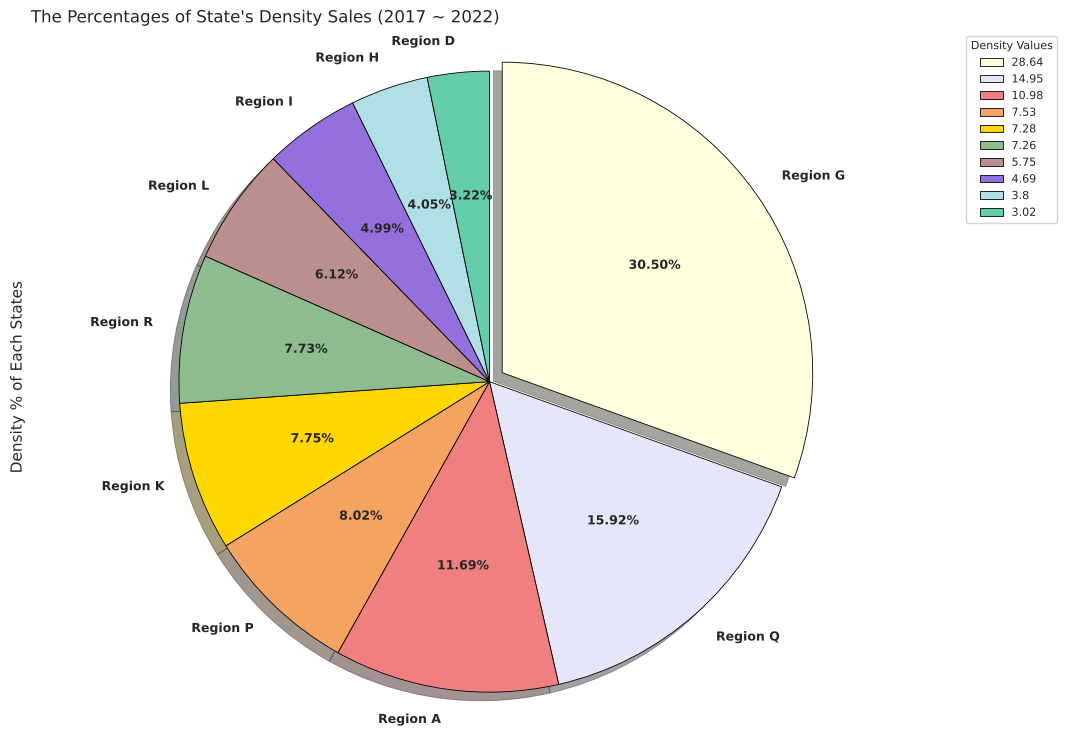

In [82]:
Top10StateDensity = DataStateMonetary.sort_values('Density', ascending=False).head(10)
explode = [0.05] + [0] * (len(Top10StateDensity) - 1)
plot_pie(Top10StateDensity['Density'], 'Density % of Each States', 'Density Values',
         title="The Percentages of State's Density Sales (2017 ~ 2022)", explode=explode,
         colors=PIE_COLORS[2:12], figsize=(12, 9))                # Figure 5.65
plt.show()

Sales were very concentrated. The HQ region and one branch region together made up about 76% of all transaction lines. My recommendation was to expand next into the 3rd, 4th and 5th largest regions by sales.

# FURTHER WORK (after the dissertation)
## 5.6 Customer Lifetime Value (CLTV)

### What CLTV means
RFM tells me what a customer has done. Customer Lifetime Value estimates what they are worth from now on: the profit they are likely to bring over the rest of the relationship.

A simple way to picture it: a café regular who buys a RM 10 coffee three times a week for years is worth far more than a tourist who spends RM 50 once. CLTV puts a single forward-looking number on each customer, so marketing can decide how much it's worth spending to keep them.

The simplest version (Gupta & Lehmann, 2003) is:

$$\text{CLV} = m \times \frac{r}{1 + i - r}$$

where *m* is the yearly margin from a customer, *r* is the retention rate (the chance they're still a customer next year), and *i* is the discount rate (money next year is worth a little less than money today).

With 60% retention and a 10% discount rate, a customer is worth 0.6 / (1 + 0.1 − 0.6) = 1.2 years of margin. At 70% retention that rises to 0.7 / 0.4 = 1.75 years. Small gains in retention add up quickly. Reichheld & Sasser (1990) reported that, in the service businesses they studied, reducing defections by 5% raised profits by 25–85%.

### The models I used
Retail customers don't cancel a contract. They just stop buying, and nobody announces it. Two standard models deal with this situation (Gupta et al., 2006):

1. **BG/NBD** (Fader, Hardie & Lee, 2005a) estimates how many more purchases to expect from each customer, and the probability they're still active. It only needs three numbers per customer: how many repeat purchases they made, when the last one was, and how long ago the first one was. For example, someone who used to buy monthly but has been silent for a year has probably gone. Someone who buys twice a year and was last seen two months ago probably hasn't.
2. **Gamma-Gamma** (Fader & Hardie, 2013; Fader, Hardie & Lee, 2005b) estimates how much each customer is likely to spend per purchase. It pulls customers with only a few purchases towards the average, so one big order isn't over-trusted.

Putting them together: CLTV for the next 12 months = expected purchases × expected spend per purchase × profit margin, discounted month by month.

I implemented both models directly from the published formulas using `scipy`, and tested them on a hold-out period before using them. Because of the camouflage, I show CLTV as an index (average customer = 100) and as shares, not in RM.

### References
* Fader, P. S., & Hardie, B. G. S. (2013). *The Gamma-Gamma model of monetary value* [Technical note]. http://www.brucehardie.com/notes/025/gamma_gamma.pdf
* Fader, P. S., Hardie, B. G. S., & Lee, K. L. (2005a). "Counting your customers" the easy way: An alternative to the Pareto/NBD model. *Marketing Science, 24*(2), 275–284. https://doi.org/10.1287/mksc.1040.0098
* Fader, P. S., Hardie, B. G. S., & Lee, K. L. (2005b). RFM and CLV: Using iso-value curves for customer base analysis. *Journal of Marketing Research, 42*(4), 415–430.
* Gupta, S., Hanssens, D., Hardie, B., Kahn, W., Kumar, V., Lin, N., Ravishanker, N., & Sriram, S. (2006). Modeling customer lifetime value. *Journal of Service Research, 9*(2), 139–155.
* Gupta, S., & Lehmann, D. R. (2003). Customers as assets. *Journal of Interactive Marketing, 17*(1), 9–24.
* Reichheld, F. F., & Sasser, W. E. (1990). Zero defections: Quality comes to services. *Harvard Business Review, 68*(5), 105–111.

In [83]:
# ---------------- CLTV settings (business assumptions: replace with real ones privately) ----------------
CLTV_HORIZON_MONTHS = 12      # how far ahead to value customers
GROSS_MARGIN = 0.30           # ASSUMPTION: share of revenue kept as profit (the real margin is not in the data)
ANNUAL_DISCOUNT = 0.10        # yearly discount rate for future money
HOLDOUT_WEEKS = 26            # last 26 weeks are held back to test the model's predictions
WEEKS_PER_MONTH = 52 / 12

from scipy.optimize import minimize
from scipy.special import gammaln, hyp2f1

def show_money(x):
    # Money is only shown in currency when business figures are not masked.
    return "masked" if MASK_BUSINESS_FIGURES else f"{x:,.2f}"

### 5.6.1 A quick estimate with the simple formula
I grouped customers by calendar year. Retention is the share of customers active in one year who bought again the next year, averaged across years. I skip the last year because it isn't complete.

In [84]:
yr = CleanedData.assign(Year=CleanedData['InvoiceDate'].dt.year,
                        Spend=CleanedData['Amount'] * CleanedData['Quantity'])
active = yr.groupby('Year')['idMember'].apply(set)
years = sorted(active.index)
last_partial = yr.loc[yr.Year == years[-1], 'InvoiceDate'].dt.month.max() < 12   # is the last year partial?
pairs = [(y, y + 1) for y in years[:-1] if (y + 1) in active.index and not (last_partial and y + 1 == years[-1])]
retention_by_year = pd.Series({f"{a}->{b}": len(active[a] & active[b]) / len(active[a]) for a, b in pairs})
r = retention_by_year.mean()
annual_margin = (yr.groupby(['Year', 'idMember'])['Spend'].sum().groupby('Year').mean() * GROSS_MARGIN).mean()
multiplier = r / (1 + ANNUAL_DISCOUNT - r)

display((retention_by_year * 100).round(1).rename('retention %').to_frame())
print(f"Average yearly retention r = {r:.1%}")
print(f"CLV multiplier r/(1+i-r)  = {multiplier:.2f}  -> an average customer is worth about {multiplier:.2f} years of margin")
print(f"Average yearly margin per active customer m = {show_money(annual_margin)} | simple CLV = {show_money(annual_margin * multiplier)}")
for rr in (r, r + 0.05, r + 0.10):
    print(f"  if retention were {rr:.0%}: multiplier {rr / (1 + ANNUAL_DISCOUNT - rr):.2f}")

,retention %
2017->2018,60.1
2018->2019,48.5
2019->2020,45.4
2020->2021,42.9


Average yearly retention r = 49.2%
CLV multiplier r/(1+i-r)  = 0.81  -> an average customer is worth about 0.81 years of margin
Average yearly margin per active customer m = masked | simple CLV = masked
  if retention were 49%: multiplier 0.81
  if retention were 54%: multiplier 0.97
  if retention were 59%: multiplier 1.17


### 5.6.2 Preparing the data for BG/NBD
Here a purchase is one customer-day, so several invoices on the same day count once. This is different from the Frequency I used for RFM (invoice lines), because BG/NBD needs separate purchase occasions.

| Column | Meaning (in weeks) |
|---|---|
| `x` | number of repeat purchases (all purchases − 1) |
| `t_x` | time from first to last purchase |
| `T` | time from first purchase to the end of the data |
| `m_x` | average spend per repeat purchase (for Gamma-Gamma) |

In [85]:
def customer_summary(txn, end_date):
    d = txn.assign(Day=txn['InvoiceDate'].dt.normalize(), Spend=txn['Amount'] * txn['Quantity'])
    d = d[d.Day <= end_date]
    occ = d.groupby(['idMember', 'Day'], as_index=False)['Spend'].sum().sort_values(['idMember', 'Day'])
    g = occ.groupby('idMember')
    first, last = g.Day.min(), g.Day.max()
    summ = pd.DataFrame({'x': g.size() - 1,
                         't_x': (last - first).dt.days / 7,
                         'T': (end_date - first).dt.days / 7})
    occ['is_repeat'] = g.cumcount() > 0
    summ['m_x'] = occ[occ.is_repeat].groupby('idMember')['Spend'].mean()
    return summ

END_DATE = CleanedData['InvoiceDate'].dt.normalize().max()
CustSummary = customer_summary(CleanedData, END_DATE)
print(f"{len(CustSummary):,} customers | one-time buyers (x = 0): {(CustSummary.x == 0).mean():.1%}")
CustSummary[['x', 't_x', 'T']].describe().round(2)

9,227 customers | one-time buyers (x = 0): 23.7%


,x,t_x,T
count,9227.00,9227.00,9227.00
mean,3.26,96.35,192.14
std,5.91,89.65,83.15
min,0.00,0.00,0.14
25%,1.00,0.14,139.71
50%,2.00,78.86,227.57
75%,4.00,179.93,260.00
max,143.00,267.57,276.71


### 5.6.3 Fitting BG/NBD and Gamma-Gamma
I fit the parameters by maximum likelihood, using the log-likelihoods from Fader, Hardie & Lee (2005a) and Fader & Hardie (2013).

In [86]:
# ---------- BG/NBD ----------
def bgnbd_negll(log_params, x, t_x, T, penalty=1e-4):
    r_, alpha, a, b = np.exp(log_params)
    A1 = gammaln(r_ + x) - gammaln(r_) + r_ * np.log(alpha)
    A2 = gammaln(a + b) + gammaln(b + x) - gammaln(b) - gammaln(a + b + x)
    A3 = -(r_ + x) * np.log(alpha + T)
    with np.errstate(divide="ignore", invalid="ignore"):
        A4 = np.where(x > 0, np.log(a) - np.log(np.maximum(b + x - 1, 1e-12)) - (r_ + x) * np.log(alpha + t_x), -np.inf)
    ll = A1 + A2 + np.logaddexp(A3, A4)
    return -ll.sum() + penalty * np.sum(np.exp(log_params) ** 2)

def fit_bgnbd(summ):
    x, t_x, T = (summ[c].to_numpy(float) for c in ('x', 't_x', 'T'))
    res = minimize(bgnbd_negll, x0=np.log([0.5, 5.0, 0.5, 2.0]), args=(x, t_x, T), method="Nelder-Mead",
                   options={"maxiter": 5000, "xatol": 1e-6, "fatol": 1e-6})
    return dict(zip(["r", "alpha", "a", "b"], np.exp(res.x))), res

def bgnbd_p_alive(params, x, t_x, T):
    r_, alpha, a, b = (params[k] for k in ("r", "alpha", "a", "b"))
    ratio = np.where(x > 0, (a / np.maximum(b + x - 1, 1e-12)) * ((alpha + T) / (alpha + t_x)) ** (r_ + x), 0.0)
    return 1.0 / (1.0 + ratio)

def bgnbd_expected(params, t, x, t_x, T):
    # expected number of purchases in the next t weeks for each customer
    r_, alpha, a, b = (params[k] for k in ("r", "alpha", "a", "b"))
    z = t / (alpha + T + t)
    hyp = hyp2f1(r_ + x, b + x, a + b + x - 1, z)
    num = (a + b + x - 1) / (a - 1) * (1 - ((alpha + T) / (alpha + T + t)) ** (r_ + x) * hyp)
    return np.nan_to_num(num * bgnbd_p_alive(params, x, t_x, T), nan=0.0, posinf=0.0)

# ---------- Gamma-Gamma ----------
def gg_negll(log_params, x, m):
    p, q, v = np.exp(log_params)
    ll = (gammaln(p * x + q) - gammaln(p * x) - gammaln(q) + q * np.log(v)
          + (p * x - 1) * np.log(m) + p * x * np.log(x) - (p * x + q) * np.log(x * m + v))
    return -ll.sum()

def fit_gamma_gamma(summ):
    rep = summ[(summ.x > 0) & (summ.m_x > 0)]
    x, m = rep.x.to_numpy(float), rep.m_x.to_numpy(float)
    res = minimize(gg_negll, x0=np.log([2.0, 3.0, m.mean()]), args=(x, m), method="Nelder-Mead",
                   options={"maxiter": 5000, "xatol": 1e-6, "fatol": 1e-6})
    return dict(zip(["p", "q", "v"], np.exp(res.x))), res

def gg_expected_spend(params, x, m):
    p, q, v = (params[k] for k in ("p", "q", "v"))
    pop_mean = p * v / (q - 1)                                   # for customers with no repeat purchases
    with np.errstate(invalid="ignore"):
        cond = p * (v + x * np.nan_to_num(m)) / (p * x + q - 1)
    return np.where(x > 0, cond, pop_mean)

#### First, a test: can the model predict purchases it hasn't seen?
I fit the model on everything except the last `HOLDOUT_WEEKS`, ask it to predict each customer's purchases in those weeks, and compare with what actually happened.

Calibration fit converged: True
Hold-out purchases  actual: 2,538 | predicted: 2,396 (-5.6%)
Customer-level correlation (actual vs predicted): 0.36


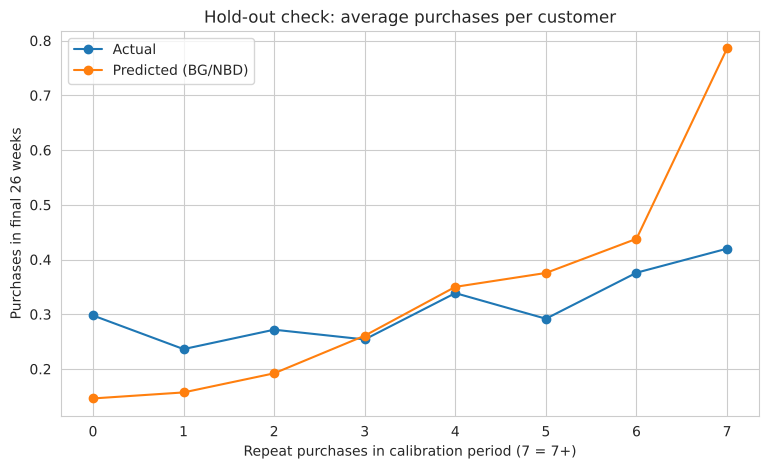

In [87]:
CAL_END = END_DATE - pd.Timedelta(weeks=HOLDOUT_WEEKS)
cal = customer_summary(CleanedData, CAL_END)
hold = (CleanedData[CleanedData.InvoiceDate.dt.normalize() > CAL_END]
        .assign(Day=lambda d: d.InvoiceDate.dt.normalize()).groupby('idMember')['Day'].nunique())
cal['actual_holdout'] = hold.reindex(cal.index).fillna(0)

cal_params, cal_res = fit_bgnbd(cal)
cal['pred_holdout'] = bgnbd_expected(cal_params, HOLDOUT_WEEKS, cal['x'].values, cal['t_x'].values, cal['T'].values)

print("Calibration fit converged:", cal_res.success)
print(f"Hold-out purchases  actual: {cal.actual_holdout.sum():,.0f} | predicted: {cal.pred_holdout.sum():,.0f} "
      f"({cal.pred_holdout.sum() / max(cal.actual_holdout.sum(), 1) - 1:+.1%})")
print(f"Customer-level correlation (actual vs predicted): {cal[['actual_holdout', 'pred_holdout']].corr().iloc[0, 1]:.2f}")

bins = cal.assign(freq_bin=cal['x'].clip(upper=7)).groupby('freq_bin')[['actual_holdout', 'pred_holdout']].mean()
ax = bins.plot(marker='o', figsize=(9, 5), title='Hold-out check: average purchases per customer')
ax.set_xlabel('Repeat purchases in calibration period (7 = 7+)'); ax.set_ylabel(f'Purchases in final {HOLDOUT_WEEKS} weeks')
ax.legend(['Actual', 'Predicted (BG/NBD)']); plt.show()

In [88]:
# Final models on the full history
BG_PARAMS, bg_res = fit_bgnbd(CustSummary)
GG_PARAMS, gg_res = fit_gamma_gamma(CustSummary)
print("BG/NBD :", {k: round(v, 4) for k, v in BG_PARAMS.items()}, "| converged:", bg_res.success)
print("Gamma-Gamma p, q:", round(GG_PARAMS['p'], 3), round(GG_PARAMS['q'], 3),
      "| v:", show_money(GG_PARAMS['v']), "| converged:", gg_res.success)
rep = CustSummary[CustSummary.x > 0]
print(f"Gamma-Gamma assumes spend per purchase is unrelated to how often people buy. "
      f"corr(x, m_x) = {rep[['x', 'm_x']].corr().iloc[0, 1]:.2f} (close to 0 is good)")

BG/NBD : {'r': np.float64(0.5188), 'alpha': np.float64(13.3319), 'a': np.float64(2.8487), 'b': np.float64(20.0715)} | converged: True
Gamma-Gamma p, q: 2.365 2.87 | v: masked | converged: True
Gamma-Gamma assumes spend per purchase is unrelated to how often people buy. corr(x, m_x) = 0.01 (close to 0 is good)


### 5.6.4 CLTV for each customer (next 12 months)
For each of the next 12 months, I multiply expected purchases that month by expected spend and the margin, discount it back to today, and add the months up.

In [89]:
x, t_x, T = (CustSummary[c].to_numpy(float) for c in ('x', 't_x', 'T'))
monthly_disc = (1 + ANNUAL_DISCOUNT) ** (1 / 12) - 1
exp_spend = gg_expected_spend(GG_PARAMS, x, CustSummary.m_x.to_numpy(float))
cltv, prev = np.zeros(len(x)), np.zeros(len(x))
for k in range(1, CLTV_HORIZON_MONTHS + 1):
    cum = bgnbd_expected(BG_PARAMS, k * WEEKS_PER_MONTH, x, t_x, T)
    cltv += (cum - prev) * exp_spend * GROSS_MARGIN / (1 + monthly_disc) ** k
    prev = cum

CLTVdata = pd.DataFrame({
    'idMember': CustSummary.index,                                  # pseudonymous IDs
    'P_alive': bgnbd_p_alive(BG_PARAMS, x, t_x, T).round(3),
    'ExpPurchases12m': prev.round(2),
    'ExpSpendPerPurchase': exp_spend,
    'CLTV': cltv,
})
CLTVdata['CLTV_index'] = (CLTVdata.CLTV / CLTVdata.CLTV.mean() * 100).round(1)   # average customer = 100
CLTVdata['CLTV_tier'] = pd.qcut(CLTVdata.CLTV.rank(method='first'), 4, labels=['Low', 'Medium', 'High', 'Top'])

# summary by tier rather than a list of individual customers
display(CLTVdata.groupby('CLTV_tier', observed=True)
        .agg(Customers=('idMember', 'size'), Mean_P_alive=('P_alive', 'mean'),
             Mean_ExpPurchases12m=('ExpPurchases12m', 'mean'), Mean_CLTV_index=('CLTV_index', 'mean')).round(2))
print("Total 12-month CLTV of the customer base:", show_money(CLTVdata.CLTV.sum()))

,Customers,Mean_P_alive,Mean_ExpPurchases12m,Mean_CLTV_index
CLTV_tier,,,,
Low,2307,0.33,0.06,10.42
Medium,2307,0.74,0.25,34.42
High,2306,0.76,0.50,74.97
Top,2307,0.80,1.13,280.17


Total 12-month CLTV of the customer base: masked


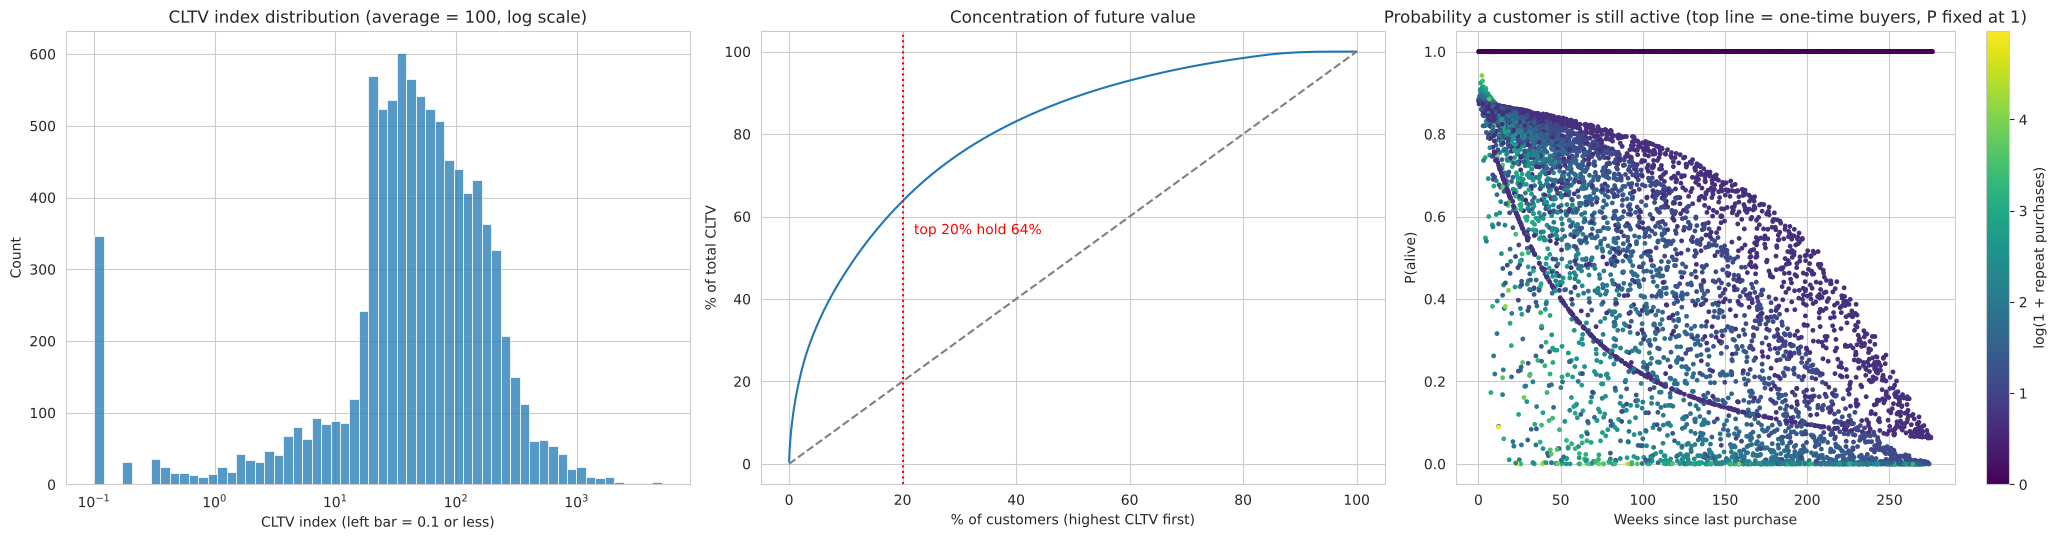

In [90]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
# (a) CLTV distribution (index, log scale)
sns.histplot(CLTVdata.CLTV_index.clip(lower=0.1), bins=60, log_scale=True, ax=axes[0])
axes[0].set_title('CLTV index distribution (average = 100, log scale)'); axes[0].set_xlabel('CLTV index (left bar = 0.1 or less)')
# (b) Pareto curve: share of total CLTV held by the top x% of customers
srt = np.sort(CLTVdata.CLTV.to_numpy())[::-1]
cum_share = np.cumsum(srt) / srt.sum()
pct = np.arange(1, len(srt) + 1) / len(srt)
axes[1].plot(pct * 100, cum_share * 100); axes[1].plot([0, 100], [0, 100], '--', color='grey')
top20 = cum_share[int(0.2 * len(srt)) - 1]
axes[1].axvline(20, color='red', ls=':'); axes[1].text(22, top20 * 100 - 8, f'top 20% hold {top20:.0%}', color='red')
axes[1].set_title('Concentration of future value'); axes[1].set_xlabel('% of customers (highest CLTV first)')
axes[1].set_ylabel('% of total CLTV')
# (c) probability alive vs weeks since last purchase
since_last = CustSummary['T'] - CustSummary['t_x']
sc = axes[2].scatter(since_last, CLTVdata.P_alive, c=np.log1p(CustSummary.x), s=6, cmap='viridis')
axes[2].set_title('Probability a customer is still active (top line = one-time buyers, P fixed at 1)')
axes[2].set_xlabel('Weeks since last purchase')
axes[2].set_ylabel('P(alive)'); plt.colorbar(sc, ax=axes[2], label='log(1 + repeat purchases)')
plt.tight_layout(); plt.show()

### 5.6.5 CLTV by segment
Here I connect future value back to the two segmentations from my dissertation: the K-Means clusters (k = 6, §5.1) and the quantile-score categories (§5.3).

,Customers,Mean_CLTV_index,Mean_P_alive,% of customers,% of future value,value ratio
ClusterK6,,,,,,
6,4277,124.02,0.84,46.4,57.5,1.24
5,737,302.45,0.46,8.0,24.2,3.02
2,2043,44.05,0.55,22.1,9.8,0.44
4,87,474.19,0.27,0.9,4.5,5.00
1,2073,15.08,0.48,22.5,3.4,0.15
3,10,684.82,0.06,0.1,0.7,7.00


,Customers,Mean_CLTV_index,Mean_P_alive,% of customers,% of future value,value ratio
CustomerCategory,,,,,,
Champion Customer,1523,264.03,0.52,16.5,43.6,2.64
Recent Active Customer,1220,111.40,0.90,13.2,14.7,1.11
Top Recent Customer,657,163.97,0.86,7.1,11.7,1.65
Top Loyal Customer,652,124.25,0.75,7.1,8.8,1.24
Loyal Customer,1067,72.96,0.86,11.6,8.4,0.72
Top Customer At Risk,767,57.57,0.50,8.3,4.8,0.58
Attention Needed Customer,1036,36.69,0.73,11.2,4.1,0.37
Lost Customer,1290,16.84,0.64,14.0,2.4,0.17
Top Lost Customer,1015,13.97,0.24,11.0,1.5,0.14


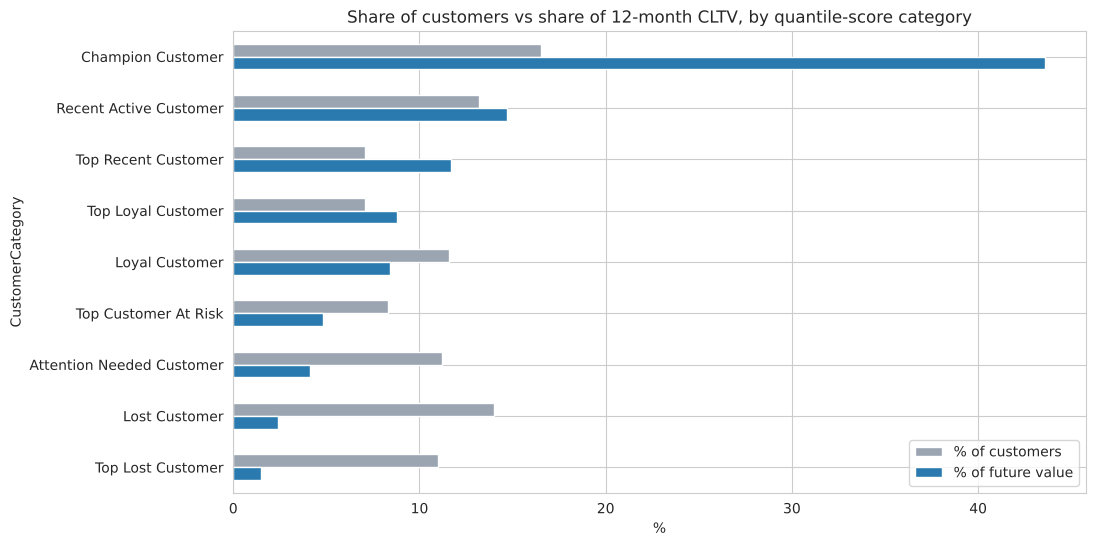

In [91]:
SegCLTV = (CLTVdata.merge(LabelledRFMdata[['idMember', COL_DBI]], on='idMember', how='left')
           .merge(RFMdata[['idMember']].join(rawRFMdata['CustomerCategory']), on='idMember', how='left'))

def segment_table(df, col):
    t = df.groupby(col).agg(Customers=('idMember', 'size'), CLTV_sum=('CLTV', 'sum'),
                            Mean_CLTV_index=('CLTV_index', 'mean'), Mean_P_alive=('P_alive', 'mean'))
    t['% of customers'] = (t.Customers / t.Customers.sum() * 100).round(1)
    t['% of future value'] = (t.CLTV_sum / t.CLTV_sum.sum() * 100).round(1)
    t['value ratio'] = (t['% of future value'] / t['% of customers']).round(2)    # >1 = worth more than its size
    return t.drop(columns='CLTV_sum').round(2).sort_values('% of future value', ascending=False)

CLTV_by_cluster = segment_table(SegCLTV, COL_DBI)
CLTV_by_category = segment_table(SegCLTV, 'CustomerCategory')
display(CLTV_by_cluster); display(CLTV_by_category)

ax = CLTV_by_category[['% of customers', '% of future value']].plot.barh(figsize=(11, 6), color=['#9aa5b1', '#2a7ab0'])
ax.invert_yaxis(); ax.set_xlabel('%'); ax.set_title('Share of customers vs share of 12-month CLTV, by quantile-score category')
plt.show()

### 5.6.6 Turning CLTV into actions
I cross each customer's CLTV tier with their probability of still being active, so every group gets a clear next step:

| | Probably still active (P ≥ 0.5) | Probably drifting away (P < 0.5) |
|---|---|---|
| **Top / High CLTV** | Protect: VIP perks, early access, personal follow-up | Rescue now: a win-back call or offer, since there's a lot at stake |
| **Medium / Low CLTV** | Grow: bundles and cross-selling to raise frequency | Low-cost reactivation: automated reminders only |

Two things to keep in mind:
* A customer can still have a high CLTV with P(alive) under 0.5, if they used to buy very often and spend a lot.
* One-time buyers get their own group. BG/NBD assumes people can only drop out after a repeat purchase, so anyone who bought once always gets P(alive) = 1 (the flat line at the top of the P(alive) chart above). That doesn't really mean they're active, so I give them their own action: a second-purchase programme.

In [92]:
one_time = SegCLTV.idMember.map(CustSummary.x) == 0
SegCLTV['Activity'] = np.where(one_time, 'One-time buyer', np.where(SegCLTV.P_alive >= 0.5, 'Active (P≥0.5)', 'Drifting (P<0.5)'))
SegCLTV['ValueGroup'] = np.where(one_time, 'Any CLTV',
                                 np.where(SegCLTV.CLTV_tier.isin(['Top', 'High']), 'Top/High CLTV', 'Medium/Low CLTV'))
ACTIONS = {('Any CLTV', 'One-time buyer'): 'Second-purchase programme',('Top/High CLTV', 'Active (P≥0.5)'): 'Protect', ('Top/High CLTV', 'Drifting (P<0.5)'): 'Rescue now',
           ('Medium/Low CLTV', 'Active (P≥0.5)'): 'Grow', ('Medium/Low CLTV', 'Drifting (P<0.5)'): 'Low-cost reactivation'}
ActionMatrix = (SegCLTV.groupby(['ValueGroup', 'Activity'])
                .agg(Customers=('idMember', 'size'), CLTV_sum=('CLTV', 'sum')).reset_index())
ActionMatrix['Action'] = [ACTIONS[(v, a)] for v, a in zip(ActionMatrix.ValueGroup, ActionMatrix.Activity)]
ActionMatrix['% of customers'] = (ActionMatrix.Customers / ActionMatrix.Customers.sum() * 100).round(1)
ActionMatrix['% of future value'] = (ActionMatrix.CLTV_sum / ActionMatrix.CLTV_sum.sum() * 100).round(1)
ActionMatrix.drop(columns='CLTV_sum')

,ValueGroup,Activity,Customers,Action,% of customers,% of future value
0,Any CLTV,One-time buyer,2185,Second-purchase programme,23.7,18.0
1,Medium/Low CLTV,Active (P≥0.5),1280,Grow,13.9,4.8
2,Medium/Low CLTV,Drifting (P<0.5),2140,Low-cost reactivation,23.2,2.9
3,Top/High CLTV,Active (P≥0.5),3066,Protect,33.2,64.6
4,Top/High CLTV,Drifting (P<0.5),556,Rescue now,6.0,9.6


## 5.7 Business Findings & Outcomes
### A. What my dissertation found (real data, masked here)
1. **Six behaviour-based segments (K-Means, k = 6):** Recent Active 45.6%, Lost 24.2%, Attention Needed 21.0%, Loyal 8.0%, Top Loyal 1.2% and Champion 0.04%.
2. **Churn was the biggest issue.** About 45% of customers (Lost plus Attention Needed) hadn't bought anything for more than 1.5 years.
3. **Value was extremely concentrated.** Four Champion customers (0.04%) spent far more than anyone else, and with k = 13 the very top spenders formed a tiny cluster of their own.
4. **Customers who bought more often spent more.** Frequency and Monetary were positively correlated in most clusters (r ≈ 0.27 – 0.70), so getting people to come back more often directly lifts revenue.
5. **A simple rule-based approach works too.** Quantile RFM scoring gave nine balanced segments (the largest were Champion at 18.75% and Lost at 15.84%), which marketing staff can use without any machine learning.
6. **Clustering was more stable with extra scaling.** Standard plus MinMax scaling gave best-k values (10 and 2) that changed less between runs.
7. **The business depended on one product line.** One flagship line held 47.6% of top-10 product units and the top 3 lines 73.5%. The best-selling bundles were starter packs and multi-packs of that same line.
8. **Sales were concentrated in two regions.** The HQ region and one branch region made up about 76% of all transaction lines, so I recommended expanding into the 3rd to 5th largest regions.
9. **The data needed better upkeep.** There were 435 hidden duplicate rows from product mis-tagging, 29% missing e-mails, and inconsistent State labels. Most of this could be fixed where the data is entered.

### B. What this run shows
The next cell works out the main findings from whatever data the notebook is running on, as percentages and ratios only. On the synthetic data they only show the method; they are not real results.

In [93]:
def pct(v):
    return f"{v:.1%}"

F = []
srt = np.sort(CLTVdata.CLTV.to_numpy())[::-1]
top20_share = srt[: int(0.2 * len(srt))].sum() / srt.sum()
hist_sorted = np.sort(RFMdata.Monetary.to_numpy())[::-1]
top20_hist = hist_sorted[: int(0.2 * len(hist_sorted))].sum() / hist_sorted.sum()
F.append(f"Value concentration: the top 20% of customers hold {pct(top20_share)} of next-12-month CLTV "
         f"(and generated {pct(top20_hist)} of past spend).")
F.append(f"One-time buyers: {pct((CustSummary.x == 0).mean())} of customers never made a second purchase. "
         f"Converting them into repeat buyers is a major growth opportunity.")
repeaters = CLTVdata[CLTVdata.idMember.map(CustSummary.x) > 0]          # P(alive) is only informative for repeat buyers
F.append(f"Likely churned: among repeat buyers, {pct((repeaters.P_alive < 0.3).mean())} have P(alive) < 0.3, "
         f"and {pct((repeaters.P_alive >= 0.7).mean())} are very likely still active (P ≥ 0.7).")
rescue = ActionMatrix.set_index('Action')
F.append(f"Rescue-now group (high CLTV but drifting): {pct(rescue.loc['Rescue now', 'Customers'] / ActionMatrix.Customers.sum()) if 'Rescue now' in rescue.index else '0%'} "
         f"of customers, carrying {pct(rescue.loc['Rescue now', 'CLTV_sum'] / ActionMatrix.CLTV_sum.sum()) if 'Rescue now' in rescue.index else '0%'} of future value.")
best_cat = CLTV_by_category.index[0]
F.append(f"Most valuable quantile segment: '{best_cat}' holds {CLTV_by_category.iloc[0]['% of future value']}% of future value "
         f"from {CLTV_by_category.iloc[0]['% of customers']}% of customers (value ratio {CLTV_by_category.iloc[0]['value ratio']}).")
worst = CLTV_by_category.sort_values('value ratio').iloc[0]
F.append(f"Least valuable per head: '{CLTV_by_category.sort_values('value ratio').index[0]}' "
         f"({worst['% of customers']}% of customers, {worst['% of future value']}% of value). Keep spend on this group low-cost.")
F.append(f"Retention economics: average yearly retention is {pct(r)}, so a customer is worth about {multiplier:.2f} years of margin. "
         f"+5 points of retention would raise that to {(r + .05) / (1 + ANNUAL_DISCOUNT - r - .05):.2f} years "
         f"({(r + .05) / (1 + ANNUAL_DISCOUNT - r - .05) / multiplier - 1:+.0%}).")
fm = RFMdata[['Frequency', 'Monetary']].corr().iloc[0, 1]
F.append(f"Frequency-Monetary correlation across all customers: r = {fm:.2f}.")
units = IProductData[SKUProduct].sum().sort_values(ascending=False)
F.append(f"Product concentration: the top product line is {pct(units.iloc[0] / units.sum())} of units; "
         f"the top 3 lines are {pct(units.iloc[:3].sum() / units.sum())}.")
dens = DataStateMonetary['Density'].drop('Unknown', errors='ignore').sort_values(ascending=False)
F.append(f"Regional concentration: the top 2 regions account for {pct(dens.iloc[:2].sum() / dens.sum())} of transaction lines.")
F.append(f"Model check: BG/NBD predicted {cal.pred_holdout.sum() / max(cal.actual_holdout.sum(), 1):.0%} of actual "
         f"hold-out purchases (customer-level correlation {cal[['actual_holdout', 'pred_holdout']].corr().iloc[0, 1]:.2f}).")

print("DATA:", "SYNTHETIC stand-in: findings illustrate the method only\n" if IS_SYNTHETIC else "original export\n")
for i, f in enumerate(F, 1):
    print(f"{i:>2}. {f}")

DATA: SYNTHETIC stand-in: findings illustrate the method only

 1. Value concentration: the top 20% of customers hold 63.7% of next-12-month CLTV (and generated 68.8% of past spend).
 2. One-time buyers: 23.7% of customers never made a second purchase. Converting them into repeat buyers is a major growth opportunity.
 3. Likely churned: among repeat buyers, 27.8% have P(alive) < 0.3, and 48.1% are very likely still active (P ≥ 0.7).
 4. Rescue-now group (high CLTV but drifting): 6.0% of customers, carrying 9.6% of future value.
 5. Most valuable quantile segment: 'Champion Customer' holds 43.6% of future value from 16.5% of customers (value ratio 2.64).
 6. Least valuable per head: 'Top Lost Customer' (11.0% of customers, 1.5% of value). Keep spend on this group low-cost.
 7. Retention economics: average yearly retention is 49.2%, so a customer is worth about 0.81 years of margin. +5 points of retention would raise that to 0.97 years (+20%).
 8. Frequency-Monetary correlation across al

### C. What I'd recommend the business does
| # | Action | Based on | Why |
|---|---|---|---|
| 1 | Market to each segment differently instead of running mass campaigns: VIP care for Champion and Top Loyal, reactivation for Attention Needed, low-cost win-back for Lost | K-Means and quantile segments (§5.1, §5.3) | better response rates and a lower cost per sale |
| 2 | Set each customer's retention budget from their CLTV: spend more to keep high-value customers, little on low-value ones | CLTV tiers (§5.6.4) | marketing money follows future value |
| 3 | Keep a "Rescue now" list of high-value customers who are drifting away, and contact them before they're lost | action matrix (§5.6.6) | protects the largest share of future revenue |
| 4 | Run a second-purchase programme for one-time buyers (a follow-up offer, or a refill reminder after the usual repurchase gap) | share of one-time buyers (§5.6.2) | turns a big group into repeat buyers |
| 5 | Offer things that bring people back more often, such as subscriptions and refill bundles | Frequency–Monetary correlation (§5.1) | more visits mean more revenue |
| 6 | Reduce dependence on the flagship line by bundling it with other lines | product concentration (§5.4) | less risk if the flagship slows down |
| 7 | Expand into the 3rd to 5th largest regions | regional analysis (§5.5) | growth outside the two saturated regions |
| 8 | Fix product tagging, standardise State values, and capture e-mail and consent when data is entered | data cleaning (§4.3) | cleaner data, so better models and campaigns |
| 9 | Track retention, the share of active customers, total CLTV and the size of the Rescue-now list every month | §5.6 | shows whether the actions are working |

### Limitations of the CLTV work
* `GROSS_MARGIN` is my assumption, because the real margin isn't in the data. CLTV scales directly with it, so the rankings and shares are reliable even if the absolute level isn't.
* BG/NBD assumes each customer buys at a steady rate until they stop, with no seasonality or campaigns. The hold-out test above shows how well that holds here.
* Gamma-Gamma assumes spend per purchase doesn't depend on how often someone buys. I checked this with the correlation between `x` and `m_x` above.
* One-time buyers always get P(alive) = 1 in BG/NBD, so their CLTV is probably too high. I treat it as an upper bound.
* The camouflage moves each customer's dates by up to ±30 days, which also moves the end of the data, so P(alive) and the recency-based values are approximate. For exact intervals in a private run, use `DATE_SHIFT_MODE = "global"`.

## Checking this run against my dissertation
A quick side-by-side of the key numbers. On the synthetic data they won't match, which is expected.

In [94]:
check = pd.DataFrame([
    ("Raw rows", 62766, len(TxnRaw)),
    ("Partial duplicates removed", 435, DuplicateEntry),
    ("Clean rows", 62331, len(CleanedData)),
    ("Customers (RFM rows)", 9227, len(RFMdata)),
    ("Recency max (days)", 1858, int(RFMdata.Recency.max())),
    ("Frequency median", 3, float(RFMdata.Frequency.median())),
    ("CHI optimal k (Standard)", 13, Optimal_K1),
    ("DBI optimal k (Standard)", 6, Optimal_K2),
    ("CHI optimal k (Standard+MinMax)", 10, Optimal_K3),
    ("DBI optimal k (Standard+MinMax)", 2, Optimal_K4),
], columns=["Metric", "Thesis", "This run"])
print("DATA:", "SYNTHETIC (numbers are NOT expected to match)" if IS_SYNTHETIC else SOURCE)
check

DATA: SYNTHETIC (numbers are NOT expected to match)


,Metric,Thesis,This run
0,Raw rows,62766,62766.0
1,Partial duplicates removed,435,435.0
2,Clean rows,62331,62331.0
3,Customers (RFM rows),9227,9227.0
4,Recency max (days),1858,1933.0
5,Frequency median,3,4.0
6,CHI optimal k (Standard),13,4.0
7,DBI optimal k (Standard),6,2.0
8,CHI optimal k (Standard+MinMax),10,11.0
9,DBI optimal k (Standard+MinMax),2,2.0


## CHAPTER 6: Conclusions (summary)
* **Contributions:** I segmented customers by how recently they visited (R), how often they bought (F) and how much they spent (M). I found that frequency and spending go together, ranked customers from best to worst with a simple scoring categoriser, segmented individual and bundle products, and made a recommendation on which regions to expand into.
* **Limitations:** clustering results change between runs, and there's no ground-truth label to check them against. Some customer inputs were inconsistent (date of birth, for example). I was also limited by my business domain knowledge and by time.
* **Future work:** add variables such as login and logout times, referral links, discount values and basket contents, and try K-Median, DBSCAN and hierarchical clustering. *(Since finishing the dissertation I've added Customer Lifetime Value in §5.6, with findings and recommendations in §5.7.)*